# Código 1

Estudio limpiando el balance 0 o negativo:
           balance  creation._seconds  creation._nanoseconds  \
count  3250.000000       3.250000e+03           3.250000e+03   
mean      3.551689       1.725461e+09           5.134772e+08   
std       6.207832       1.267969e+07           2.873879e+08   
min       0.010000       1.704113e+09           0.000000e+00   
25%       0.800000       1.714136e+09           2.670000e+08   
50%       1.540000       1.725058e+09           5.165000e+08   
75%       4.000000       1.736784e+09           7.630000e+08   
max     117.770000       1.747000e+09           9.990000e+08   

       lastLogin._seconds  lastLogin._nanoseconds  
count        3.250000e+03            3.250000e+03  
mean         1.728262e+09            5.051572e+08  
std          1.248616e+07            2.886614e+08  
min          1.704142e+09            0.000000e+00  
25%          1.718181e+09            2.555000e+08  
50%          1.729029e+09            5.005000e+08  
75%          1.7

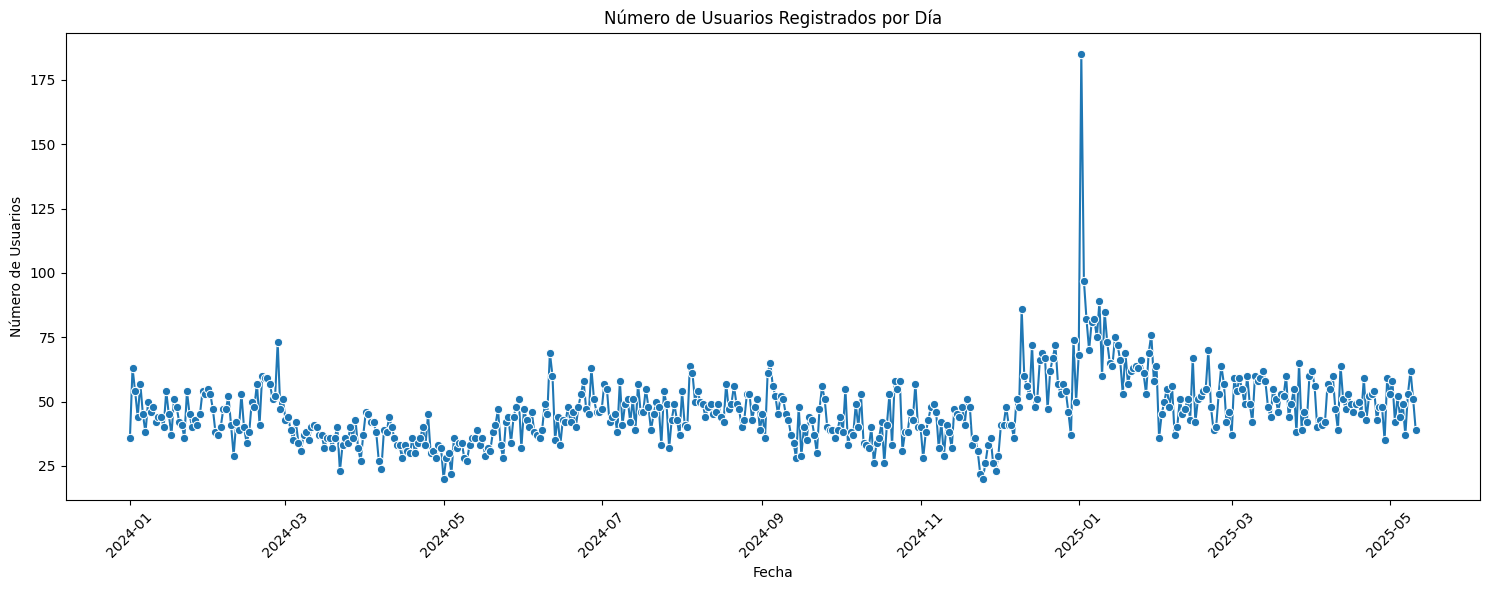

Día con mayor registros: 2025-01-02, Registros: 185
Intervalo de confianza al 95.0%: (45.24, 47.57)


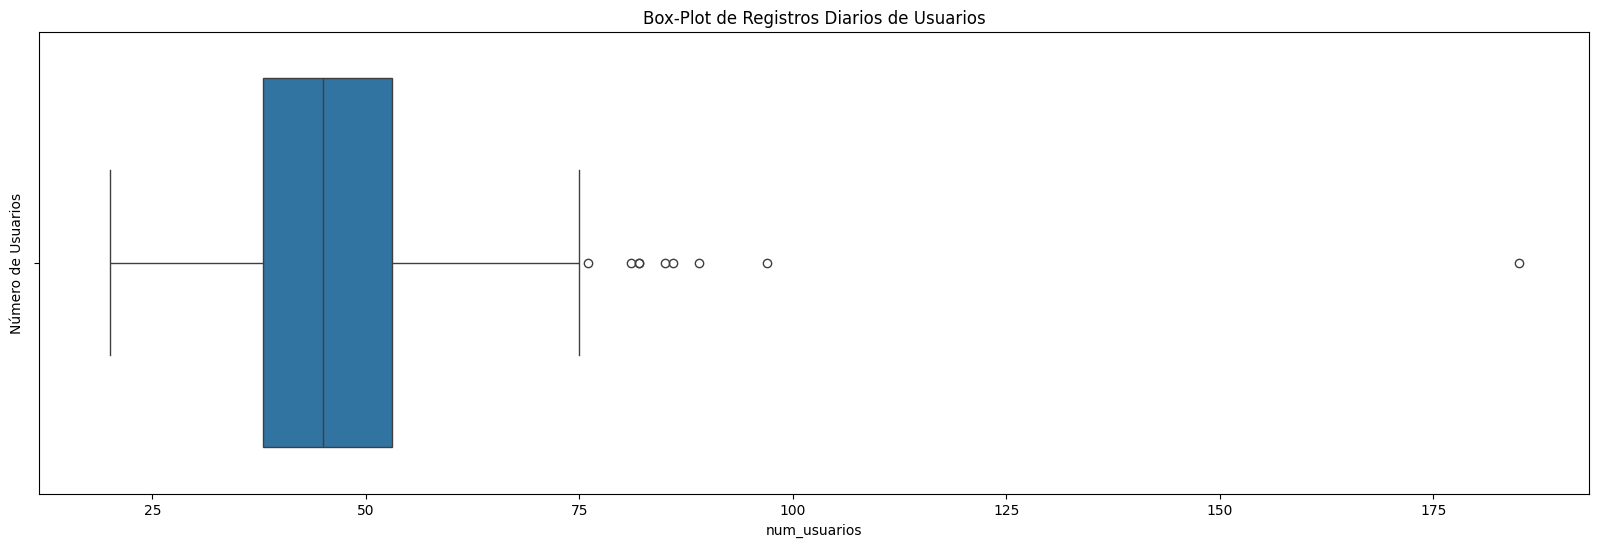

Valores atípicos (días con registros inusuales):
            dia  num_usuarios
344  2024-12-10            86
367  2025-01-02           185
368  2025-01-03            97
369  2025-01-04            82
371  2025-01-06            81
372  2025-01-07            82
374  2025-01-09            89
376  2025-01-11            85
394  2025-01-29            76
Número de valores atípicos: 9


In [ ]:
#codigo 1
import pandas as pd
import json
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
import numpy as np
# Cargar el archivo JSON
with open('userHistory.json') as f:
    data = json.load(f)

# Convertir a DataFrame (tabla)
df = pd.json_normalize(data)


#quitar las filas con balance negativo y 0
datos_limpios = df[df["balance"] > 0].copy()


# Seleccionar solo las columnas numéricas antes de calcular la varianza
datos_limpios_numeric = datos_limpios.select_dtypes(include='number')

print("Estudio limpiando el balance 0 o negativo:")
print(datos_limpios.describe())
varianza_muestral1 = datos_limpios_numeric.var(ddof=1)
#Varianza muestral quitando los de balance 0 o negativo
print("La varianza muestral 1 es:")
print(varianza_muestral1)
print("-------------")
print("-------------")

# Seleccionar solo las columnas numéricas para el DataFrame original antes de calcular la varianza
df_numeric = df.select_dtypes(include='number')
print("Estudio con balance 0 o negativo:")
print(df.describe())
varianza_muestral2 = df_numeric.var(ddof=1)
#Varianza muestral original (sin quitar los balance 0 o negativo)
print("La varianza muestral 2 es:")
print(varianza_muestral2)


df["fecha"] = pd.to_datetime(df["creation._seconds"], unit="s")
# Extraer solo la fecha
df["dia"] = df["fecha"].dt.date

# Contar usuarios por día
usuarios_por_dia = df.groupby("dia").size().reset_index(name="num_usuarios")

print("-------------")
print("Número de usuarios registrados por día:")

print(usuarios_por_dia)
print(usuarios_por_dia.describe())
datos_users_var = usuarios_por_dia["num_usuarios"].var()
print(f"la varianza de los usuarios registrados por días es: {datos_users_var}")

# Configurar el tamaño del gráfico
plt.figure(figsize=(15, 6))

# Gráfico de líneas
sns.lineplot(x="dia", y="num_usuarios", data=usuarios_por_dia, marker="o")

# Personalizar el gráfico
plt.title("Número de Usuarios Registrados por Día")
plt.xlabel("Fecha")
plt.ylabel("Número de Usuarios")
plt.xticks(rotation=45)

# Ajustar el diseño para evitar que las etiquetas se corten
plt.tight_layout()

# Mostrar el gráfico
plt.show()

#Mostar el día con más registros en la plataforma
idx_max = usuarios_por_dia["num_usuarios"].idxmax()
dia_max = usuarios_por_dia.loc[idx_max, "dia"]
valor_max = usuarios_por_dia.loc[idx_max, "num_usuarios"]
print(f"Día con mayor registros: {dia_max}, Registros: {valor_max}")

#cálculo del intervalo de confianza

# Nivel de confianza (95%)
nivel_confianza = 0.95
alpha = 1 - nivel_confianza

media_muestral_users_daily = usuarios_por_dia["num_usuarios"].mean()

desvio_muestral_users_daily = usuarios_por_dia["num_usuarios"].std()
alpha = 0.05

n = len(usuarios_por_dia['num_usuarios'])
valor_critico = stats.t.ppf(1 - alpha/2, df=n-1)
error_estandar = desvio_muestral_users_daily / np.sqrt(n)
margen_error = valor_critico * error_estandar
intervalo_confianza = (media_muestral_users_daily - margen_error, media_muestral_users_daily + margen_error)
print(f"Intervalo de confianza al {nivel_confianza*100}%: ({intervalo_confianza[0]:.2f}, {intervalo_confianza[1]:.2f})")

# Crear el box-plot
plt.figure(figsize=(20, 6))
sns.boxplot(x=usuarios_por_dia["num_usuarios"])
plt.title("Box-Plot de Registros Diarios de Usuarios")
plt.ylabel("Número de Usuarios")
plt.show()

# Calcular Q1, Q3 y IQR
Q1 = usuarios_por_dia["num_usuarios"].quantile(0.25)
Q3 = usuarios_por_dia["num_usuarios"].quantile(0.75)
IQR = Q3 - Q1

# Límites para detectar valores atípicos
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# Identificar valores atípicos
valores_atipicos = usuarios_por_dia[
    (usuarios_por_dia["num_usuarios"] < limite_inferior) |
    (usuarios_por_dia["num_usuarios"] > limite_superior)
][["dia", "num_usuarios"]]
print("Valores atípicos (días con registros inusuales):")
print(valores_atipicos)

# Contar valores atípicos
print(f"Número de valores atípicos: {len(valores_atipicos)}")




# Código 2

164
region
California    1716
New York      1106
Florida        868
England        855
Texas          842
Ontario        517
Illinois       415
Georgia        405
Washington     352
Lagos          345
Name: count, dtype: int64
-----------------------------------
country
United States     9499
Canada            1037
United Kingdom     920
Nigeria            533
Germany            465
Hong Kong          414
Italy              386
India              375
Australia          373
France             308
Name: count, dtype: int64


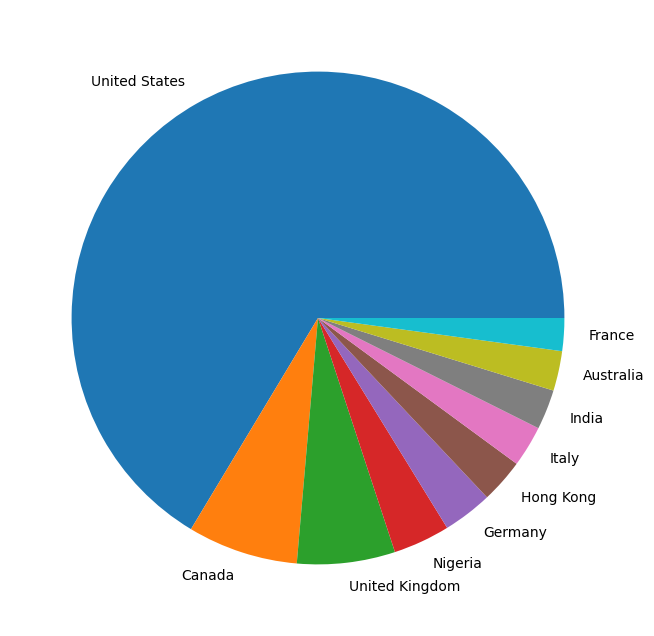

In [ ]:
#codigo 2
import pandas as pd
import json
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
import numpy as np
# Cargar el archivo JSON
with open('/content/privacy.json') as f:
    data = json.load(f)

# Convertir a DataFrame (tabla)
df = pd.json_normalize(data)

#print(df)
#print(df.dtypes)
#print(df.isnull().sum())


paises = df["country"].unique()
#print(paises)
frecuencia_paises = df["country"].value_counts()

print(len(frecuencia_paises))
top_10_paises = frecuencia_paises.head(10)

regiones: str = df["region"].unique()


frecuencia_regiones = df["region"].value_counts()

top_10_regiones = frecuencia_regiones.head(10)

print(top_10_regiones)
print("-----------------------------------")
print(top_10_paises)

import matplotlib.pyplot as plt

# 1. Datos
plt.figure(figsize=(20, 8))


labels = top_10_paises # Etiquetas para cada porción
labels = top_10_paises.index # Etiquetas para cada porción

# 2. Crear el gráfico de tortas
plt.pie(top_10_paises, labels=labels)

# 3. Mostrar el gráfico
plt.show()














#eliminar_duplicados = df.drop_duplicates()
#print(df.describe())

# Código 3

-------------
Número de ingresos por día:
            dia  ingresos_dia
0    2024-01-01         19.45
1    2024-01-02         77.10
2    2024-01-03         63.35
3    2024-01-04         59.21
4    2024-01-05         56.15
..          ...           ...
492  2025-05-07        277.16
493  2025-05-08         64.23
494  2025-05-09         60.24
495  2025-05-10         42.29
496  2025-05-11         38.11

[497 rows x 2 columns]
Top 10 días con mayor número de ingresos:
            dia  ingresos_dia
30   2024-01-31       1076.03
362  2024-12-28        729.34
69   2024-03-10        444.16
59   2024-02-29        396.16
376  2025-01-11        365.09
117  2024-04-27        338.48
439  2025-03-15        334.53
220  2024-08-08        328.38
66   2024-03-07        325.71
255  2024-09-12        316.22
       ingresos_dia
count    497.000000
mean     111.582216
std       82.530593
min       12.440000
25%       63.780000
50%       93.230000
75%      141.040000
max     1076.030000
La varianza de los ing

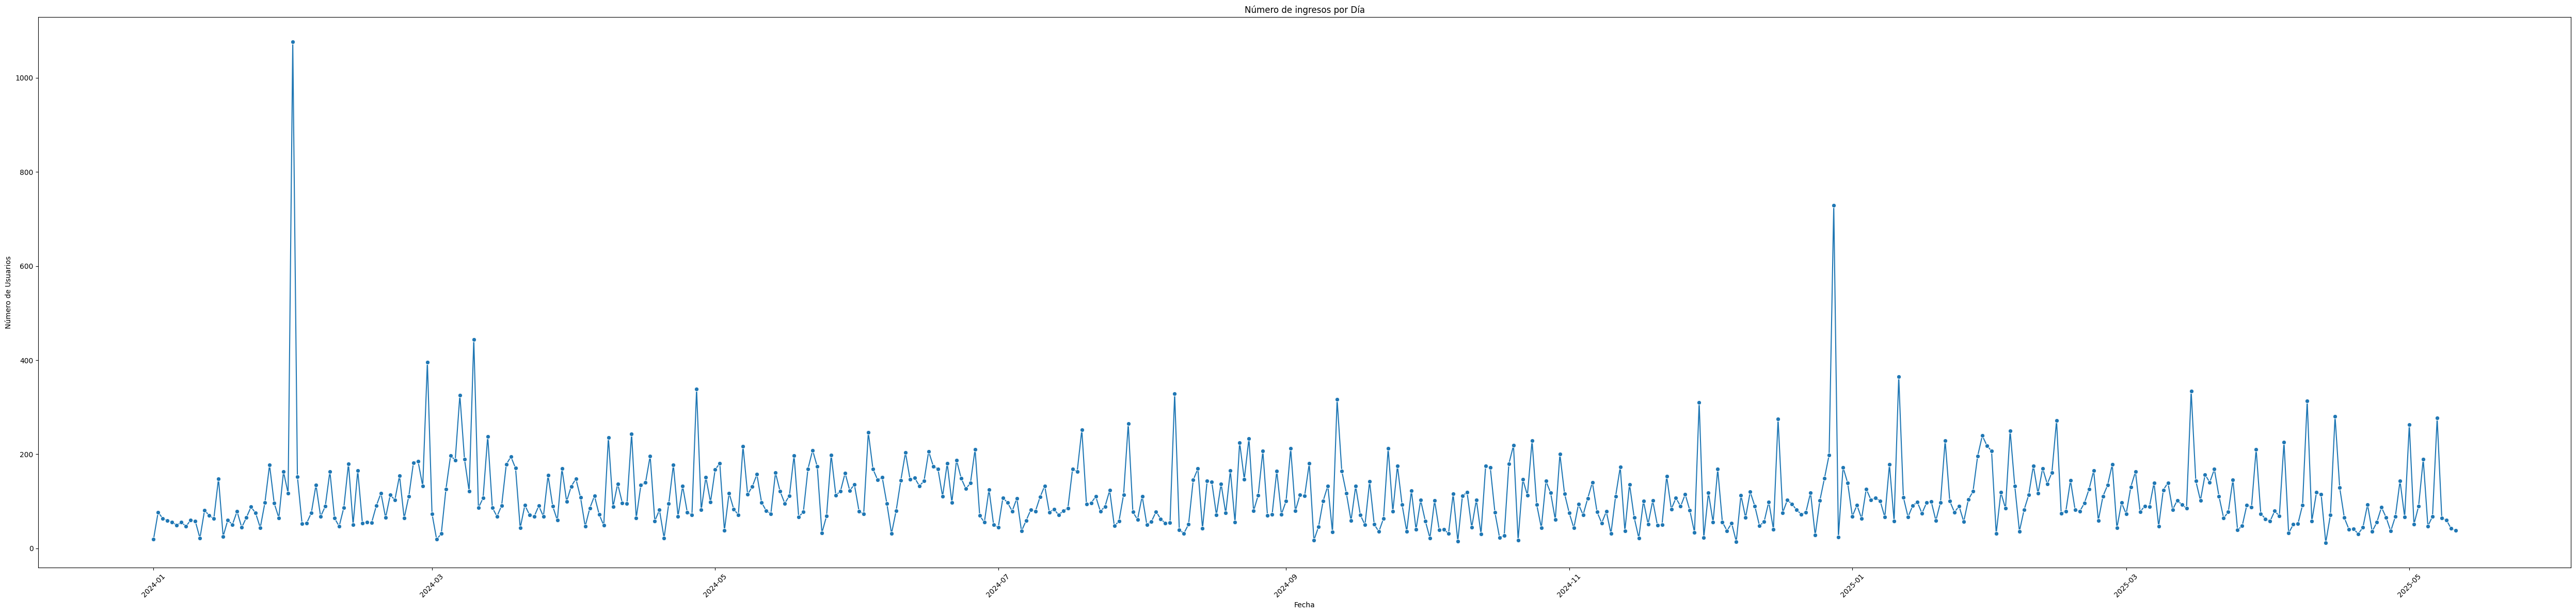

-------------
       ingresos_mes
count     17.000000
mean    3262.138913
std      674.581819
min     1190.910000
25%     3130.140000
50%     3352.970000
75%     3577.950000
max     4075.881500
La varianza de los ingresos mensuales es: 455060.6300504788
Intervalo de confianza al 95.0%: (2915.30, 3608.98)
Mes con más ingresos: 2024-03, Ingresos: 4075.8815


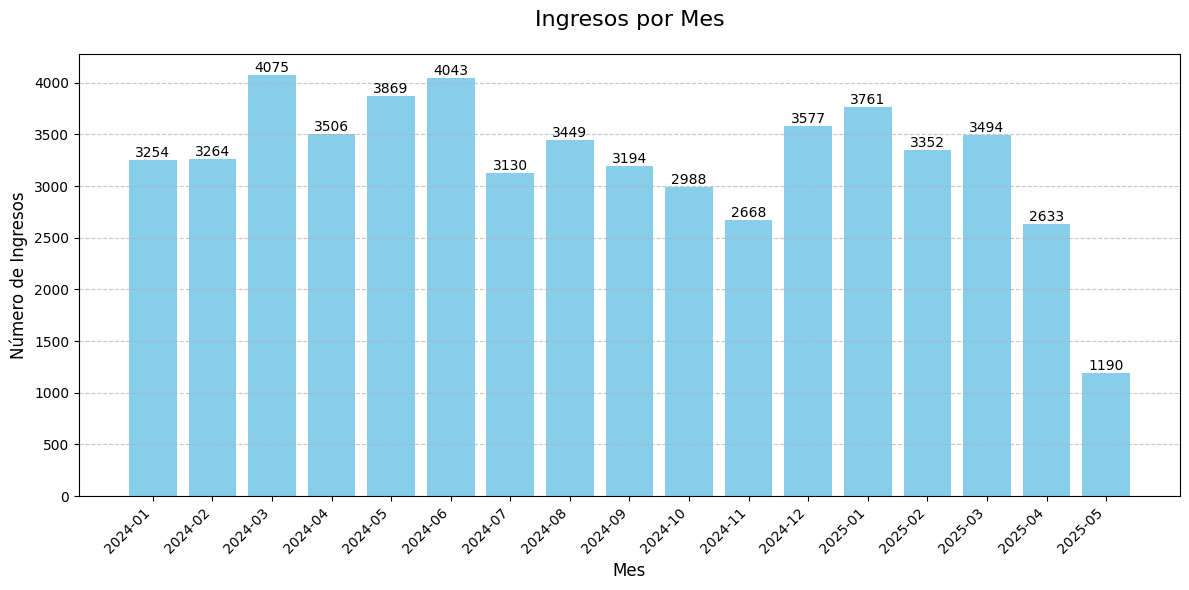

Top 10 países por ingresos:


,country,amount
121,United States,22238.860000
119,United Arab Emirates,2445.820000
22,Canada,2192.840000
120,United Kingdom,1597.920000
81,Nigeria,1404.860000
83,Oman,1390.840000
84,Pakistan,1143.890000
24,Colombia,1104.230000
40,Germany,993.330026
30,Dominican Republic,971.510000


             amount
count     10.000000
mean    3548.410003
std     6585.886439
min      971.510000
25%     1114.145000
50%     1397.850000
75%     2044.110000
max    22238.860000


,country,mean,var,std
0,Canada,6.301264,74.414286,8.626372
1,Colombia,11.383814,134.484970,11.596765
2,Dominican Republic,15.420794,374.652569,19.355944
3,Germany,7.821496,408.296298,20.206343
4,Nigeria,4.517235,38.555950,6.209344
5,Oman,49.672857,156.994969,12.529763
6,Pakistan,29.330513,12307.546073,110.939380
7,United Arab Emirates,38.822540,365.717587,19.123744
8,United Kingdom,6.217588,136.575314,11.686544
9,United States,6.308896,111.438536,10.556445


La correlación lineal entre los registros diarios y los ingresos diarios es: 0.07

Prueba de hipótesis para la correlación de Pearson:
Coeficiente de correlación (r): 0.07
P-valor: 0.1440
Como el p-valor (0.1440) es mayor que el nivel de significancia (0.05), no rechazamos la hipótesis nula.
No hay suficiente evidencia estadística para concluir que hay una correlación lineal significativa entre los registros diarios y los ingresos diarios.


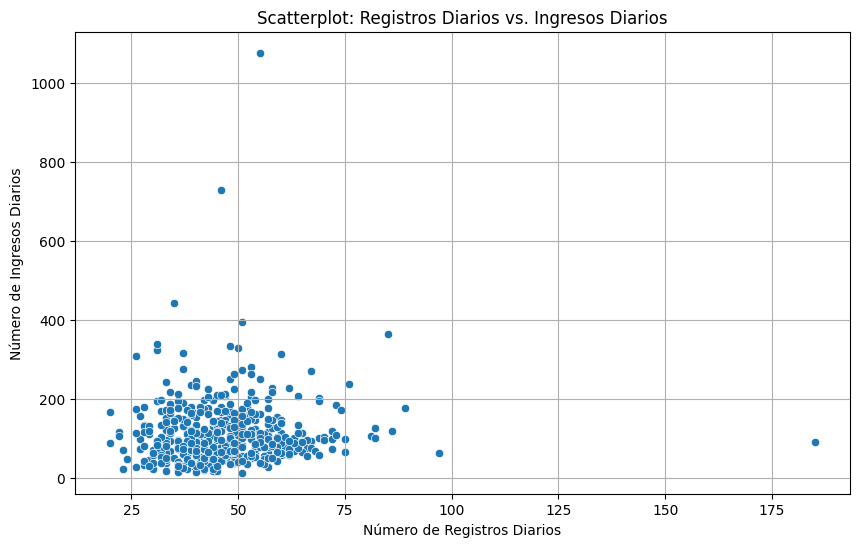

La correlación lineal entre los registros mensuales y los ingresos mensuales son: 0.52

Prueba de hipótesis para la correlación de Pearson:
Coeficiente de correlación (r): 0.52
P-valor: 0.0313
Como el p-valor (0.0313) es menor que el nivel de significancia (0.05), rechazamos la hipótesis nula.
Existe evidencia estadística para concluir que hay una correlación lineal significativa entre los registros mensuales y los ingresos mensuales.


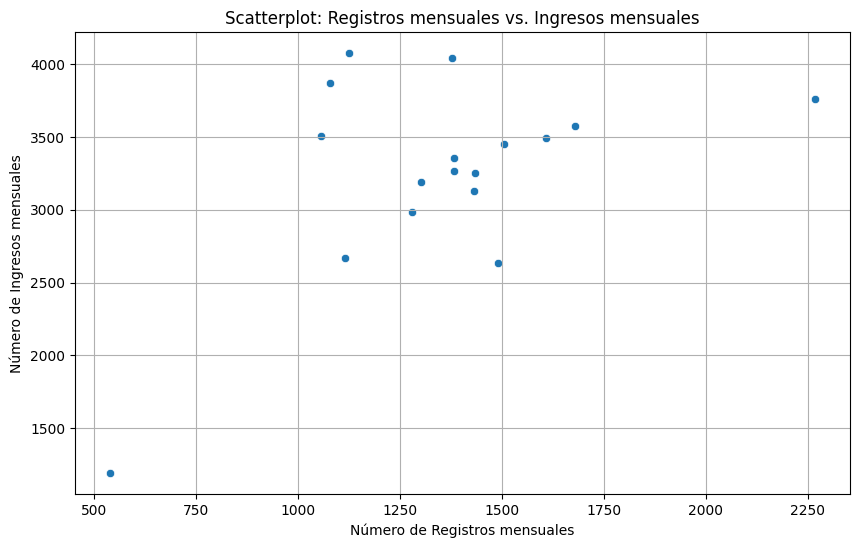

In [ ]:
#Código 3
import pandas as pd
import json
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
import numpy as np
from scipy.stats import pearsonr

# Cargar el primer archivo JSON
with open('rechargeHistory.json', 'r', encoding='utf-8') as f:
    data = json.load(f)

# Cargar el segundo archivo JSON
with open('privacy.json', 'r', encoding='utf-8') as f2:
    data2 = json.load(f2)

# Cargar el tercer archivo JSON
with open('userHistory.json', 'r', encoding='utf-8') as f3:
    data3 = json.load(f3)


# Convertir a DataFrame (tabla)
df = pd.json_normalize(data)
df2 = pd.json_normalize(data2)
df3 = pd.json_normalize(data3)



# Filtrar el DataFrame (utilizar nada mas status: "Completed", "Admin update", "Overpayment", "Underpayment")
# Usamos .isin() para filtrar por múltiples valores en la columna 'status'
df_filtrado = df[df['status'].isin(["Completed", "Admin update", "Overpayment", "Underpayment"])].copy()


# Convertir la columna 'amount' a numérico en el DataFrame
df_filtrado["amount"] = df_filtrado["amount"].astype(float)


df_filtrado = df_filtrado.dropna(subset=['amount']).copy()


# Combinar los DataFrames usando 'uid' como clave
df_merged = pd.merge(df_filtrado, df2, on='uid', how='inner')



# Convertir la columna 'amount' a numérico en el DataFrame combinado
# 'errors='coerce'' convertirá los valores no numéricos a NaN
df_merged['amount'] = pd.to_numeric(df_merged['amount'], errors='coerce')

# Eliminar filas donde 'amount' es NaN después de la conversión
df_merged = df_merged.dropna(subset=['amount'])

# Convertir timestamp a fecha en df
df_filtrado["fecha"] = pd.to_datetime(df_filtrado["timestamp._seconds"], unit="s")
# Extraer solo la fecha
df_filtrado["dia"] = df_filtrado["fecha"].dt.date

# Contar usuarios por día en df
ingresos_por_dia = df_filtrado.groupby("dia")["amount"].sum().reset_index(name="ingresos_dia")

print("-------------")
print("Número de ingresos por día:")
print(ingresos_por_dia)


# Ordenar el DataFrame por la columna 'ingresos_dia' de forma descendente
top_10_ingresos_diarios = ingresos_por_dia.sort_values(by='ingresos_dia', ascending=False).head(10)

# Imprimir el top 10
print("Top 10 días con mayor número de ingresos:")
print(top_10_ingresos_diarios)

print(ingresos_por_dia.describe())
datos_users_var = ingresos_por_dia["ingresos_dia"].var()
print(f"La varianza de los ingresos diarios es: {datos_users_var}")

# cálculo del intervalo de confianza para ingresos diarios
nivel_confianza = 0.95
alpha = 1 - nivel_confianza

media_muestral_users_daily = ingresos_por_dia["ingresos_dia"].mean()
desvio_muestral_users_daily = ingresos_por_dia["ingresos_dia"].std()
alpha = 0.05

n = len(ingresos_por_dia['ingresos_dia'])
valor_critico = stats.t.ppf(1 - alpha/2, df=n-1)
error_estandar = desvio_muestral_users_daily / np.sqrt(n)
margen_error = valor_critico * error_estandar
intervalo_confianza = (media_muestral_users_daily - margen_error, media_muestral_users_daily + margen_error)
print(f"Intervalo de confianza al {nivel_confianza*100}%: ({intervalo_confianza[0]:.2f}, {intervalo_confianza[1]:.2f})")

idx_max_dia = ingresos_por_dia["ingresos_dia"].idxmax()
dia_max = ingresos_por_dia.loc[idx_max_dia, "dia"]
valor_max_dia = ingresos_por_dia.loc[idx_max_dia, "ingresos_dia"]
print(f"Día con mayor ingresos: {dia_max}, Ingresos: {valor_max_dia}")

# Gráfico de líneas

plt.figure(figsize=(50, 12))


sns.lineplot(x="dia", y="ingresos_dia", data=ingresos_por_dia, marker="o")

# Personalizar el gráfico
plt.title("Número de ingresos por Día")
plt.xlabel("Fecha")
plt.ylabel("Número de Usuarios")
plt.xticks(rotation=45)

# Ajustar el diseño para evitar que las etiquetas se corten
plt.tight_layout()

# Mostrar el gráfico
plt.show()

# Convertir a datetime y extraer el periodo mensual (ej: "2023-01") en df
df_filtrado["mes"] = df_filtrado["fecha"].dt.to_period('M').copy()

# Contar ingresos por mes en df
ingresos_por_mes = df_filtrado.groupby("mes")["amount"].sum().reset_index(name="ingresos_mes")

print("-------------")
print(ingresos_por_mes.describe())
datos_users_var2 = ingresos_por_mes["ingresos_mes"].var()
print(f"La varianza de los ingresos mensuales es: {datos_users_var2}")

# cálculo del intervalo de confianza para ingresos mensuales
nivel_confianza = 0.95
alpha = 1 - nivel_confianza

media_muestral_users_monthly = ingresos_por_mes["ingresos_mes"].mean()
desvio_muestral_users_monthly = ingresos_por_mes["ingresos_mes"].std()
alpha = 0.05

n = len(ingresos_por_mes['ingresos_mes'])
valor_critico = stats.t.ppf(1 - alpha/2, df=n-1)
# Ahora usamos el desvío estándar mensual para el error estándar del intervalo de confianza mensual
error_estandar = desvio_muestral_users_monthly / np.sqrt(n)
margen_error = valor_critico * error_estandar
intervalo_confianza = (media_muestral_users_monthly - margen_error, media_muestral_users_monthly + margen_error)
print(f"Intervalo de confianza al {nivel_confianza*100}%: ({intervalo_confianza[0]:.2f}, {intervalo_confianza[1]:.2f})")

# Encontrar el mes con más ingresos
idx_max = ingresos_por_mes["ingresos_mes"].idxmax()
mes_max = ingresos_por_mes.loc[idx_max, "mes"]
valor_max = ingresos_por_mes.loc[idx_max, "ingresos_mes"]
print(f"Mes con más ingresos: {mes_max}, Ingresos: {valor_max}")

# 4. Crear el gráfico de barras
plt.figure(figsize=(12, 6))  # Tamaño del gráfico (ancho, alto)
# Use the index for the x-axis positions and the 'mes' column for the tick labels
bars = plt.bar(ingresos_por_mes.index, ingresos_por_mes["ingresos_mes"], color='skyblue')

# 5. Personalizar el gráfico
plt.title("Ingresos por Mes", fontsize=16, pad=20)
plt.xlabel("Mes", fontsize=12)
plt.ylabel("Número de Ingresos", fontsize=12)
# Set the x-axis tick locations to the index and labels to the 'mes' values
plt.xticks(ingresos_por_mes.index, ingresos_por_mes["mes"].astype(str), rotation=45, ha='right') # Asegúrate de que 'mes' sea string para las etiquetas
plt.grid(axis='y', linestyle='--', alpha=0.7)  # Líneas de grid horizontales

# 6. Añadir etiquetas de valor en cada barra
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{int(height)}',
             ha='center', va='bottom', fontsize=10)

plt.tight_layout()  # Ajustar márgenes
plt.show()

# Calculo paises top ingresos usando df_merged
# Sumar ingresos por país
df_country_amount = df_merged.groupby('country')['amount'].sum().reset_index()

# Ordenar de mayor a menor
df_top10 = df_country_amount.sort_values('amount', ascending=False).head(10)

print("Top 10 países por ingresos:")
display(df_top10[['country', 'amount']])

print(df_top10.describe())



df_top10_countries_transactions = df_merged[df_merged['country'].isin(df_top10['country'])].copy()

# agrupar por country y calcular la media y varianza del amount por cada pais
mean_variance_per_country = df_top10_countries_transactions.groupby('country')['amount'].agg(['mean', 'var', "std"]).reset_index()



display(mean_variance_per_country)





# correlacion registros diarios vs. ingresos diarios

# Convertir creation a fecha en df3
df3["fecha"] = pd.to_datetime(df3["creation._seconds"], unit="s")
# Extraer solo la fecha
df3["dia"] = df3["fecha"].dt.date

# Contar usuarios por día en df3
registros_por_dia = df3.groupby("dia").size().reset_index(name="registro_diario")

# Combinar los DataFrames por la columna 'dia'
df_correlacion = pd.merge(registros_por_dia, ingresos_por_dia, on='dia', how='inner')

# Calcular la correlación de Pearson
# La correlación se calculará entre 'registro_diario' e 'ingresos_dia'
correlacion = df_correlacion['registro_diario'].corr(df_correlacion['ingresos_dia'])

print(f"La correlación lineal entre los registros diarios y los ingresos diarios es: {correlacion:.2f}")


# prueba de eficacia

# Asegurarse de que no haya NaNs en las columnas que usaremos para la prueba
df_correlacion_clean = df_correlacion.dropna(subset=['registro_diario', 'ingresos_dia'])

# Realizar la prueba de Pearson
correlation_coefficient, p_value = pearsonr(df_correlacion_clean['registro_diario'], df_correlacion_clean['ingresos_dia'])

print(f"\nPrueba de hipótesis para la correlación de Pearson:")
print(f"Coeficiente de correlación (r): {correlation_coefficient:.2f}")
print(f"P-valor: {p_value:.4f}")

# Interpretar el resultado
alpha = 0.05 # Nivel de significancia
if p_value < alpha:
    print(f"Como el p-valor ({p_value:.4f}) es menor que el nivel de significancia ({alpha}), rechazamos la hipótesis nula.")
    print("Existe evidencia estadística para concluir que hay una correlación lineal significativa entre los registros diarios y los ingresos diarios.")
else:
    print(f"Como el p-valor ({p_value:.4f}) es mayor que el nivel de significancia ({alpha}), no rechazamos la hipótesis nula.")
    print("No hay suficiente evidencia estadística para concluir que hay una correlación lineal significativa entre los registros diarios y los ingresos diarios.")

# Scatterplot para visualizar la relación
plt.figure(figsize=(10, 6))
sns.scatterplot(x='registro_diario', y='ingresos_dia', data=df_correlacion_clean)
plt.title("Scatterplot: Registros Diarios vs. Ingresos Diarios")
plt.xlabel("Número de Registros Diarios")
plt.ylabel("Número de Ingresos Diarios")
plt.grid(True)
plt.show()


# correlacion registros mensuales vs. ingresos mensuales


# Convertir a datetime y extraer el periodo mensual (ej: "2023-01") en df3
df3["mes"] = df3["fecha"].dt.to_period('M').copy()

# Contar ingresos por mes en df3
registros_por_mes = df3.groupby("mes").size().reset_index(name="registros_mes")

# Combinar los DataFrames por la columna 'dia'
df_correlacion2 = pd.merge(registros_por_mes, ingresos_por_mes, on='mes', how='inner')

# Calcular la correlación de Pearson
# La correlación se calculará entre 'registro_mes' e 'ingresos_mes'
correlacion2 = df_correlacion2['registros_mes'].corr(df_correlacion2['ingresos_mes'])

print(f"La correlación lineal entre los registros mensuales y los ingresos mensuales son: {correlacion2:.2f}")


# prueba de eficacia

# Asegurarse de que no haya NaNs en las columnas que usaremos para la prueba
df_correlacion_clean2 = df_correlacion2.dropna(subset=['registros_mes', 'ingresos_mes'])

# Realizar la prueba de Pearson
correlation_coefficient1, p_value2 = pearsonr(df_correlacion_clean2['registros_mes'], df_correlacion_clean2['ingresos_mes'])

print(f"\nPrueba de hipótesis para la correlación de Pearson:")
print(f"Coeficiente de correlación (r): {correlation_coefficient1:.2f}")
print(f"P-valor: {p_value2:.4f}")

# Interpretar el resultado
alpha2 = 0.05 # Nivel de significancia
if p_value2 < alpha2: # Corrected condition to use p_value2 and alpha2
    print(f"Como el p-valor ({p_value2:.4f}) es menor que el nivel de significancia ({alpha2}), rechazamos la hipótesis nula.")
    print("Existe evidencia estadística para concluir que hay una correlación lineal significativa entre los registros mensuales y los ingresos mensuales.") # Corrected description
else:
    print(f"Como el p-valor ({p_value2:.4f}) es mayor que el nivel de significancia ({alpha2}), no rechazamos la hipótesis nula.")
    print("No hay suficiente evidencia estadística para concluir que hay una correlación lineal significativa entre los registros mensuales y los ingresos mensuales.") # Corrected description

# Scatterplot para visualizar la relación
plt.figure(figsize=(10, 6))
sns.scatterplot(x='registros_mes', y='ingresos_mes', data=df_correlacion_clean2)
plt.title("Scatterplot: Registros mensuales vs. Ingresos mensuales")
plt.xlabel("Número de Registros mensuales")
plt.ylabel("Número de Ingresos mensuales")
plt.grid(True)
plt.show()




# Código 4

paymentMethod
Amazon Pay      2041
Cryptomus       1247
Admin update    1075
Binance          747
USDT Tron        482
Ethereum         357
USDC Polygon     174
Coinbase         168
Matic            120
Payeer            92
Perfectmoney      77
BTC Lighting      20
Name: count, dtype: int64
   paymentMethod  recargas_por_metodo
0   Admin update                 1075
1     Amazon Pay                 2041
2   BTC Lighting                   20
3        Binance                  747
4       Coinbase                  168
5      Cryptomus                 1247
6       Ethereum                  357
7          Matic                  120
8         Payeer                   92
9   Perfectmoney                   77
10  USDC Polygon                  174
11     USDT Tron                  482


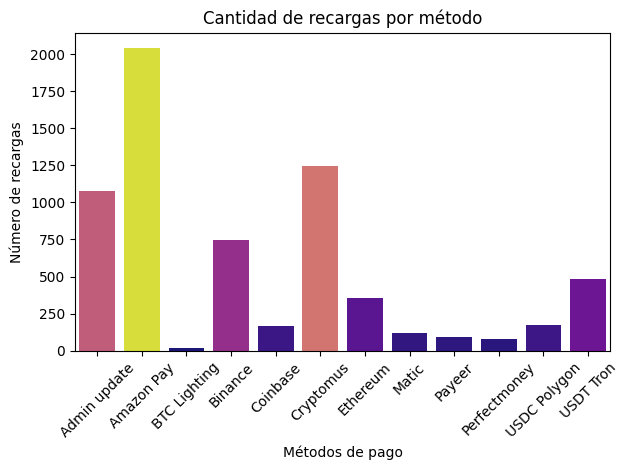

   paymentMethod  monto_por_metodo
0   Admin update       7545.851500
1     Amazon Pay       8287.330000
2   BTC Lighting        115.860000
3        Binance       3412.290026
4       Coinbase       2057.910000
5      Cryptomus      12580.020000
6       Ethereum       3948.150000
7          Matic        582.900000
8         Payeer        382.090000
9   Perfectmoney       1325.420000
10  USDC Polygon        994.390000
11     USDT Tron       9568.180000


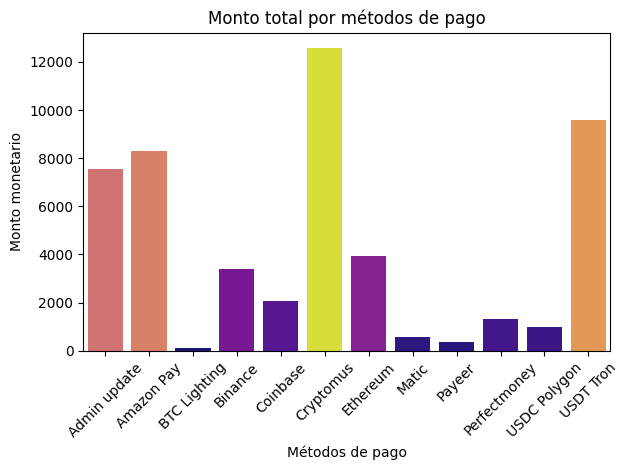

-------------
-------------
-------------


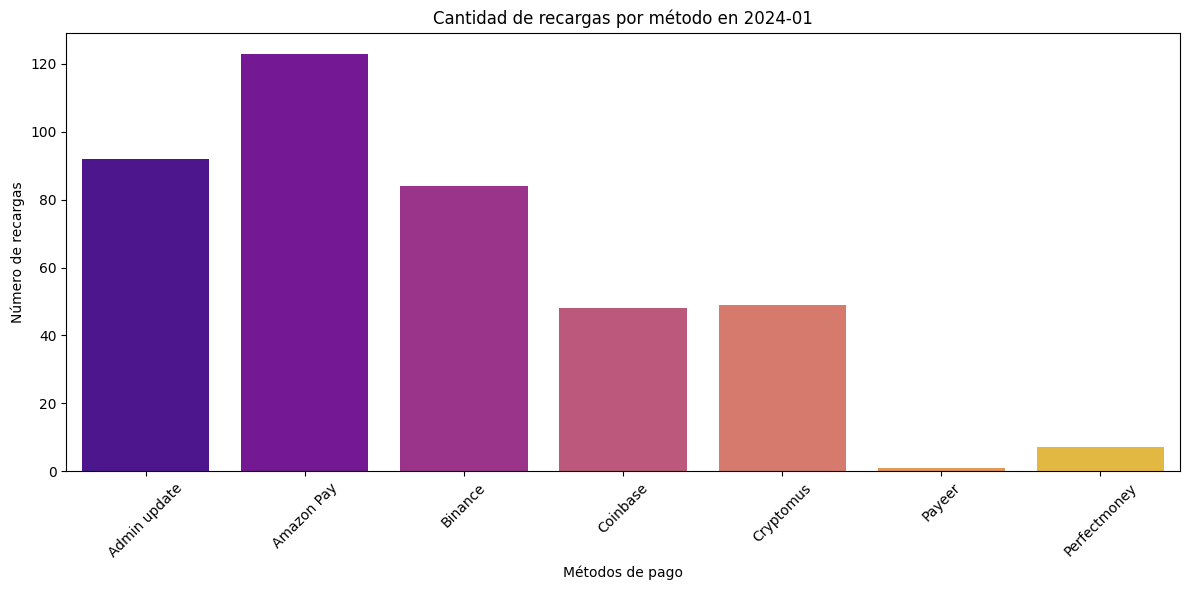

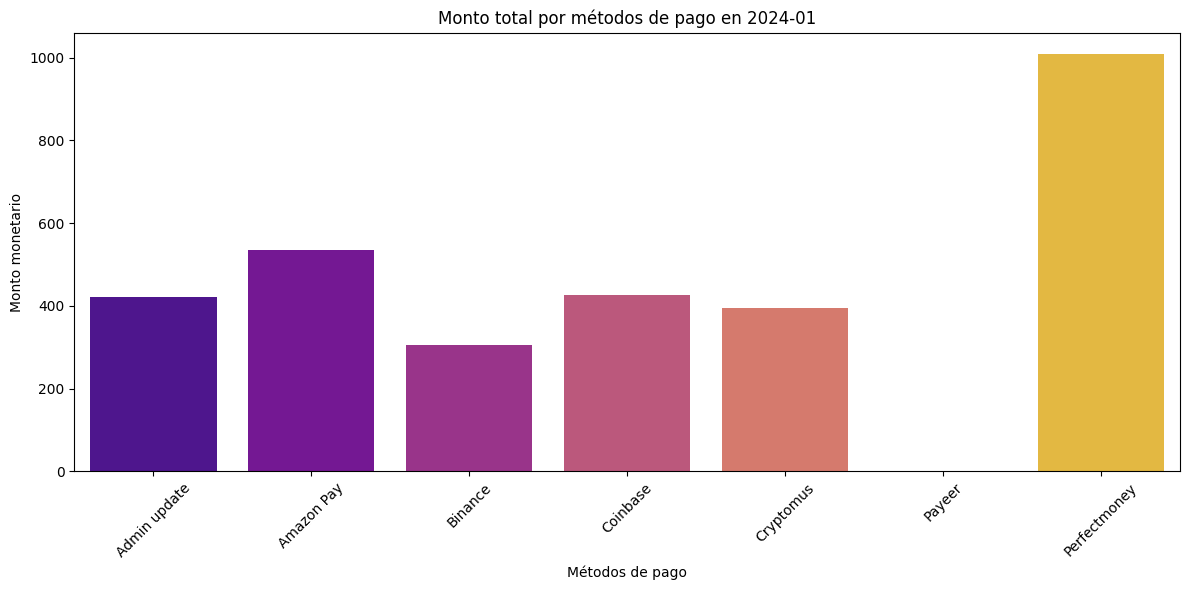

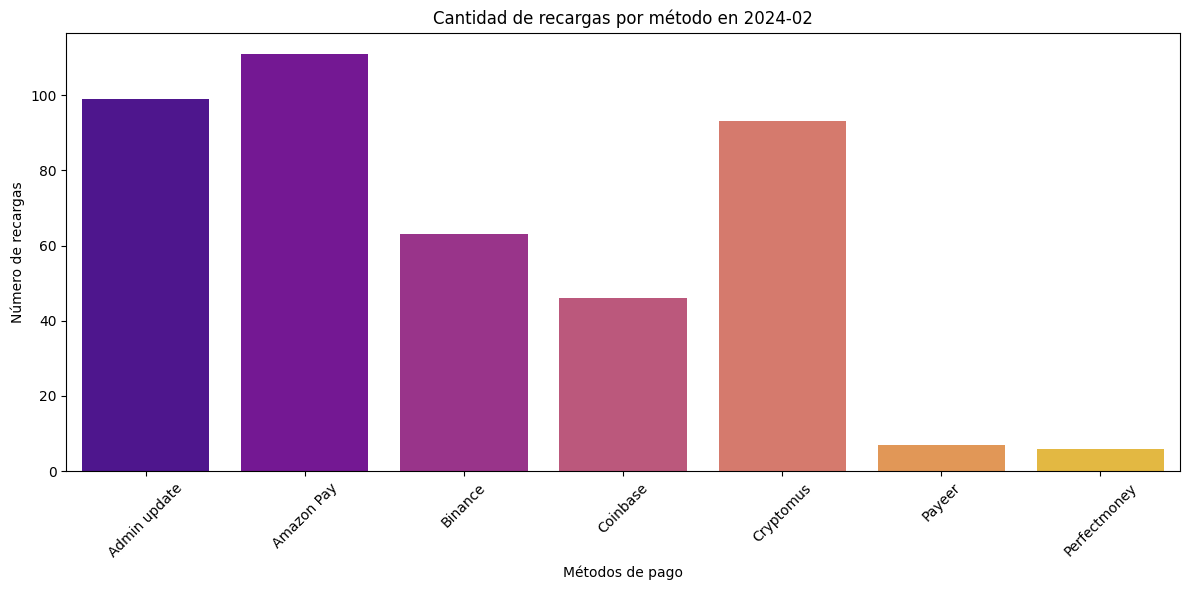

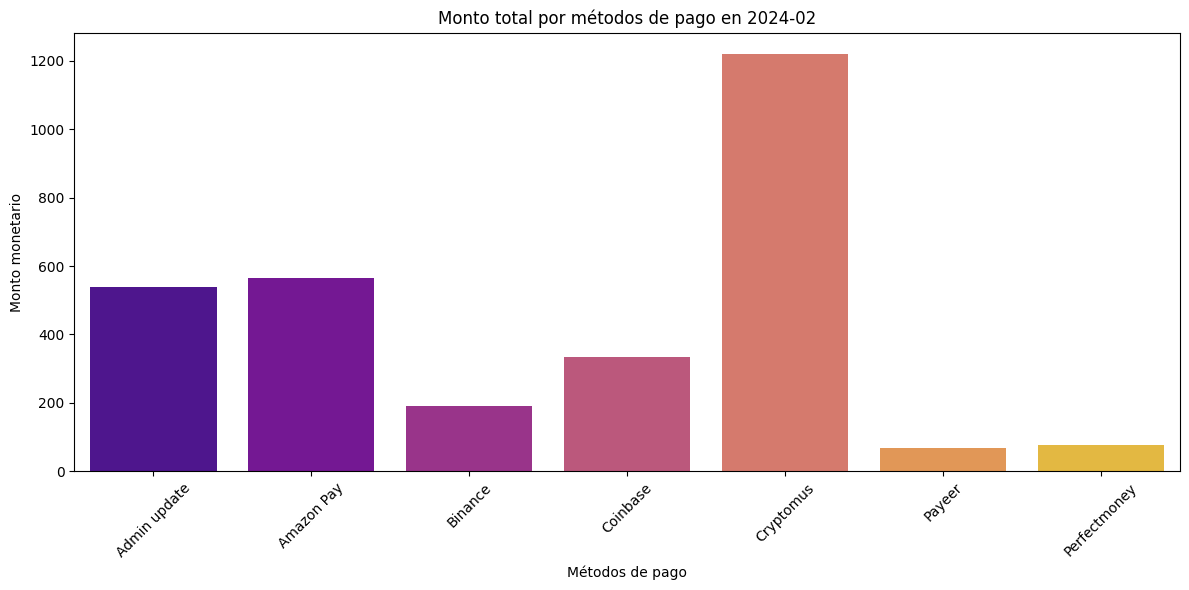

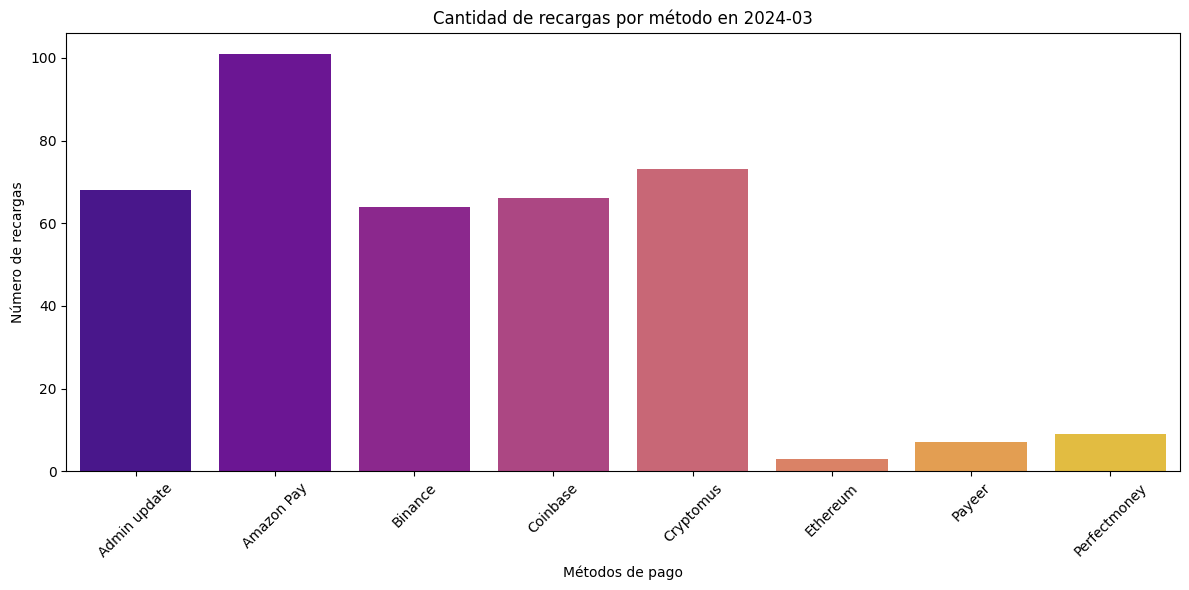

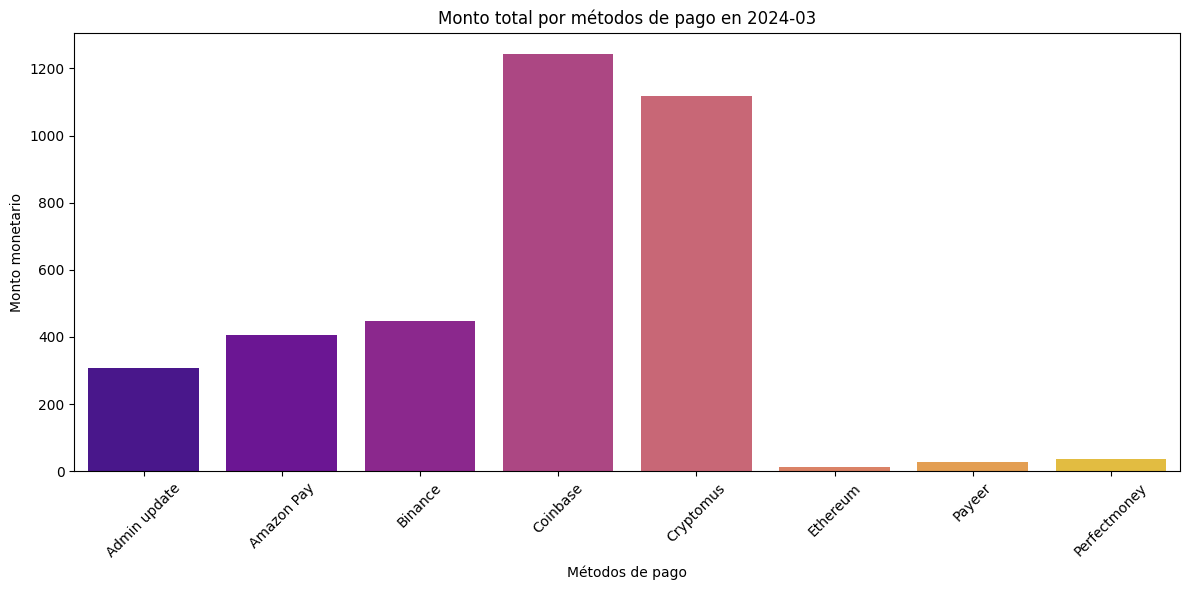

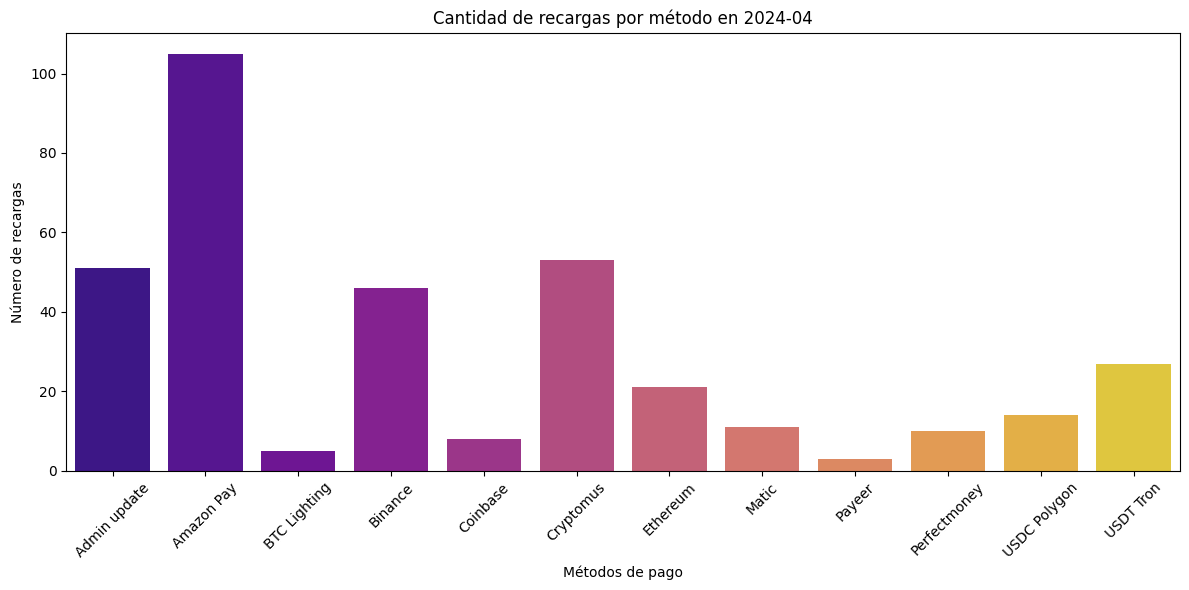

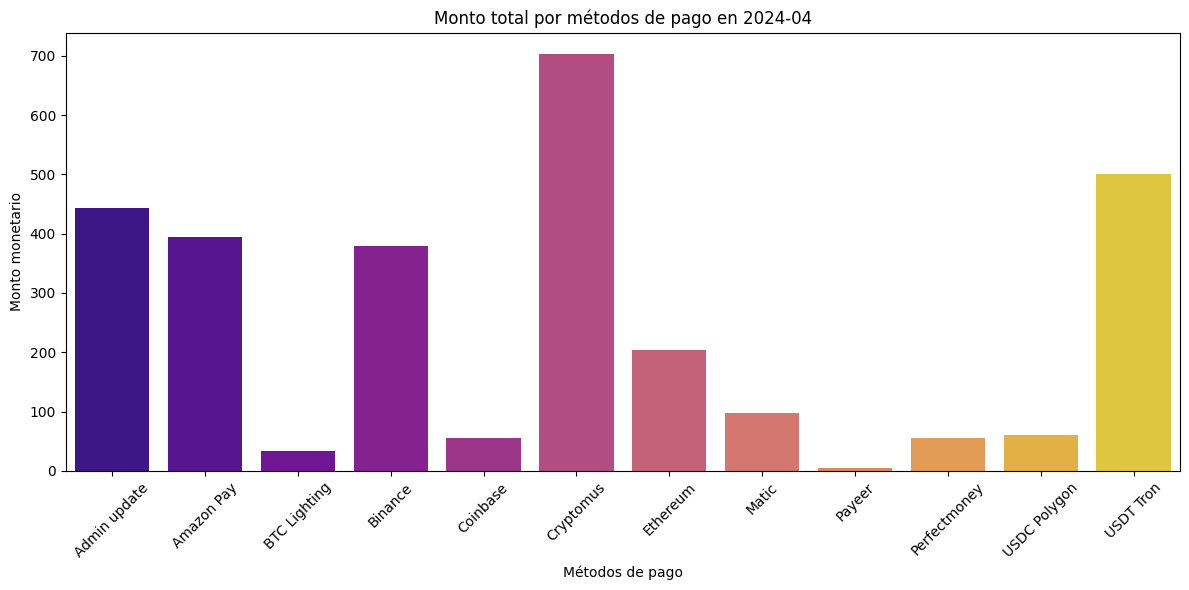

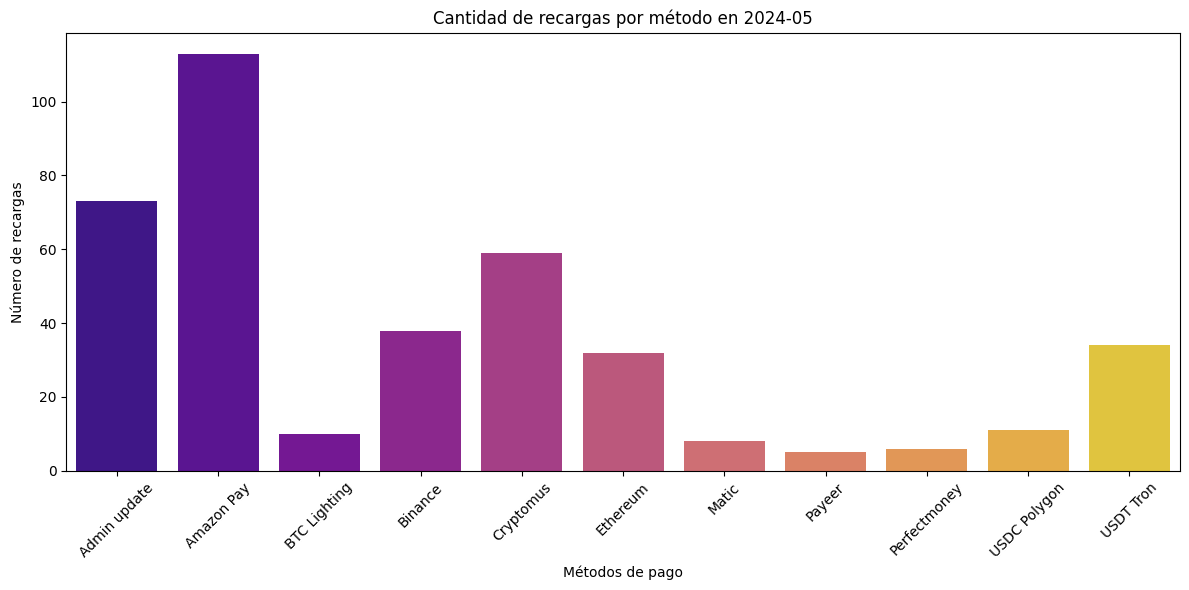

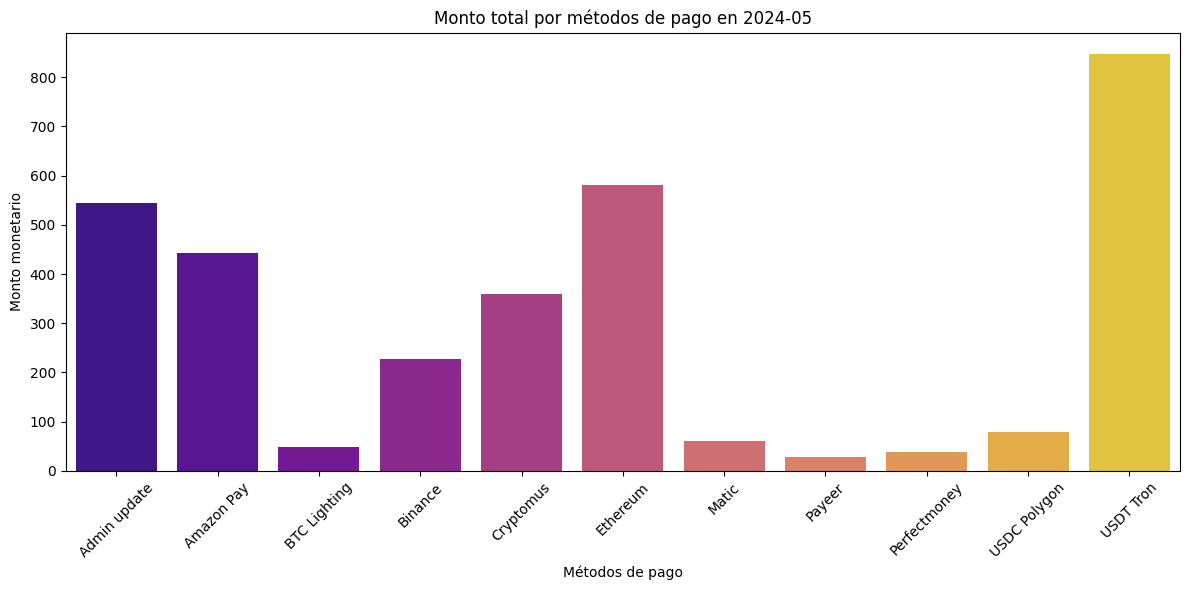

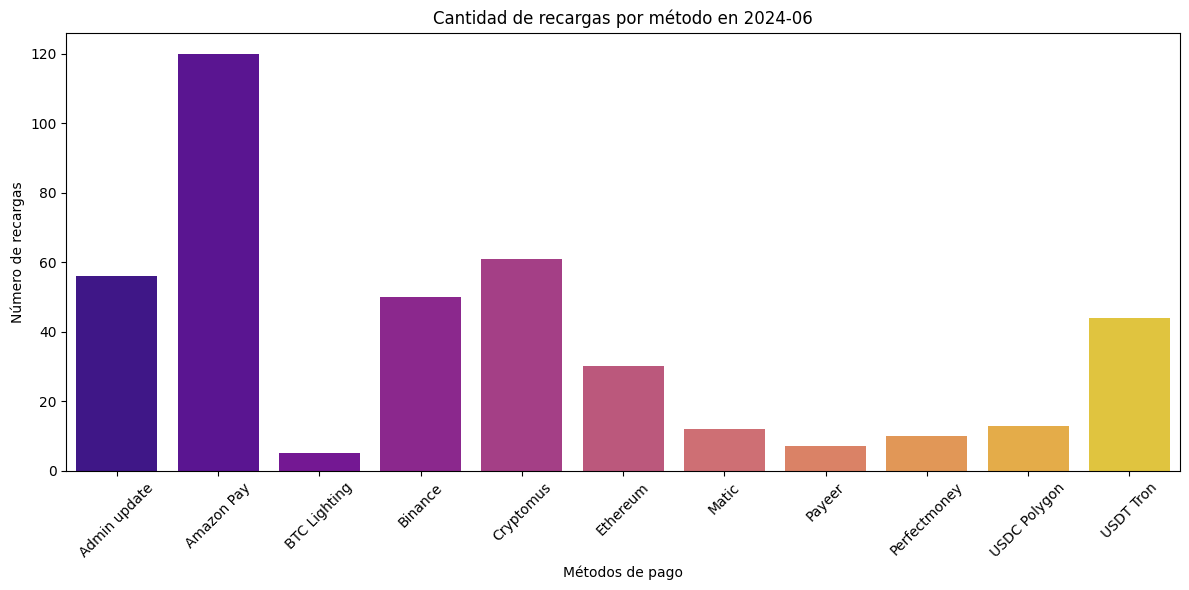

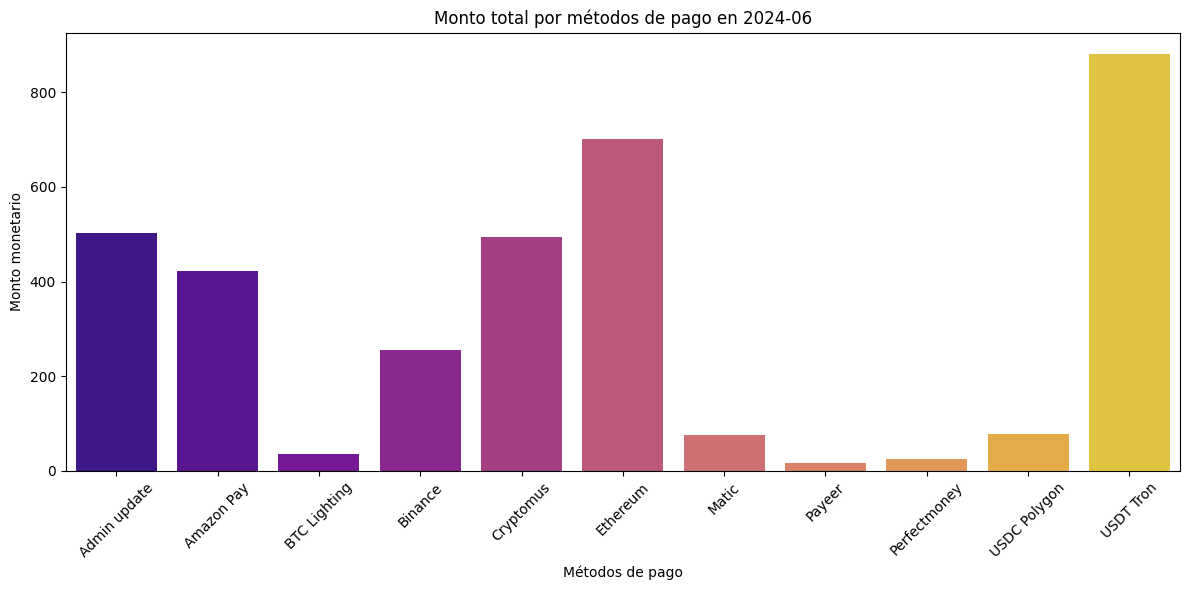

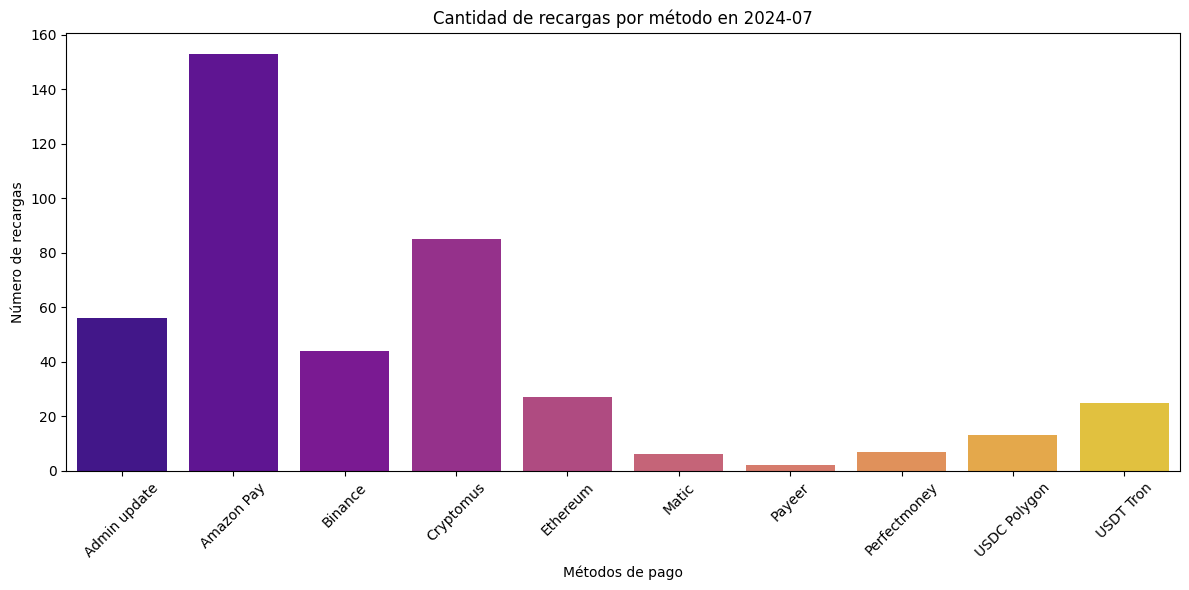

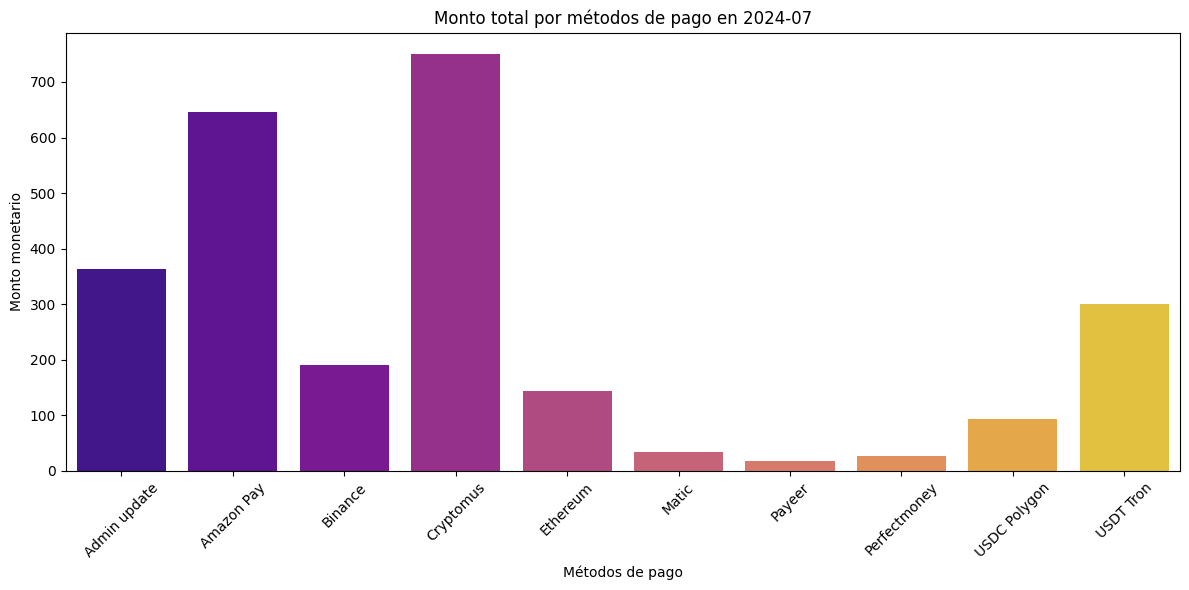

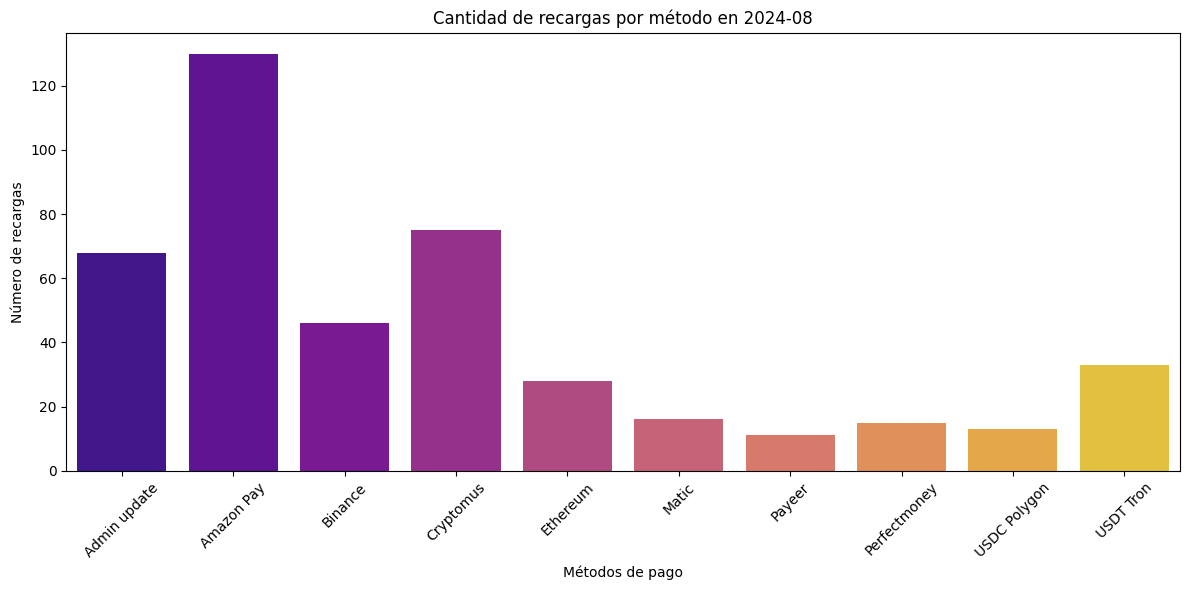

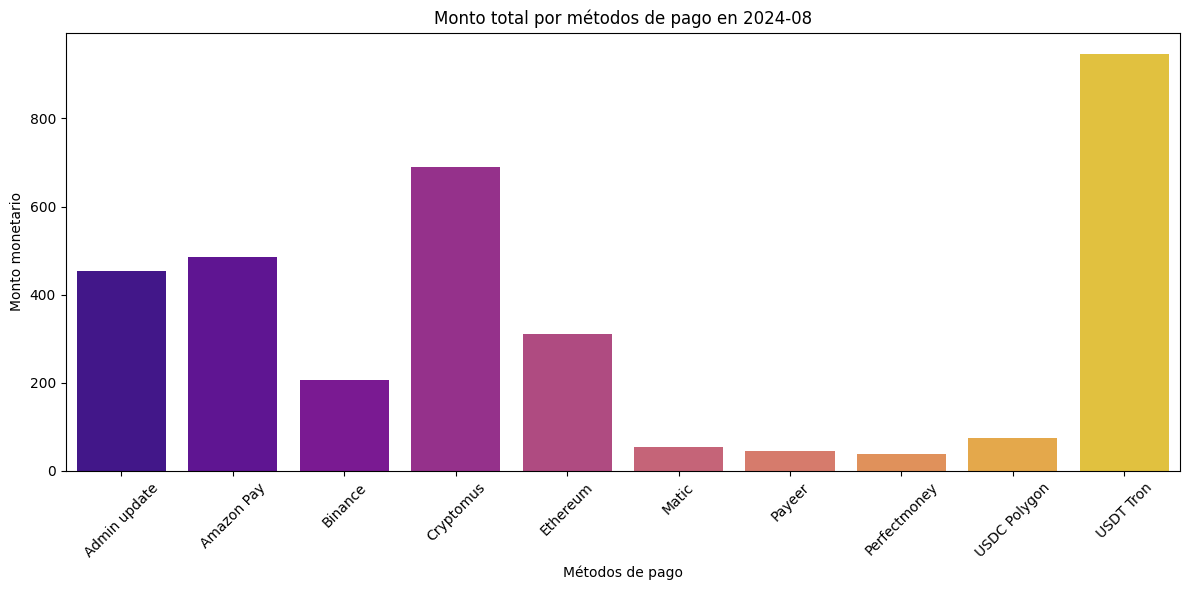

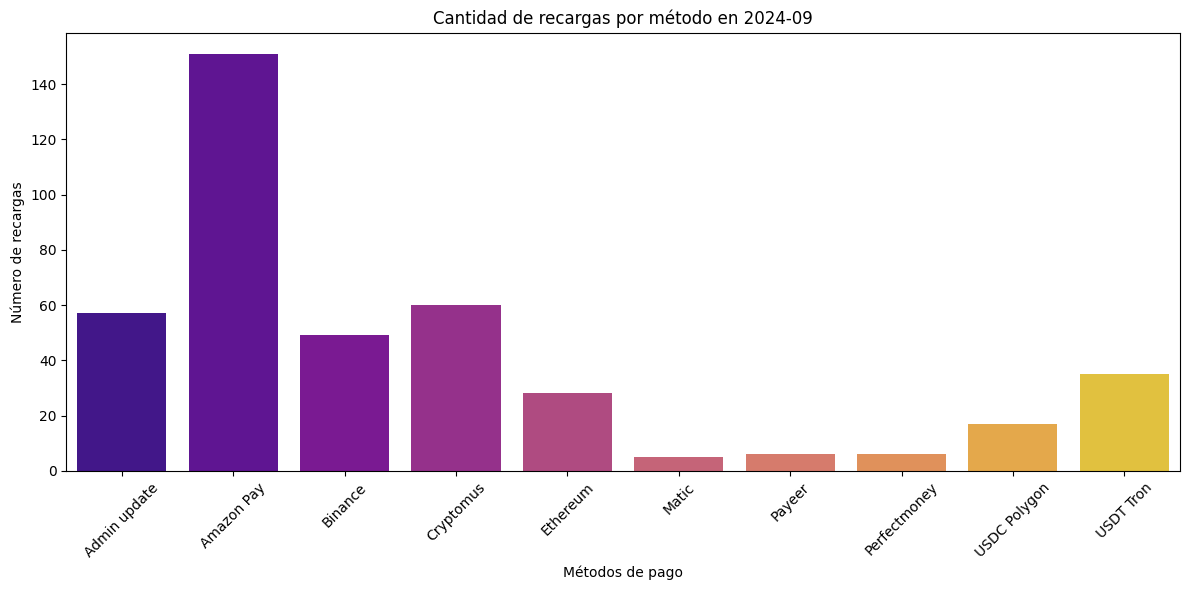

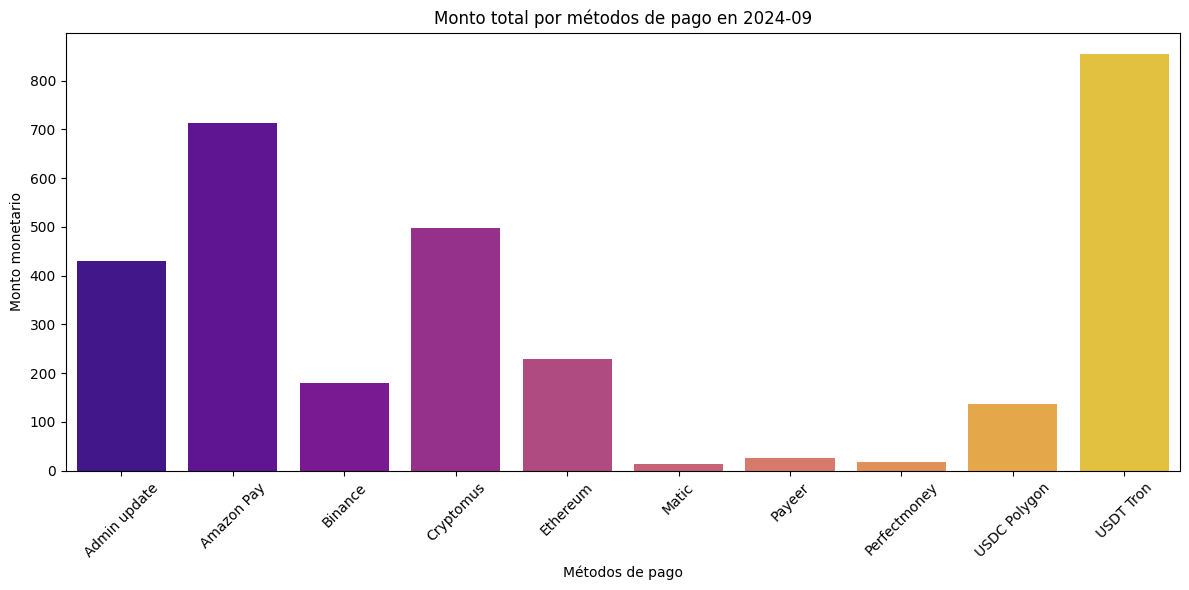

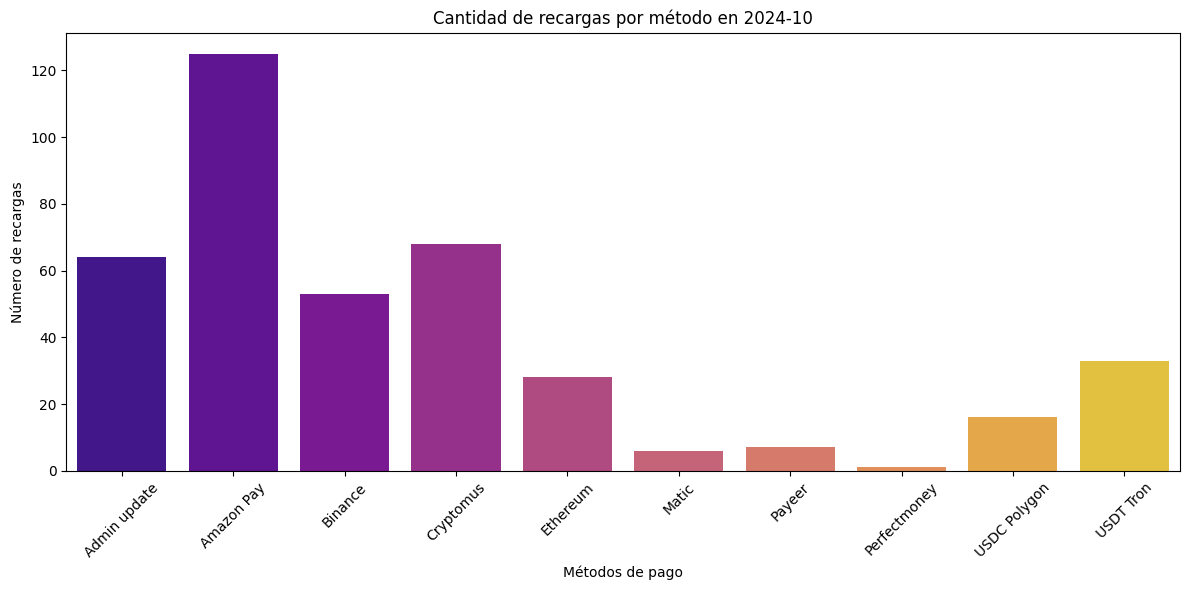

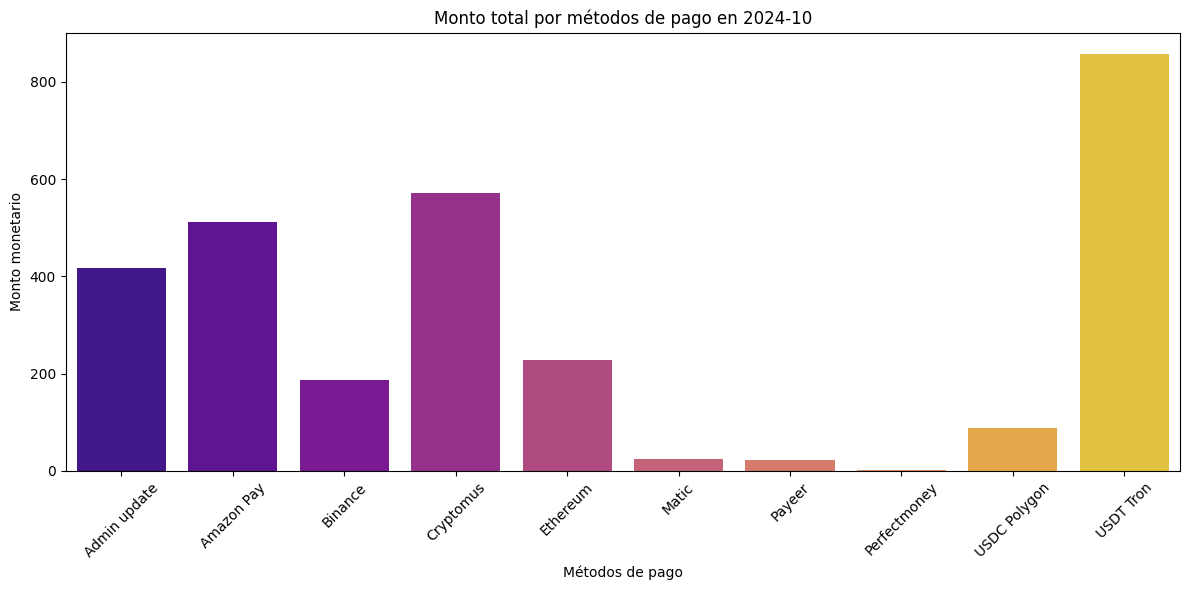

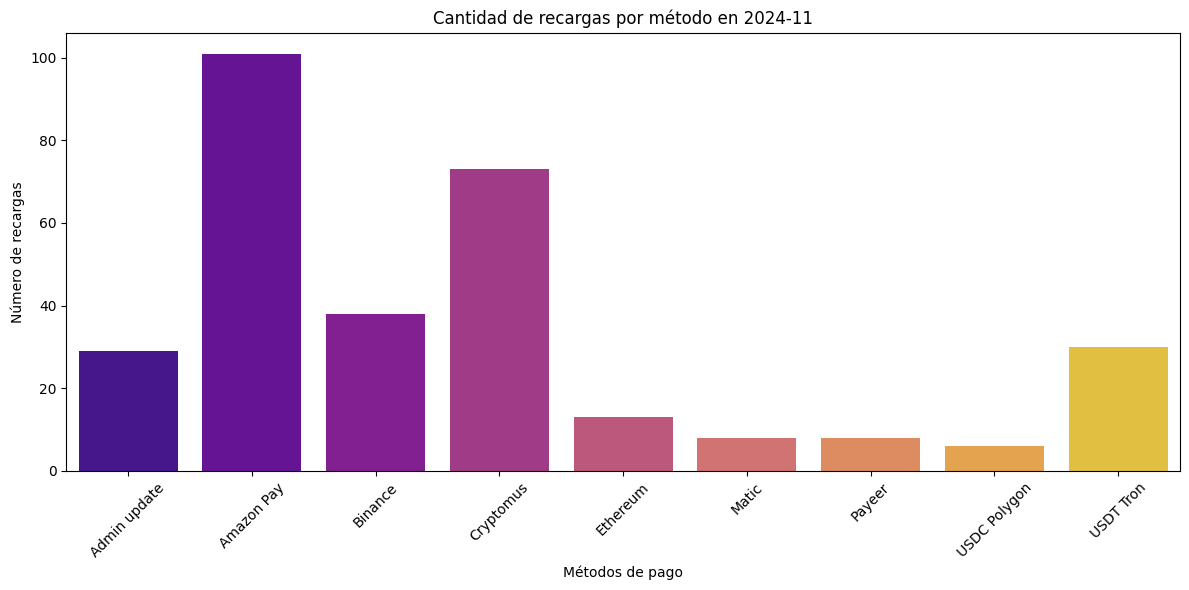

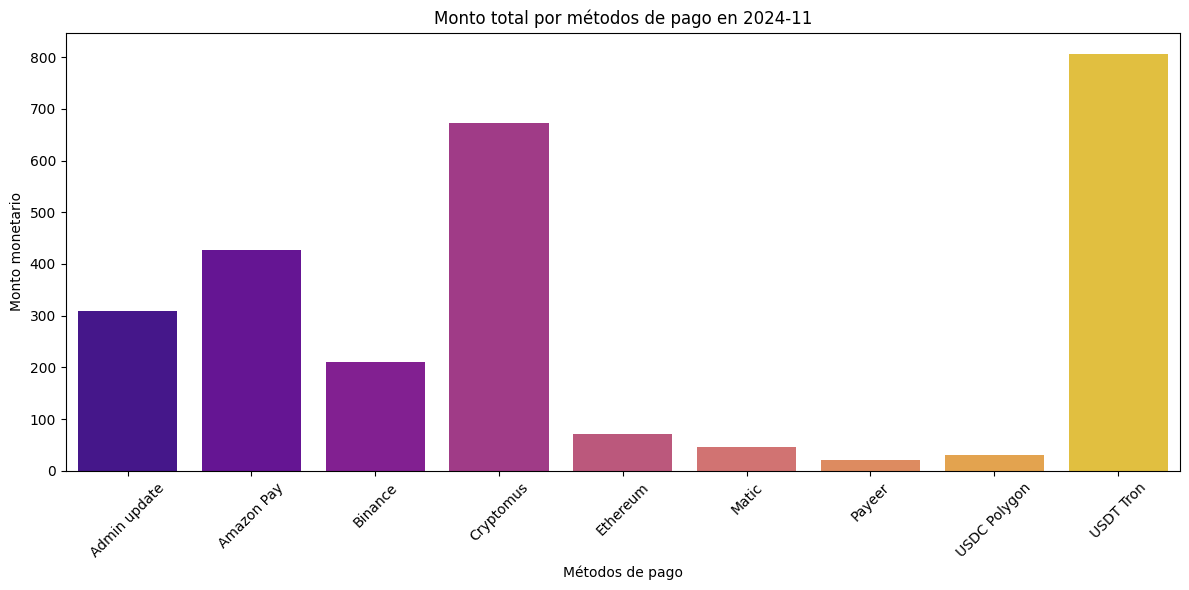

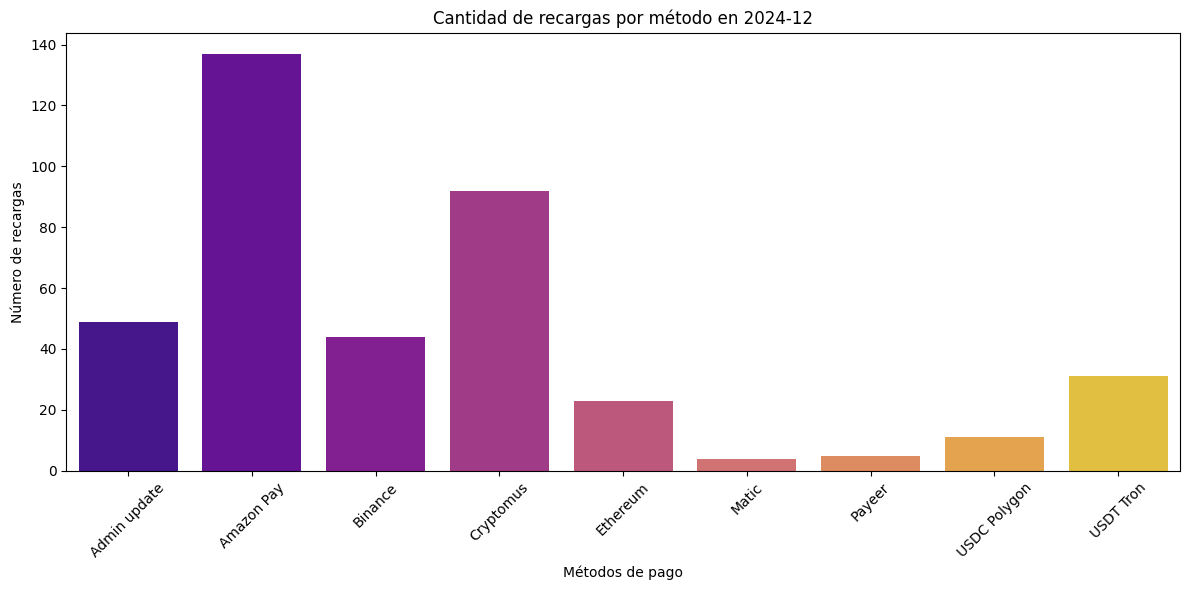

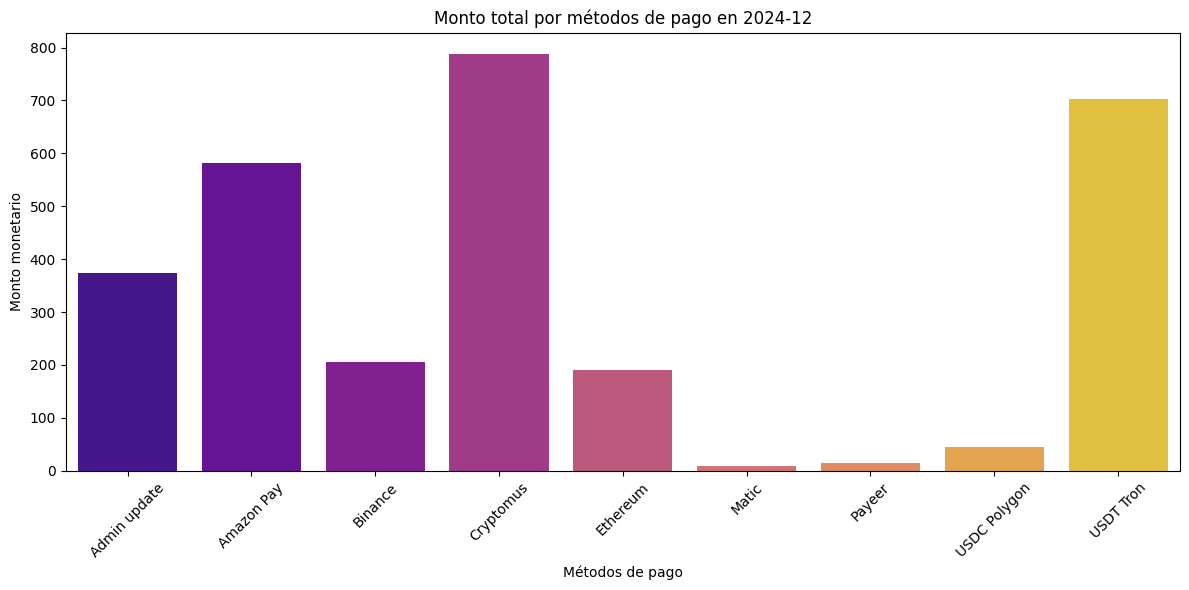

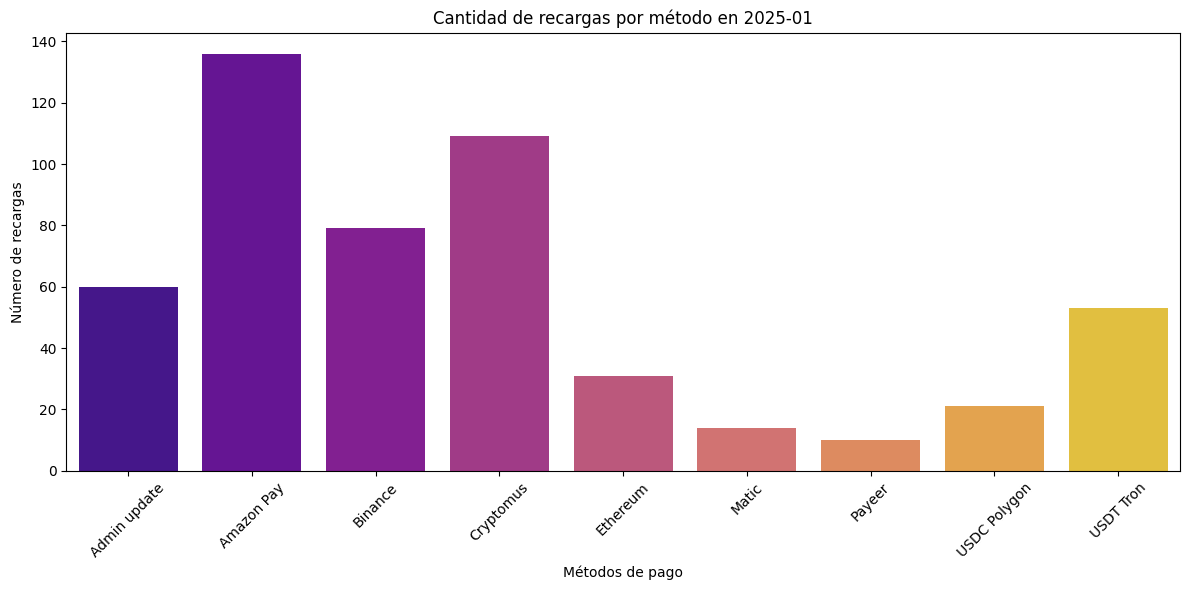

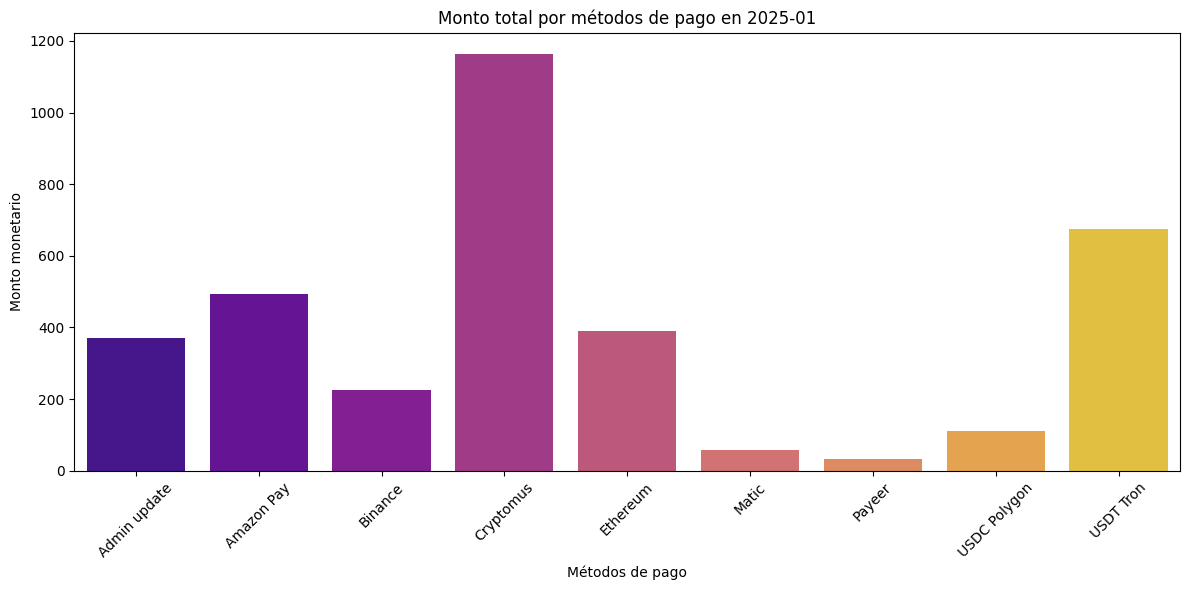

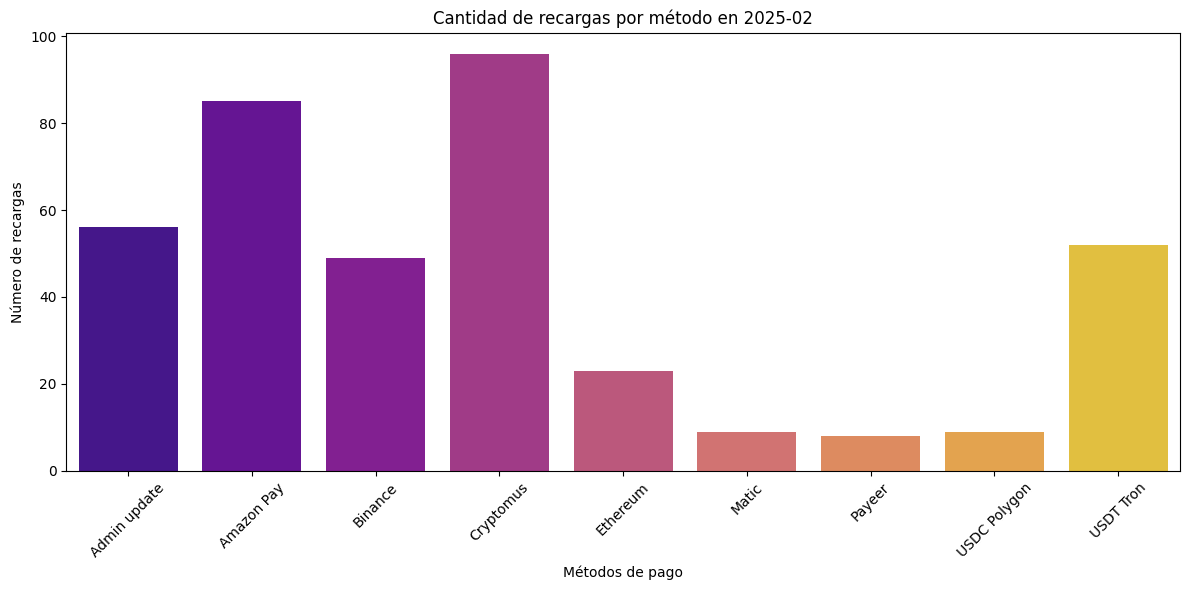

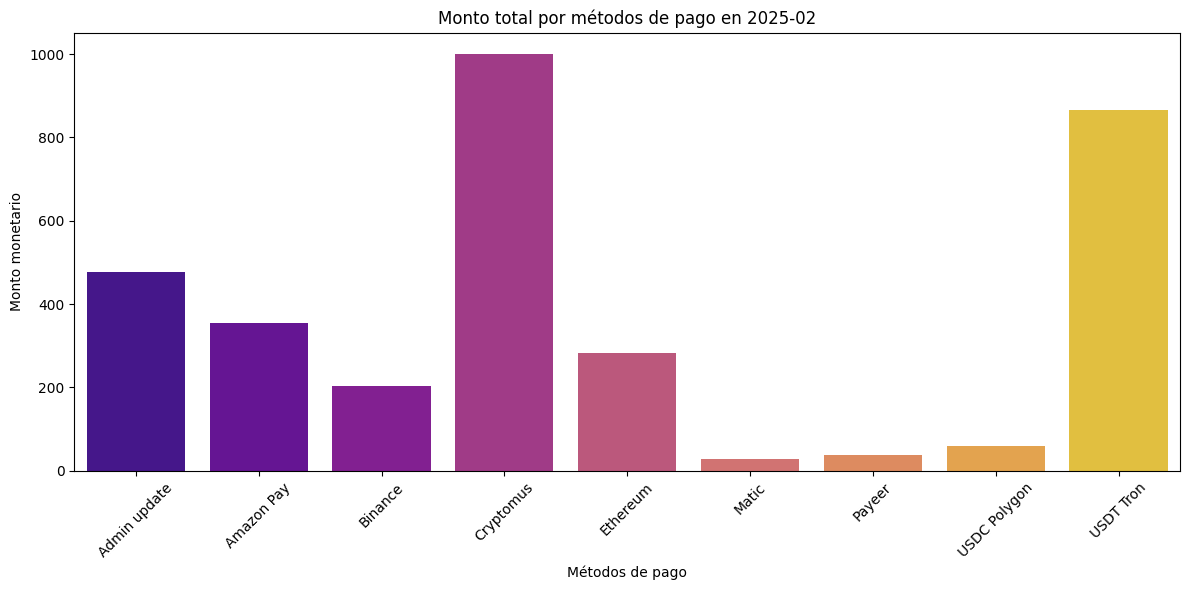

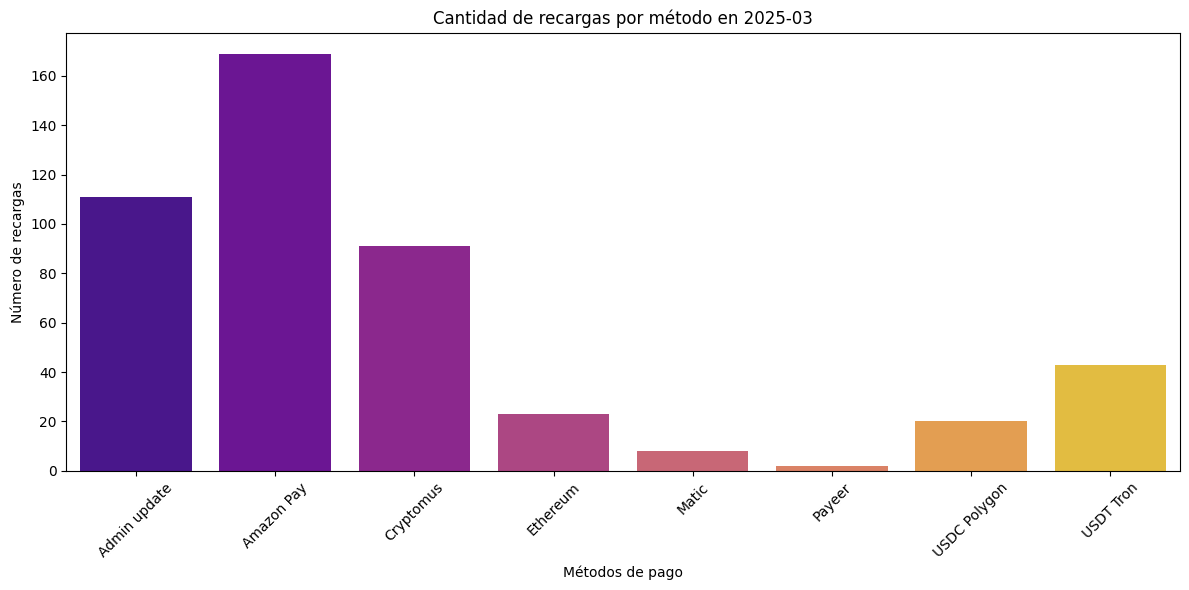

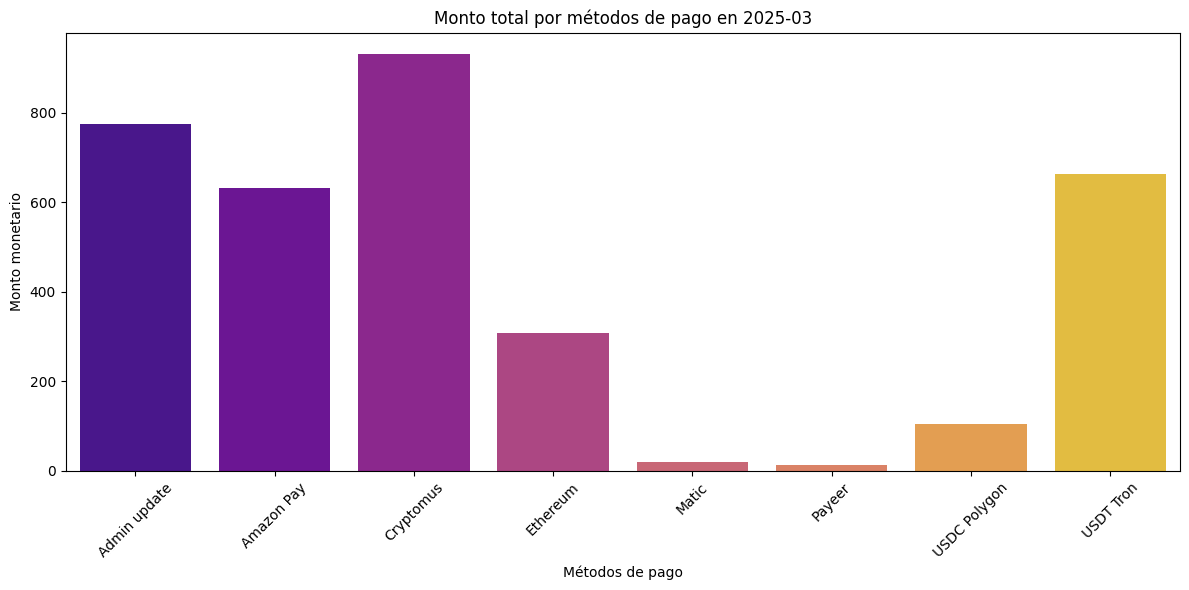

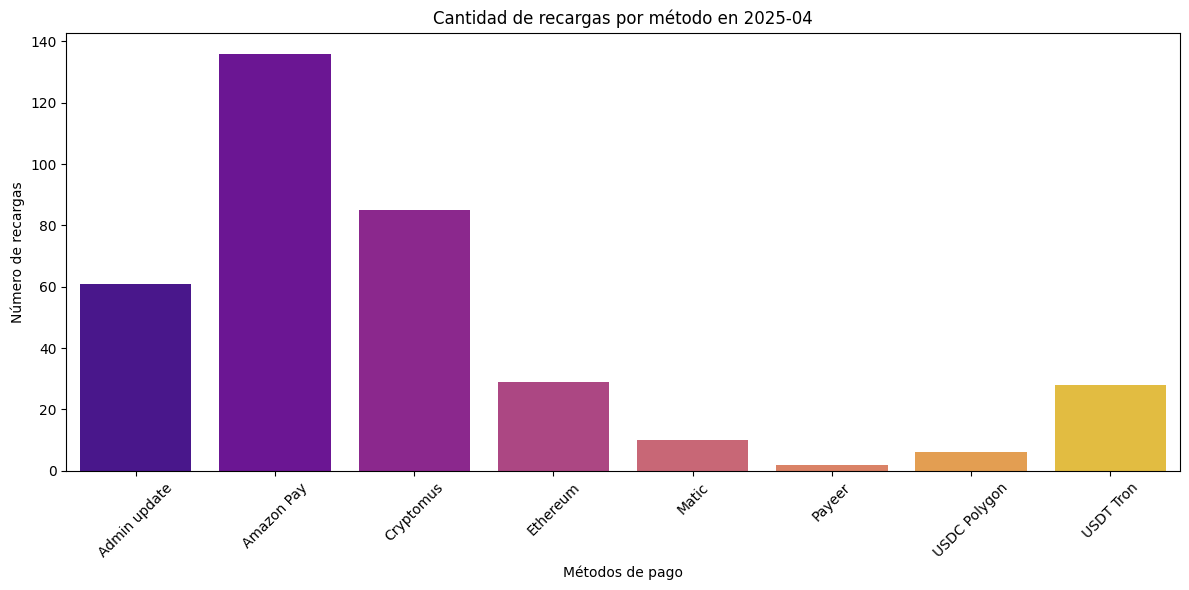

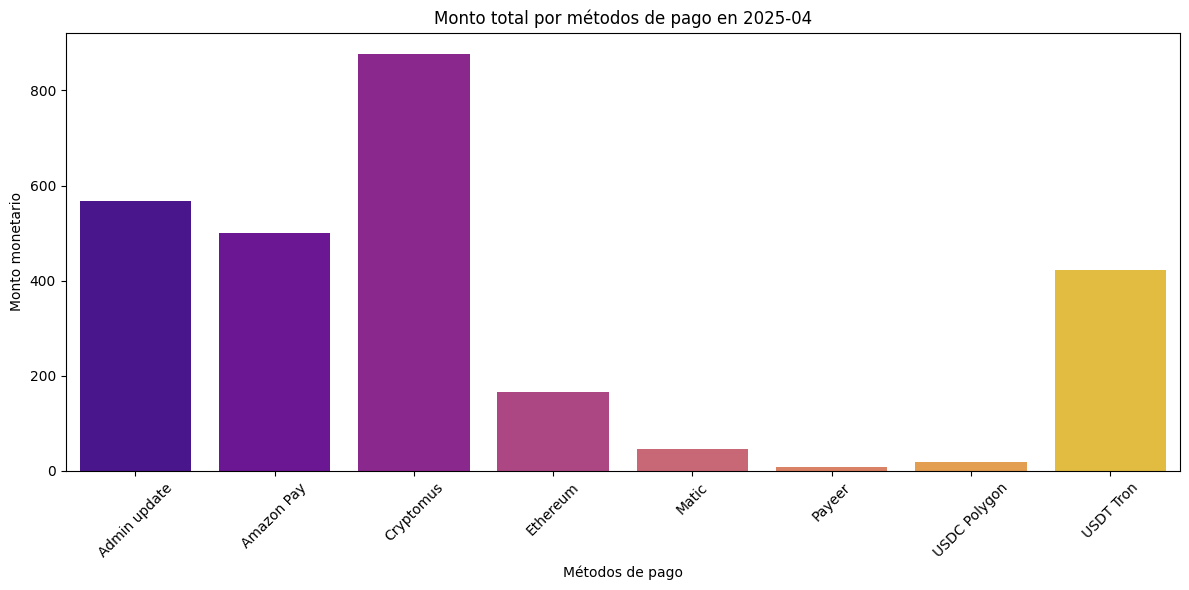

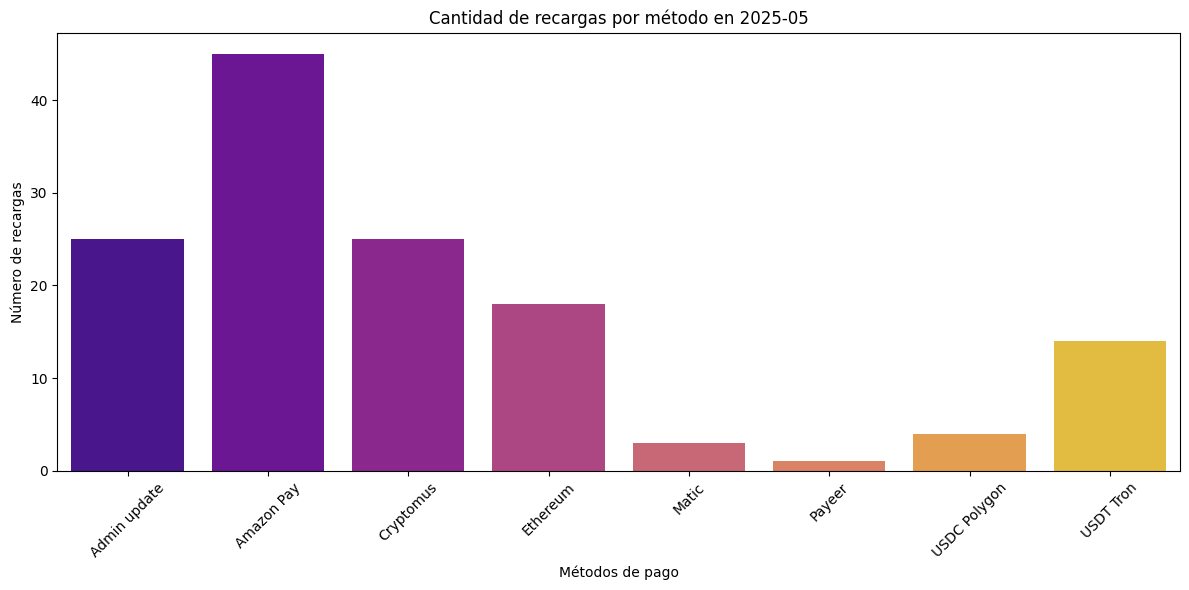

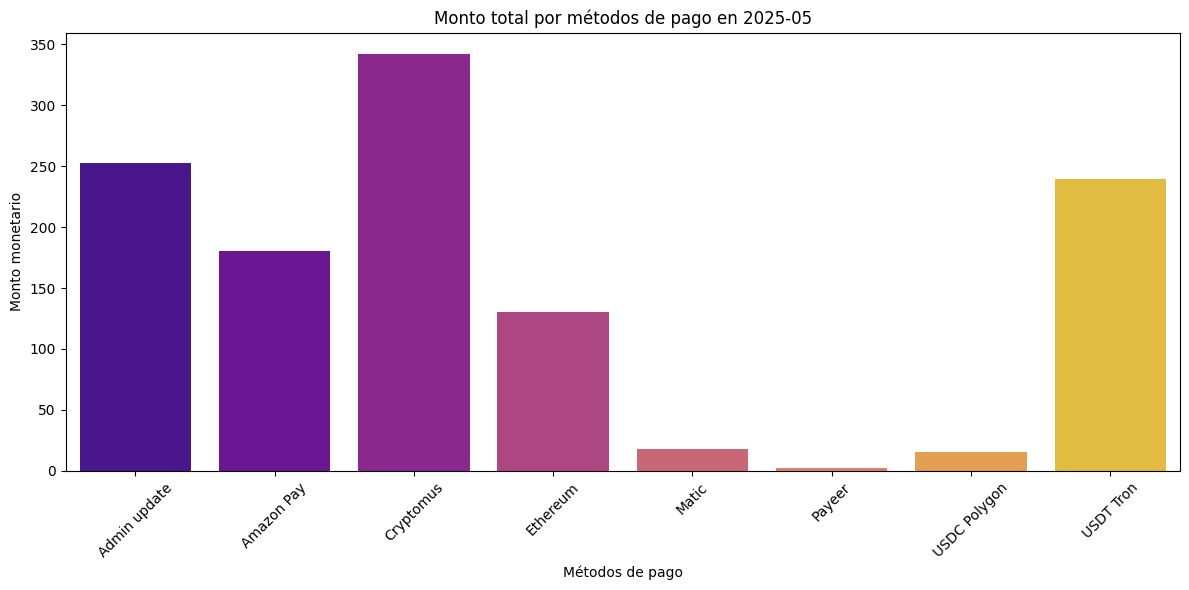

In [ ]:
#codigo 4
import pandas as pd
import json
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
import numpy as np
# Cargar el archivo JSON
with open('rechargeHistory.json') as f:
    data = json.load(f)

# Convertir a DataFrame (tabla)
df = pd.json_normalize(data)



# Filtrar el DataFrame (utilizar nada mas status: "Completed", "Admin update", "Overpayment", "Underpayment")
# Usamos .isin() para filtrar por múltiples valores en la columna 'status'
df_filtrado = df[df['status'].isin(["Completed", "Admin update", "Overpayment", "Underpayment"])].copy()


# Convertir la columna 'amount' a numérico en el DataFrame
df_filtrado["amount"] = df_filtrado["amount"].astype(float)


df_filtrado = df_filtrado.dropna(subset=['amount']).copy()

df_filtrado2 = df_filtrado[df_filtrado["paymentMethod"] != "Inactivity fee"].copy()

print(df_filtrado2["paymentMethod"].value_counts())
#top_5_metodos_de_pago = df_filtrado2["paymentMethod"].value_counts().head(5)
#print(top_5_metodos_de_pago)

# Agrupar por paymentMethod y contar las recargas
contar_recargas_por_metodo = df_filtrado2.groupby('paymentMethod')['amount'].size().reset_index(name='recargas_por_metodo')

print(contar_recargas_por_metodo)

# Crear el gráfico de barras

sns.barplot(x='paymentMethod', y='recargas_por_metodo', data=contar_recargas_por_metodo, palette='plasma', hue= "recargas_por_metodo", legend=False)


plt.title('Cantidad de recargas por método')
plt.xlabel('Métodos de pago')
plt.ylabel('Número de recargas')
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

# Agrupar por paymentMethod y sumar los montos("amount")

monto_total_por_metodo = df_filtrado2.groupby('paymentMethod')['amount'].sum().reset_index(name='monto_por_metodo')


print(monto_total_por_metodo)


# Crear el gráfico de barras

sns.barplot(x='paymentMethod', y='monto_por_metodo', data=monto_total_por_metodo, palette='plasma', hue= "monto_por_metodo", legend=False)


plt.title('Monto total por métodos de pago')
plt.xlabel('Métodos de pago')
plt.ylabel('Monto monetario')
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

print("-------------")
print("-------------")
print("-------------")



# Convertir la columna timestamp a fecha en df_filtrado2
df_filtrado2["fecha"] = pd.to_datetime(df_filtrado2["timestamp._seconds"], unit="s").copy()

# Convertir a datetime y extraer el periodo mensual (ej: "2023-01") en df
df_filtrado2["mes"] = df_filtrado2["fecha"].dt.to_period('M').copy()

# Agrupar por mes y paymentMethod y contar recargas y sumar monto
comparativa_mensual = df_filtrado2.groupby(['mes', 'paymentMethod']).agg(
    recargas_por_metodo=('amount', 'size'),
    monto_por_metodo=('amount', 'sum')
).reset_index().copy()

# Iterar sobre cada mes para crear los gráficos
for mes in comparativa_mensual['mes'].unique():
    df_mes = comparativa_mensual[comparativa_mensual['mes'] == mes]

    # Gráfico de recargas por método para el mes actual
    plt.figure(figsize=(12, 6))
    sns.barplot(x='paymentMethod', y='recargas_por_metodo', data=df_mes, palette='plasma', hue='paymentMethod', legend=False)
    plt.title(f'Cantidad de recargas por método en {mes}')
    plt.xlabel('Métodos de pago')
    plt.ylabel('Número de recargas')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    # Gráfico de monto total por método para el mes actual
    plt.figure(figsize=(12, 6))
    sns.barplot(x='paymentMethod', y='monto_por_metodo', data=df_mes, palette='plasma', hue='paymentMethod', legend=False)
    plt.title(f'Monto total por métodos de pago en {mes}')
    plt.xlabel('Métodos de pago')
    plt.ylabel('Monto monetario')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()





#Código 5

1. CARGANDO DATOS...
✓ Total de registros cargados: 48856

2. FILTRANDO VERIFICACIONES COMPLETADAS...
✓ Verificaciones completadas: 29745

3. PROCESANDO FECHAS...
✓ Fechas procesadas correctamente

4. ANÁLISIS TOTAL DE VERIFICACIONES POR DÍA...


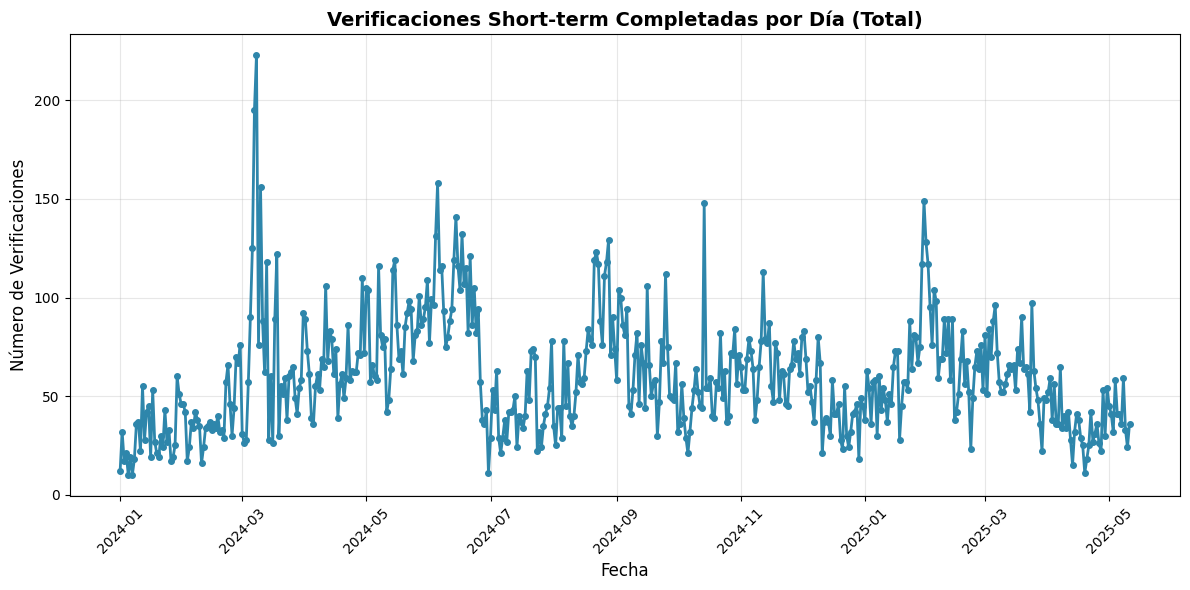


5. ANÁLISIS POR PAÍSES PRINCIPALES...
✓ Países principales: ['USA', 'UK', 'ESP', 'DE', 'AUS']


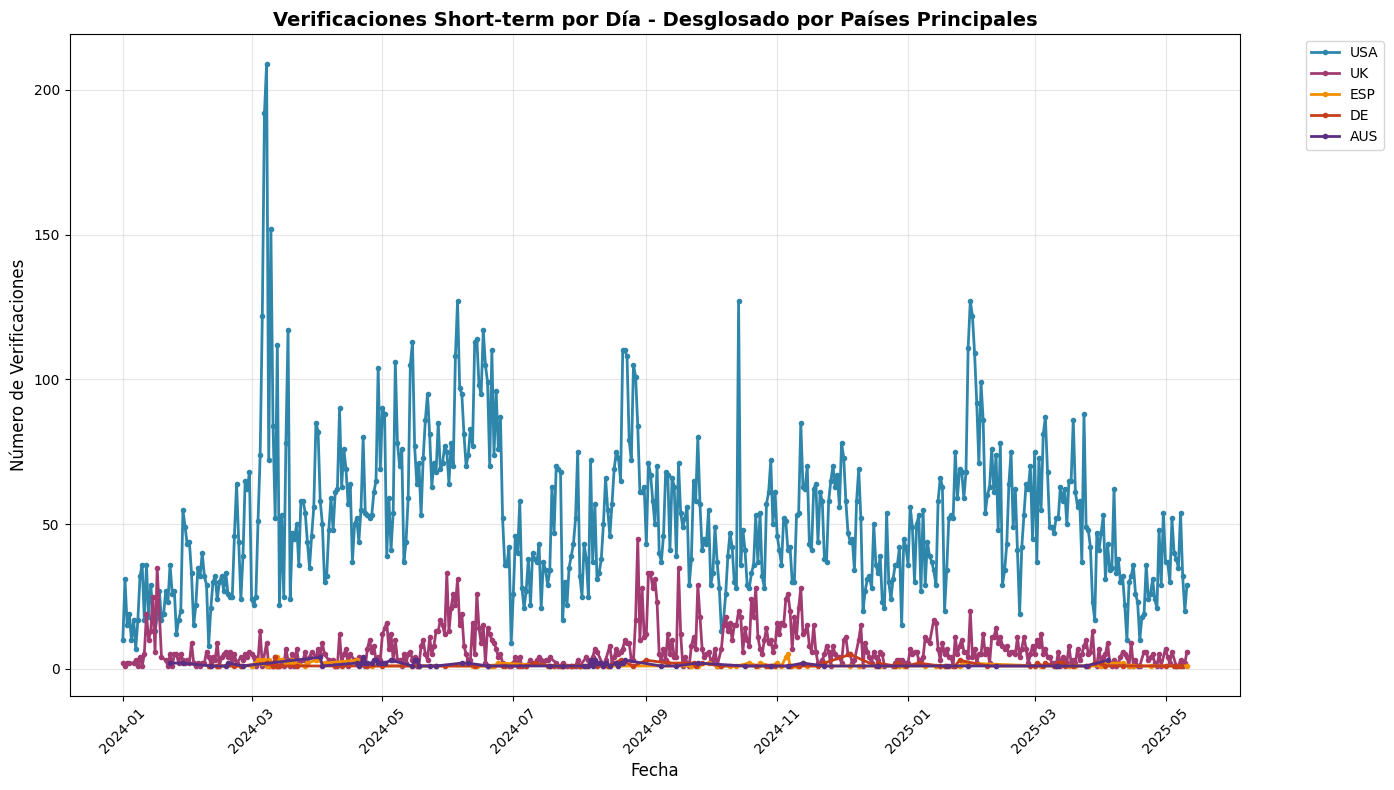


ESTADÍSTICAS DESCRIPTIVAS

📊 VERIFICACIONES TOTAL POR DÍA:
Media muestral (x̄): 59.85 verificaciones/día
Varianza muestral (s²): 823.15
Desviación estándar muestral (s): 28.69
Tamaño de muestra (n): 497 días

📊 VERIFICACIONES POR PAÍS:

USA:
  Media muestral (x̄): 51.99 verificaciones/día
  Varianza muestral (s²): 678.17
  Desviación estándar muestral (s): 26.04
  Tamaño de muestra (n): 497 días

UK:
  Media muestral (x̄): 6.95 verificaciones/día
  Varianza muestral (s²): 44.10
  Desviación estándar muestral (s): 6.64
  Tamaño de muestra (n): 464 días

ESP:
  Media muestral (x̄): 1.56 verificaciones/día
  Varianza muestral (s²): 0.77
  Desviación estándar muestral (s): 0.88
  Tamaño de muestra (n): 81 días

DE:
  Media muestral (x̄): 1.36 verificaciones/día
  Varianza muestral (s²): 0.52
  Desviación estándar muestral (s): 0.72
  Tamaño de muestra (n): 84 días

AUS:
  Media muestral (x̄): 1.72 verificaciones/día
  Varianza muestral (s²): 0.68
  Desviación estándar muestral (s): 0.83
 

In [11]:
# Código 5
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# Configuración de gráficos
plt.style.use('default')
sns.set_palette("husl")

# 1. CARGA DE DATOS
print("1. CARGANDO DATOS...")
with open('short-term.json', 'r', encoding='utf-8') as archivo:
    datos = json.load(archivo)

df = pd.DataFrame(datos)
print(f"✓ Total de registros cargados: {len(df)}")

# 2. FILTRADO DE VERIFICACIONES COMPLETADAS
print("\n2. FILTRANDO VERIFICACIONES COMPLETADAS...")
df_completed = df[df['status'] == 'Completed'].copy()
print(f"✓ Verificaciones completadas: {len(df_completed)}")

# 3. CONVERSIÓN DE TIMESTAMPS
print("\n3. PROCESANDO FECHAS...")
def convertir_timestamp(timestamp_obj):
    if isinstance(timestamp_obj, dict):
        seconds = timestamp_obj.get('_seconds', 0)
        nanoseconds = timestamp_obj.get('_nanoseconds', 0)
        total_seconds = seconds + (nanoseconds / 1e9)
        return pd.to_datetime(total_seconds, unit='s')
    else:
        return pd.to_datetime(timestamp_obj, unit='s')

df_completed['fecha'] = df_completed['timestamp'].apply(convertir_timestamp)
df_completed['solo_fecha'] = df_completed['fecha'].dt.date
print("✓ Fechas procesadas correctamente")

# 4. ANÁLISIS TOTAL DE VERIFICACIONES POR DÍA
print("\n4. ANÁLISIS TOTAL DE VERIFICACIONES POR DÍA...")
verificaciones_por_dia = df_completed.groupby('solo_fecha').size().reset_index(name='total_verificaciones')

# GRÁFICO 1: Verificaciones completadas por día (total)
plt.figure(figsize=(12, 6))
plt.plot(verificaciones_por_dia['solo_fecha'], verificaciones_por_dia['total_verificaciones'],
         marker='o', linewidth=2, markersize=4, color='#2E86AB')
plt.title('Verificaciones Short-term Completadas por Día (Total)', fontsize=14, fontweight='bold')
plt.xlabel('Fecha', fontsize=12)
plt.ylabel('Número de Verificaciones', fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 5. ANÁLISIS POR PAÍSES PRINCIPALES
print("\n5. ANÁLISIS POR PAÍSES PRINCIPALES...")
paises_principales = df_completed['country'].value_counts().head(5).index.tolist()
print(f"✓ Países principales: {paises_principales}")

df_paises_principales = df_completed[df_completed['country'].isin(paises_principales)]
verificaciones_por_dia_pais = df_paises_principales.groupby(['solo_fecha', 'country']).size().reset_index(name='verificaciones')

# GRÁFICO 2: Verificaciones por día desglosado por países principales
plt.figure(figsize=(14, 8))
colores = ['#2E86AB', '#A23B72', '#F18F01', '#C73E1D', '#592E83']
for i, pais in enumerate(paises_principales):
    datos_pais = verificaciones_por_dia_pais[verificaciones_por_dia_pais['country'] == pais]
    plt.plot(datos_pais['solo_fecha'], datos_pais['verificaciones'],
            marker='o', label=pais, linewidth=2, markersize=3, color=colores[i])

plt.title('Verificaciones Short-term por Día - Desglosado por Países Principales',
          fontsize=14, fontweight='bold')
plt.xlabel('Fecha', fontsize=12)
plt.ylabel('Número de Verificaciones', fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 6. ESTADÍSTICAS DESCRIPTIVAS
print("\n" + "="*60)
print("ESTADÍSTICAS DESCRIPTIVAS")
print("="*60)

# Estadísticas para el total de verificaciones por día
total_diario = verificaciones_por_dia['total_verificaciones']

print("\n📊 VERIFICACIONES TOTAL POR DÍA:")
print(f"Media muestral (x̄): {total_diario.mean():.2f} verificaciones/día")
print(f"Varianza muestral (s²): {total_diario.var(ddof=1):.2f}")
print(f"Desviación estándar muestral (s): {total_diario.std(ddof=1):.2f}")
print(f"Tamaño de muestra (n): {len(total_diario)} días")

# Estadísticas por país
print(f"\n📊 VERIFICACIONES POR PAÍS:")
for pais in paises_principales:
    datos_pais = verificaciones_por_dia_pais[verificaciones_por_dia_pais['country'] == pais]['verificaciones']
    if len(datos_pais) > 0:
        print(f"\n{pais}:")
        print(f"  Media muestral (x̄): {datos_pais.mean():.2f} verificaciones/día")
        print(f"  Varianza muestral (s²): {datos_pais.var(ddof=1):.2f}")
        print(f"  Desviación estándar muestral (s): {datos_pais.std(ddof=1):.2f}")
        print(f"  Tamaño de muestra (n): {len(datos_pais)} días")

# 7. INTERVALOS DE CONFIANZA (95%)
print("\n" + "="*60)
print("INTERVALOS DE CONFIANZA 95% - ESTIMACIÓN μ POBLACIONAL")
print("="*60)

# Intervalo de confianza para la media poblacional total
n = len(total_diario)
media = total_diario.mean()
error_estandar = total_diario.std(ddof=1) / np.sqrt(n)
t_critico = stats.t.ppf(0.975, df=n-1)
margen_error = t_critico * error_estandar

intervalo_inferior = media - margen_error
intervalo_superior = media + margen_error

print(f"\n🎯 TOTAL DE VERIFICACIONES:")
print(f"Intervalo de confianza 95% para μ: [{intervalo_inferior:.2f}, {intervalo_superior:.2f}] verificaciones/día")
print(f"Interpretación: Con 95% de confianza, la media poblacional real")
print(f"de verificaciones diarias está entre {intervalo_inferior:.2f} y {intervalo_superior:.2f}")

# Intervalos de confianza por país
print(f"\n🎯 POR PAÍS:")
for pais in paises_principales:
    datos_pais = verificaciones_por_dia_pais[verificaciones_por_dia_pais['country'] == pais]['verificaciones']
    if len(datos_pais) > 1:
        n_pais = len(datos_pais)
        media_pais = datos_pais.mean()
        error_est_pais = datos_pais.std(ddof=1) / np.sqrt(n_pais)
        t_crit_pais = stats.t.ppf(0.975, df=n_pais-1)
        margen_pais = t_crit_pais * error_est_pais

        ic_inf = media_pais - margen_pais
        ic_sup = media_pais + margen_pais

        print(f"\n{pais}:")
        print(f"  IC 95% para μ: [{ic_inf:.2f}, {ic_sup:.2f}] verificaciones/día")

print("\n" + "="*60)
print("✅ ANÁLISIS COMPLETADO")
print("="*60)

# Código 6

Hay 15198 verificaciones con status Timed Out y 3268 con status Cancelled
Top 10 servicios con más cancelaciones/timeouts:
service
Whatsapp              2634
Telegram              2426
Gmail                 1624
Service Not Listed    1451
Google                 905
Tinder                 894
Paypal                 816
Bumble                 597
Plenty of fish         427
Ebay                   410
Name: count, dtype: int64
       cancelaciones_timed_out_diarias
count                       497.000000
mean                         37.154930
std                          22.760547
min                           3.000000
25%                          24.000000
50%                          33.000000
75%                          44.000000
max                         225.000000
Top 10 días con mayor número de cancelaciones/timeouts:
            dia  cancelaciones_timed_out_diarias
67   2024-03-08                              225
58   2024-02-28                              211
66   2024-03-07    

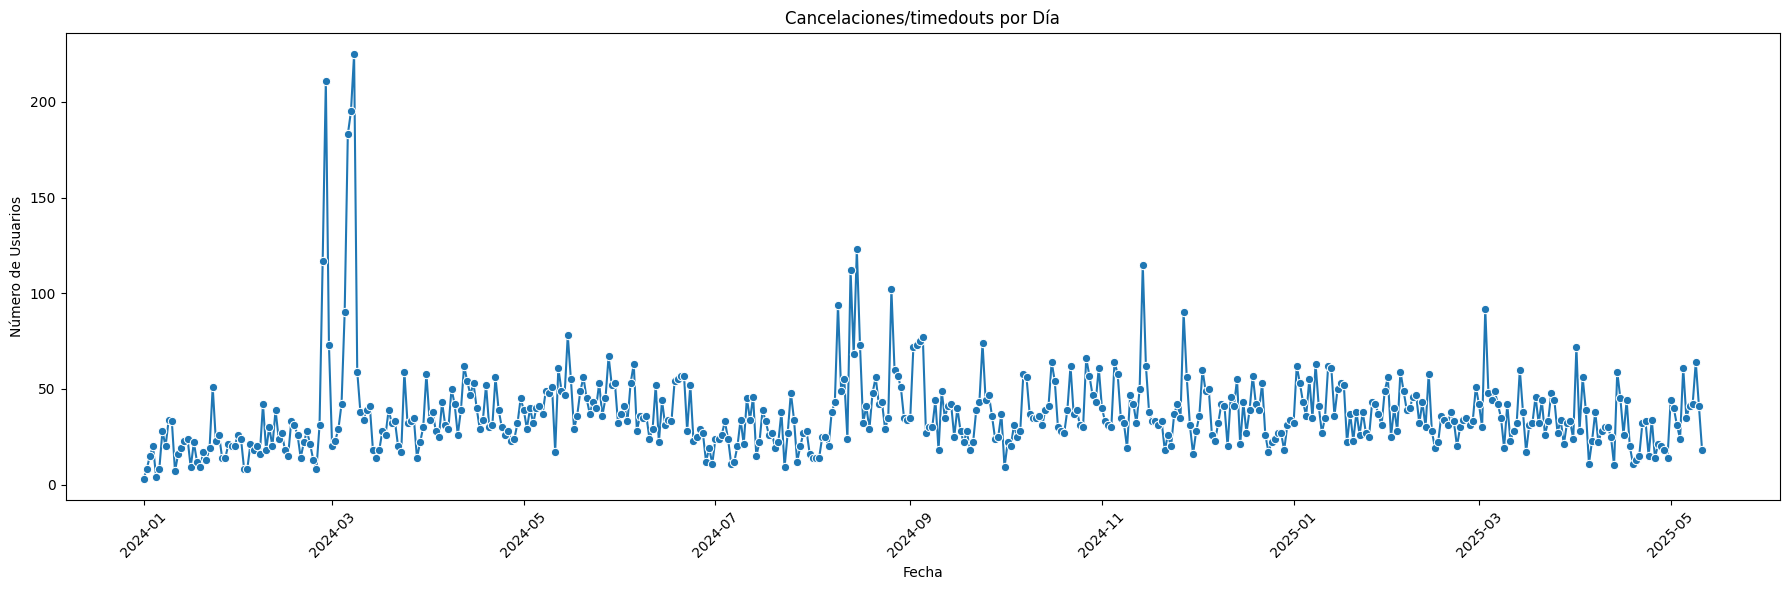

        mes  cancelaciones_timed_out_mensuales
0   2024-01                                578
1   2024-02                                976
2   2024-03                               1546
3   2024-04                               1120
4   2024-05                               1386
5   2024-06                               1080
6   2024-07                                816
7   2024-08                               1485
8   2024-09                               1200
9   2024-10                               1218
10  2024-11                               1229
11  2024-12                               1096
12  2025-01                               1290
13  2025-02                               1011
14  2025-03                               1148
15  2025-04                                846
16  2025-05                                441
       cancelaciones_timed_out_mensuales
count                          17.000000
mean                         1086.235294
std                           2

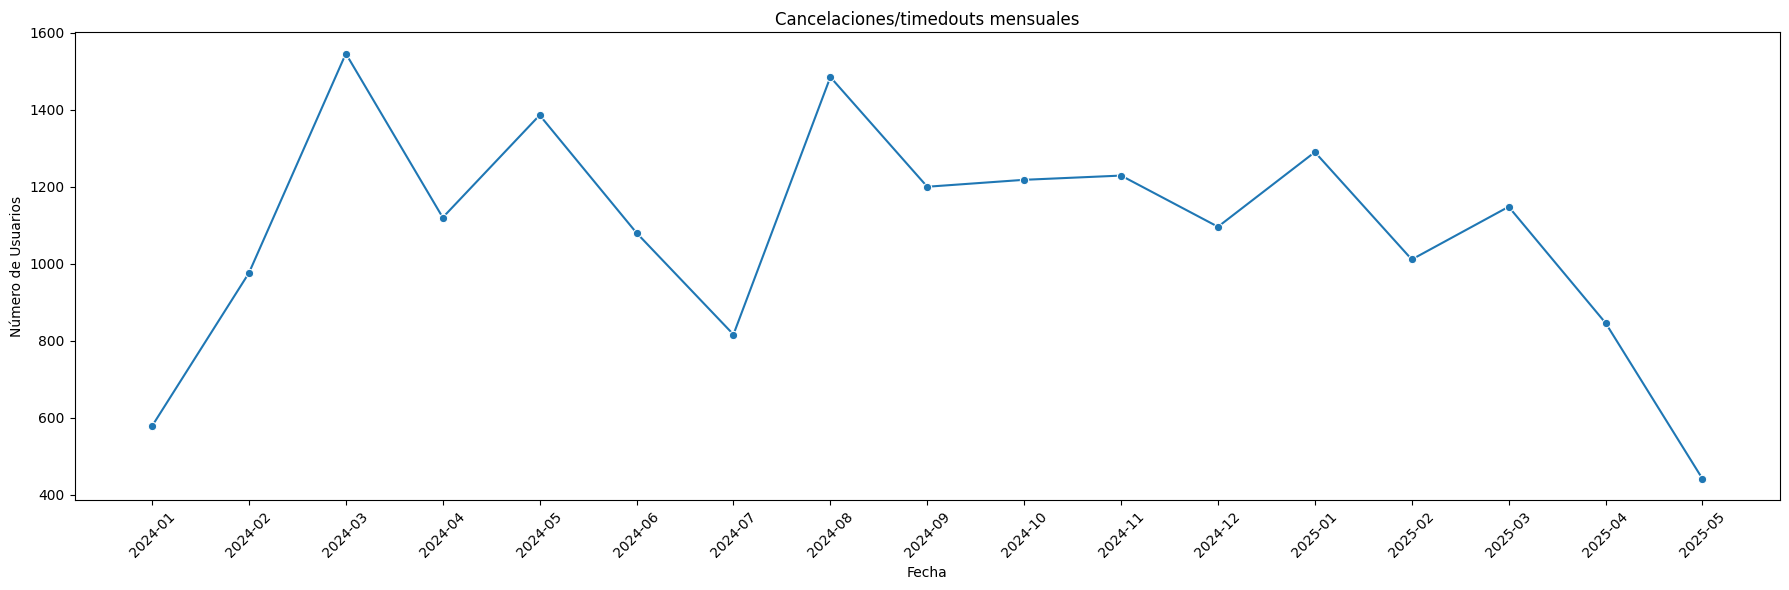


Datos semanales por año:
     año  semana_año  cancelaciones_timed_out_semanales
0   2024           1                                 86
1   2024           2                                152
2   2024           3                                106
3   2024           4                                168
4   2024           5                                127
..   ...         ...                                ...
66  2025          15                                183
67  2025          16                                218
68  2025          17                                164
69  2025          18                                191
70  2025          19                                302

[71 rows x 3 columns]
               año  semana_año  cancelaciones_timed_out_semanales
count    71.000000   71.000000                          71.000000
mean   2024.267606   22.084507                         260.084507
std       0.445862   15.152319                         104.658048
min    2024.000

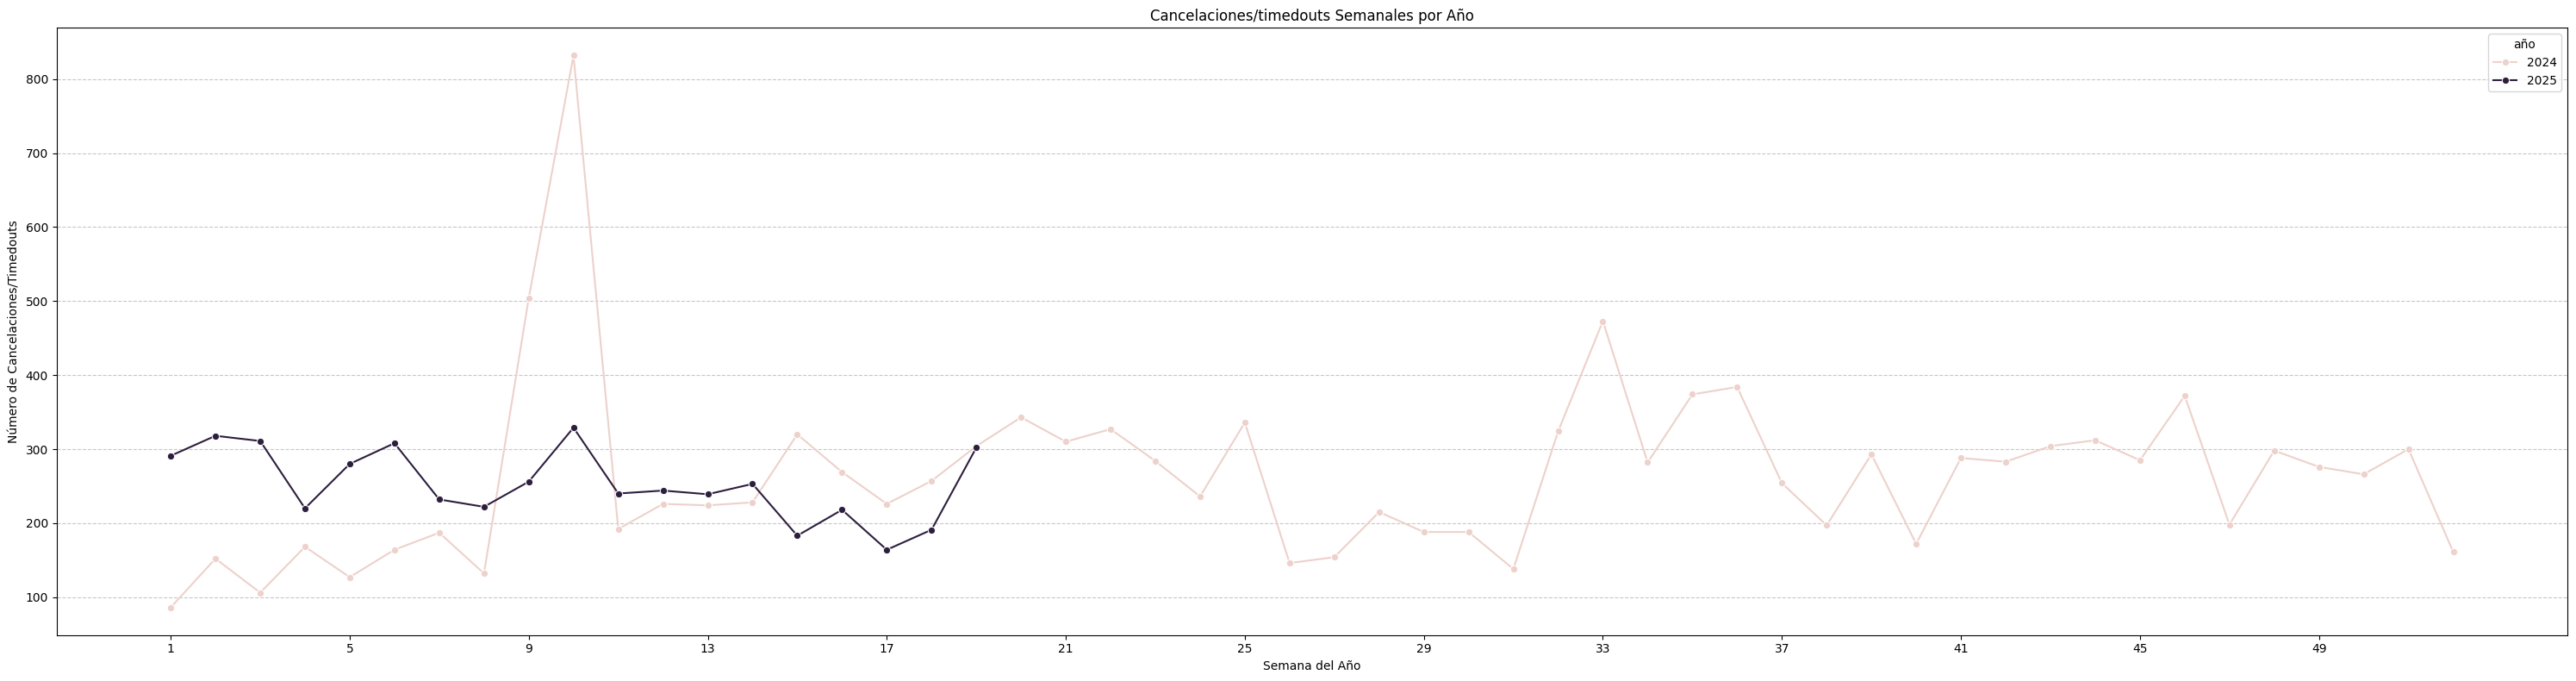

In [ ]:
#Código 6
import pandas as pd
import json
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
import numpy as np
# Cargar el archivo JSON
with open('short-term.json') as f:
    data = json.load(f)

# Convertir a DataFrame (tabla)
df = pd.json_normalize(data)

df_filtrado = df[df['status'].isin(["Timed Out", "Cancelled"])].copy()




timed_out_and_cancelled = df_filtrado["status"].value_counts()

print(f"Hay {timed_out_and_cancelled.iloc[0]} verificaciones con status Timed Out y {timed_out_and_cancelled.iloc[1]} con status Cancelled")



servicios = df_filtrado["service"].value_counts()

top_10_servicios = servicios.head(10)
print("Top 10 servicios con más cancelaciones/timeouts:")
print(top_10_servicios)

df_filtrado["fecha"] = pd.to_datetime(df_filtrado["timestamp._seconds"], unit="s")
# Extraer solo la fecha
df_filtrado["dia"] = df_filtrado["fecha"].dt.date

# Contar usuarios por día
cancelaciones_time_out_por_dia = df_filtrado.groupby("dia").size().reset_index(name="cancelaciones_timed_out_diarias")

print(cancelaciones_time_out_por_dia.describe())

top_10_cancelaciones_diarias = cancelaciones_time_out_por_dia.sort_values(by='cancelaciones_timed_out_diarias', ascending=False).head(10)
print("Top 10 días con mayor número de cancelaciones/timeouts:")
print(top_10_cancelaciones_diarias)

#verificar si no hay servicios "extraños o inexistentes"
#Obtener la lista de los días con más cancelaciones/timeouts
dias_top_cancelaciones = top_10_cancelaciones_diarias['dia'].tolist()

#Filtrar el DataFrame principal (df_filtrado2)
df_servicios_top_dias = df_filtrado[df_filtrado['dia'].isin(dias_top_cancelaciones)]

#Contar los servicios por día filtrado
servicios_por_dia_top = df_servicios_top_dias.groupby(['dia', 'service']).size().reset_index(name='conteo')

#Mostrar los resultados
print("\nServicios más frecuentes en los días con mayor número de cancelaciones/timeouts:")
for dia in dias_top_cancelaciones:
    print(f"\nDía: {dia}")
    servicios_del_dia = servicios_por_dia_top[servicios_por_dia_top['dia'] == dia].sort_values(by='conteo', ascending=False)
    print(servicios_del_dia)




# Configurar el tamaño del gráfico
plt.figure(figsize=(18, 6))

# Gráfico de líneas
sns.lineplot(x="dia", y="cancelaciones_timed_out_diarias", data=cancelaciones_time_out_por_dia, marker="o")

# Personalizar el gráfico
plt.title("Cancelaciones/timedouts por Día")
plt.xlabel("Fecha")
plt.ylabel("Número de Usuarios")
plt.xticks(rotation=45)

# Ajustar el diseño para evitar que las etiquetas se corten
plt.tight_layout()

# Mostrar el gráfico
plt.show()




# Convertir a datetime y extraer el periodo mensual (ej: "2023-01") en df
df_filtrado["mes"] = df_filtrado["fecha"].dt.to_period('M').copy()

# Contar ingresos por mes en df
cancelaciones_time_out_por_mes = df_filtrado.groupby("mes").size().reset_index(name="cancelaciones_timed_out_mensuales")

print(cancelaciones_time_out_por_mes)

print(cancelaciones_time_out_por_mes.describe())

# Configurar el tamaño del gráfico
plt.figure(figsize=(18, 6))

# Gráfico de líneas
sns.lineplot(x=cancelaciones_time_out_por_mes["mes"].astype(str), y="cancelaciones_timed_out_mensuales", data=cancelaciones_time_out_por_mes, marker="o")
# Personalizar el gráfico
plt.title("Cancelaciones/timedouts mensuales")
plt.xlabel("Fecha")
plt.ylabel("Número de Usuarios")
plt.xticks(rotation=45)

# Ajustar el diseño para evitar que las etiquetas se corten
plt.tight_layout()

# Mostrar el gráfico
plt.show()


# Convertir a datetime y extraer el periodo semanal y el año
df_filtrado["semana_año"] = df_filtrado["fecha"].dt.isocalendar().week.astype(int)
df_filtrado["año"] = df_filtrado["fecha"].dt.isocalendar().year.astype(int)


# Contar cancelaciones por semana del año y por año
cancelaciones_time_out_semanal_por_año = df_filtrado.groupby(["año", "semana_año"]).size().reset_index(name="cancelaciones_timed_out_semanales")


print("\nDatos semanales por año:")
print(cancelaciones_time_out_semanal_por_año)
print(cancelaciones_time_out_semanal_por_año.describe())


# Crear el gráfico de líneas con una línea por año (tamaño aumentado y ticks controlados)
plt.figure(figsize=(30, 8)) # Aumentar el tamaño significativamente
sns.lineplot(x="semana_año", y="cancelaciones_timed_out_semanales", hue="año", data=cancelaciones_time_out_semanal_por_año, marker="o")

# Personalizar el gráfico
plt.title("Cancelaciones/timedouts Semanales por Año")
plt.xlabel("Semana del Año")
plt.ylabel("Número de Cancelaciones/Timedouts")
# Establecer ticks en intervalos más amplios (ej. cada 4 semanas)
plt.xticks(np.arange(1, 53, 4))
plt.grid(axis='y', linestyle='--', alpha=0.7) # Añadir grid

# Ajustar el diseño
plt.tight_layout()

# Mostrar el gráfico
plt.show()

# Código 7

Top 10 servicios más solicitados:
service
Gmail             4247
Tinder            2916
Whatsapp          2134
Paypal            2116
Google            1632
Plenty of fish    1630
Ebay              1519
Telegram          1068
Bumble            1043
Hinge              954
Name: count, dtype: int64
Top 10 servicios por ingresos generados:
                service  total_ingresos
101               Gmail         3251.61
250              Tinder         2852.13
277            Whatsapp         2482.92
189              Paypal         2016.42
105              Google         1316.53
221  Service Not Listed         1245.93
245            Telegram         1218.31
122               Hinge         1048.23
76                 Ebay          947.55
193      Plenty of fish          917.41


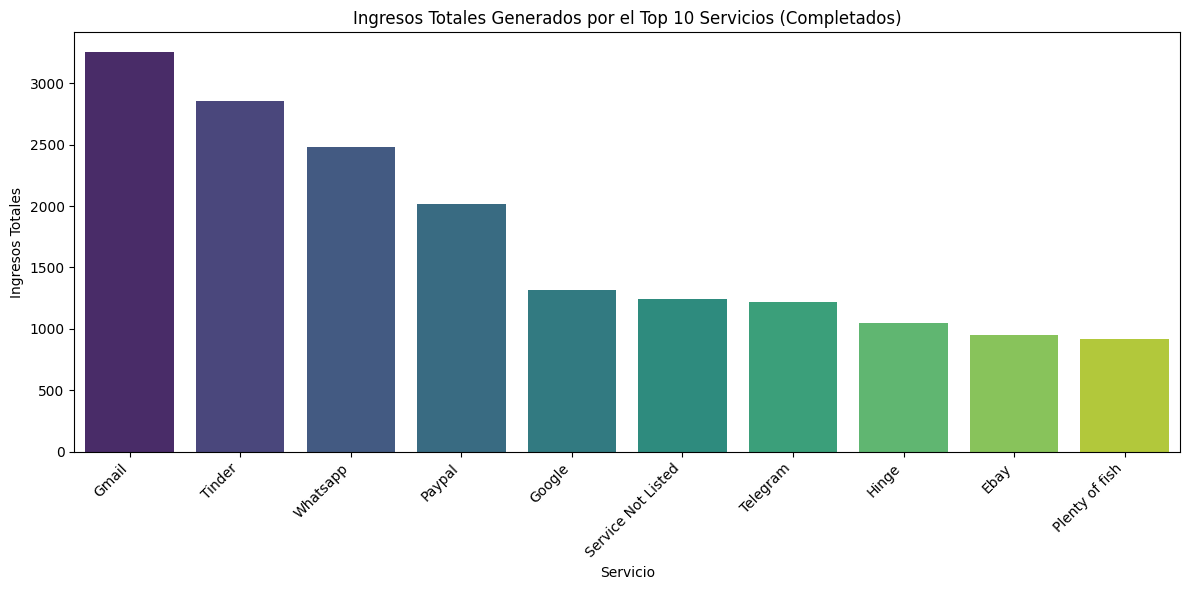

            dia  ingresos_dia
0    2024-01-01          9.01
1    2024-01-02         26.63
2    2024-01-03         15.09
3    2024-01-04         16.66
4    2024-01-05          9.73
..          ...           ...
492  2025-05-07         27.13
493  2025-05-08         40.59
494  2025-05-09         21.22
495  2025-05-10         17.72
496  2025-05-11         34.41

[497 rows x 2 columns]
       ingresos_dia
count    497.000000
mean      51.539537
std       25.516986
min        7.440000
25%       33.780000
50%       47.890000
75%       63.950000
max      226.480000


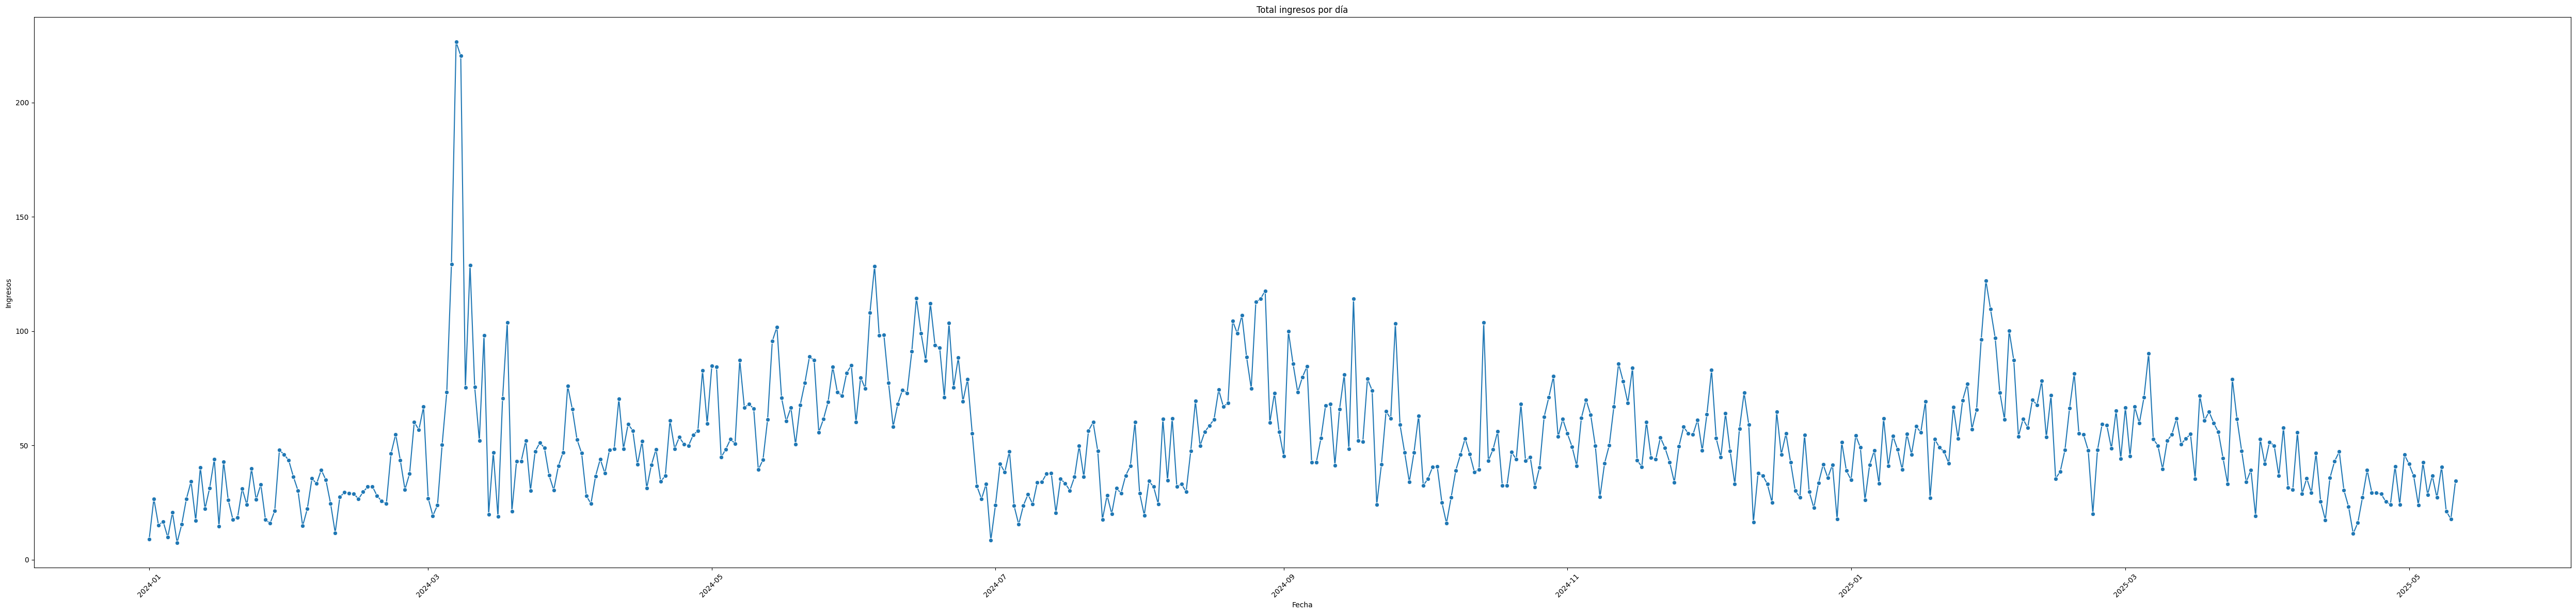

Valores atípicos (días con ingresos inusuales):
            dia  ingresos_dia
65   2024-03-06        129.18
66   2024-03-07        226.48
67   2024-03-08        220.40
69   2024-03-10        128.89
156  2024-06-05        128.42
165  2024-06-14        114.40
168  2024-06-17        112.17
238  2024-08-26        112.75
239  2024-08-27        114.04
240  2024-08-28        117.62
259  2024-09-16        114.05
395  2025-01-30        122.06
396  2025-01-31        109.51
Número de valores atípicos: 13
-------------
-------------
-------------
        mes  ingresos_mes
0   2024-01        801.55
1   2024-02        991.81
2   2024-03       2027.17
3   2024-04       1468.23
4   2024-05       2146.17
5   2024-06       2330.32
6   2024-07       1078.94
7   2024-08       1950.81
8   2024-09       1894.01
9   2024-10       1442.99
10  2024-11       1630.96
11  2024-12       1360.03
12  2025-01       1750.63
13  2025-02       1704.33
14  2025-03       1668.84
15  2025-04       1017.48
16  2025-05      

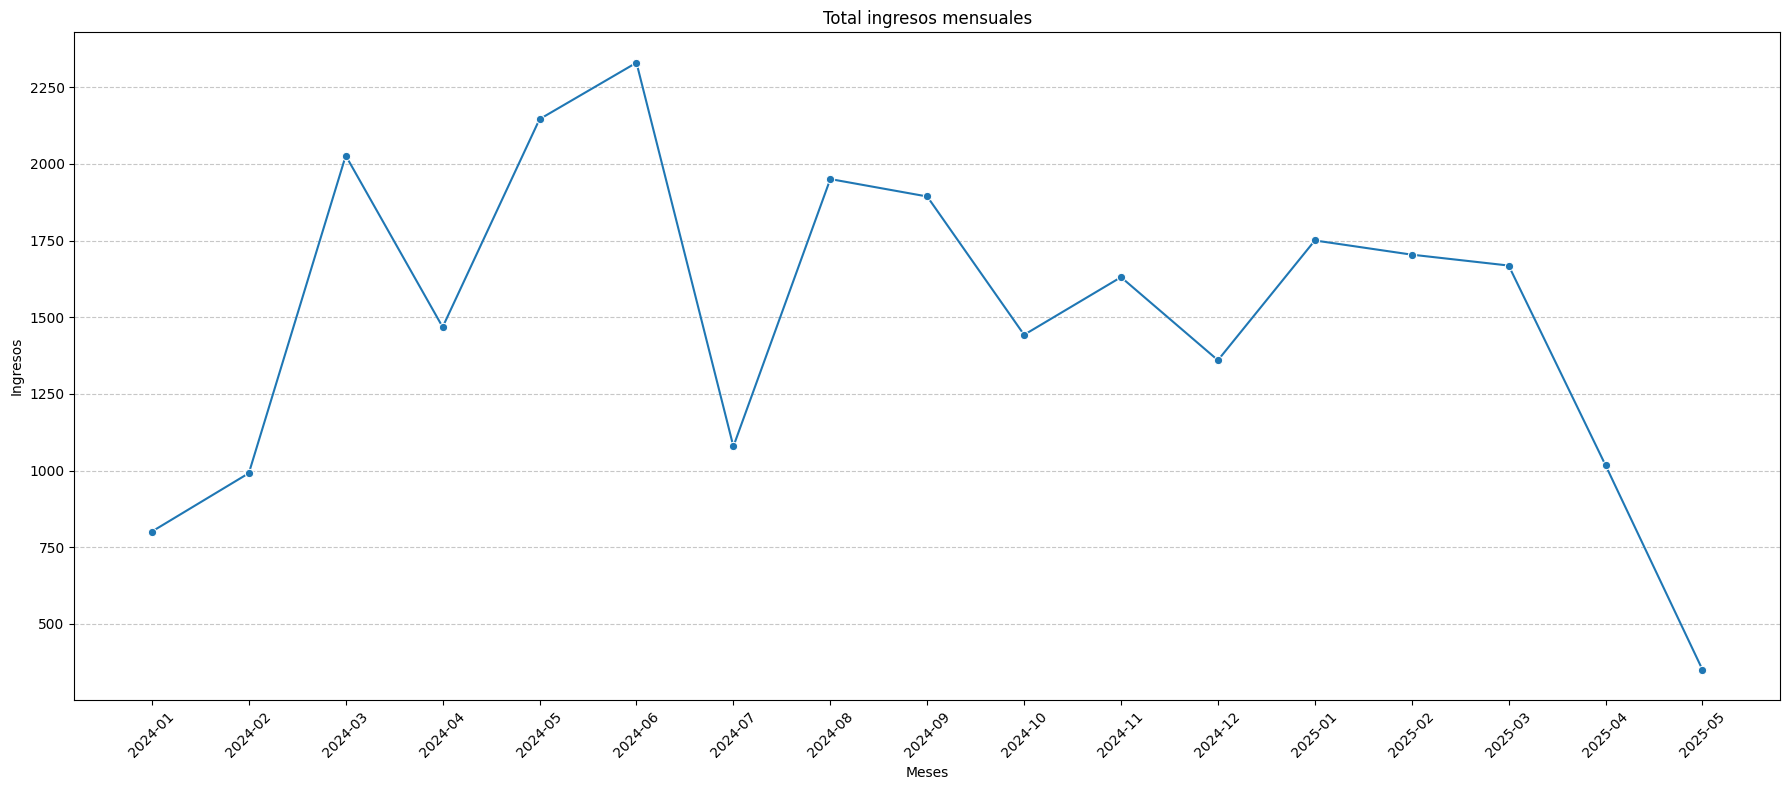

Limite inferior para valores atípicos mensuales: -143.66499999999996
Limite superior para valores atípicos mensuales: 3116.615
Valores atípicos (meses con ingresos inusuales):
Empty DataFrame
Columns: [mes, ingresos_mes]
Index: []
Número de valores atípicos mensuales: 0
-------------
-------------
-------------
                   semana  ingresos_semanal
0   2024-01-01/2024-01-07            105.26
1   2024-01-08/2024-01-14            187.13
2   2024-01-15/2024-01-21            194.25
3   2024-01-22/2024-01-28            177.55
4   2024-01-29/2024-02-04            240.71
..                    ...               ...
66  2025-04-07/2025-04-13            238.52
67  2025-04-14/2025-04-20            207.09
68  2025-04-21/2025-04-27            203.10
69  2025-04-28/2025-05-04            255.58
70  2025-05-05/2025-05-11            206.11

[71 rows x 2 columns]
       ingresos_semanal
count         71.000000
mean         360.776761
std          138.469748
min          105.260000
25%          254

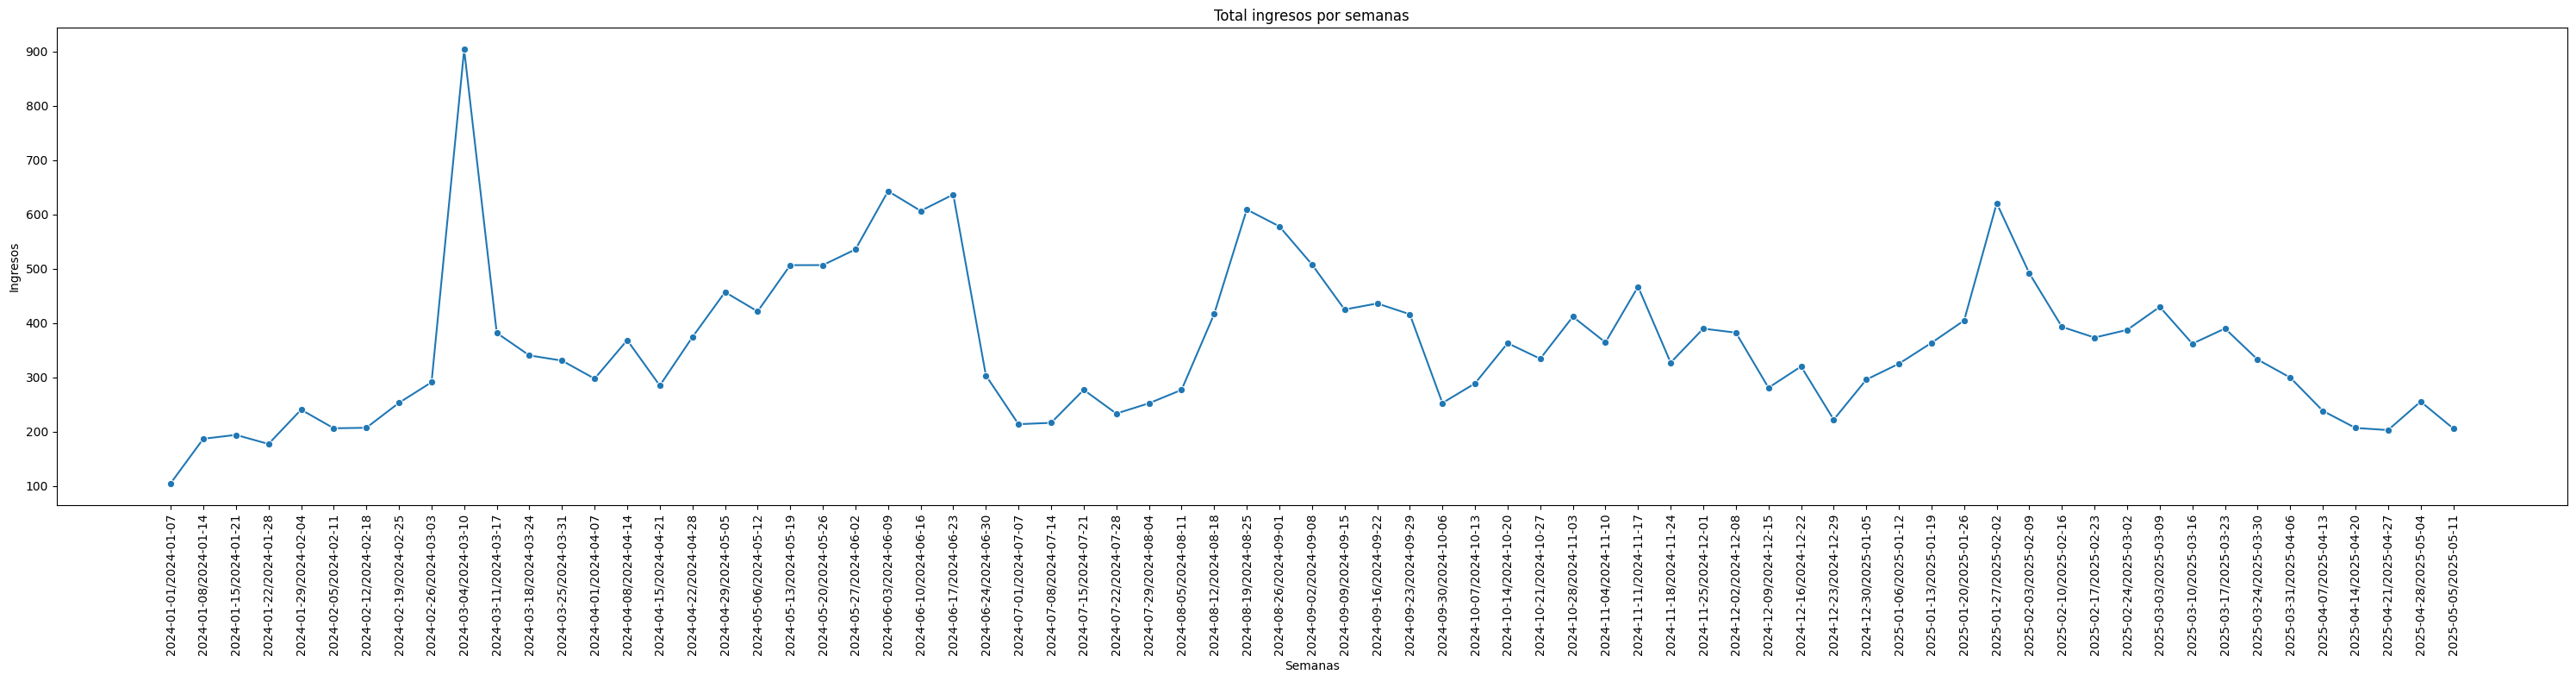

Limite inferior para valores atípicos semanales: 7.227499999999992
Limite superior para valores atípicos semanales: 666.3675000000001
Valores atípicos (semanas con ingresos inusuales):
                  semana  ingresos_semanal
9  2024-03-04/2024-03-10            903.78
Número de valores atípicos semanales: 1

--- Pruebas de bondad de ajuste para Verificaciones Diarias ---
Prueba de normalidad (D'Agostino-Pearson): Estadístico=216.3009, p-valor=0.0000
Prueba de Shapiro-Wilk: Estadístico=0.8973, p-valor=0.0000
Prueba de Kolmogorov-Smirnov: Estadístico=0.0849, p-valor=0.0015

Interpretación (con nivel de significancia alpha=0.05):
- La prueba de D'Agostino-Pearson sugiere que los datos de verificaciones diarias NO siguen una distribución normal.


In [ ]:
#Código 7
import pandas as pd
import json
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
import numpy as np
# Cargar el archivo JSON
with open('short-term.json') as f:
    data = json.load(f)

# Convertir a DataFrame (tabla)
df = pd.json_normalize(data)

df_filtrado = df[df['status'] == "Completed"].copy()
# Asegurarnos de que la columna 'price' sea numérica
# Usamos errors='coerce' para convertir valores no numéricos en NaN
df_filtrado['price'] = pd.to_numeric(df_filtrado['price'], errors='coerce')

# Eliminar filas con valores nulos en la columna 'price' después de la conversión
df_filtrado = df_filtrado.dropna(subset=['price'])

cantidad_servicios = df_filtrado["service"].value_counts()
top_10_servicios = cantidad_servicios.head(10)
print("Top 10 servicios más solicitados:")
print(top_10_servicios)



# Agrupar por servicio y sumar los precios (ingresos)
ingresos_por_servicio = df_filtrado.groupby('service')['price'].sum().reset_index(name='total_ingresos')

# Ordenar por total de ingresos de mayor a menor y obtener el top 10
top10_ingresos_servicios = ingresos_por_servicio.sort_values('total_ingresos', ascending=False).head(10)

print("Top 10 servicios por ingresos generados:")
print(top10_ingresos_servicios)

# Crear el gráfico de barras
plt.figure(figsize=(12, 6))
sns.barplot(x='service', y='total_ingresos', data=top10_ingresos_servicios, hue="service", palette='viridis', legend=False)
plt.title('Top 10 Servicios por Ingresos Generados')
plt.xlabel('Servicio')
plt.ylabel('Total de Ingresos')
plt.xticks(rotation=45)
plt.tight_layout()

plt.title('Ingresos Totales Generados por el Top 10 Servicios (Completados)')
plt.xlabel('Servicio')
plt.ylabel('Ingresos Totales')
plt.xticks(rotation=45, ha='right') # Rotar etiquetas del eje x para mayor legibilidad
plt.tight_layout() # Ajustar diseño para evitar solapamiento
plt.show()


#conversión  timestamp
df_filtrado["fecha"] = pd.to_datetime(df_filtrado["timestamp._seconds"], unit="s")

# Extraer solo la fecha
df_filtrado["dia"] = df_filtrado["fecha"].dt.date

# total de ingresos por día
ingresos_por_dia = df_filtrado.groupby("dia")["price"].sum().reset_index(name="ingresos_dia")

print(ingresos_por_dia)
print(ingresos_por_dia.describe())

# Gráfico de líneas de verificaciones diarias

plt.figure(figsize=(50, 12))


sns.lineplot(x="dia", y="ingresos_dia", data=ingresos_por_dia, marker="o")

# Personalizar el gráfico
plt.title("Total ingresos por día")
plt.xlabel("Fecha")
plt.ylabel("Ingresos")
plt.xticks(rotation=45)

# Ajustar el diseño para evitar que las etiquetas se corten
plt.tight_layout()

# Mostrar el gráfico
plt.show()

# Calcular Q1, Q3 y IQR para verificaciones diarias
Q1_dia = ingresos_por_dia["ingresos_dia"].quantile(0.25)
Q3_dia = ingresos_por_dia["ingresos_dia"].quantile(0.75)
IQR_dia = Q3_dia - Q1_dia

# Límites para detectar valores atípicos diarios
limite_inferior_dia = Q1_dia - 1.5 * IQR_dia
limite_superior_dia = Q3_dia + 1.5 * IQR_dia

# Identificar valores atípicos diarios
valores_atipicos_dia = ingresos_por_dia[
    (ingresos_por_dia["ingresos_dia"] < limite_inferior_dia) |
    (ingresos_por_dia["ingresos_dia"] > limite_superior_dia)
][["dia", "ingresos_dia"]]
print("Valores atípicos (días con ingresos inusuales):")
print(valores_atipicos_dia)

# Contar valores atípicos diarios
print(f"Número de valores atípicos: {len(valores_atipicos_dia)}")



print("-------------")
print("-------------")
print("-------------")


# Convertir a datetime y extraer el periodo mensual (ej: "2023-01") en df
df_filtrado["mes"] = df_filtrado["fecha"].dt.to_period('M').copy()

# Contar ingresos por mes en df
ingresos_por_mes = df_filtrado.groupby("mes")["price"].sum().reset_index(name="ingresos_mes")

print(ingresos_por_mes)
print(ingresos_por_mes.describe())

# Gráfico de líneas de ingresos mensuales

plt.figure(figsize=(18, 8)) # Aumentar el tamaño del gráfico


sns.lineplot(x=ingresos_por_mes["mes"].astype(str), y="ingresos_mes", data=ingresos_por_mes, marker="o")
# Personalizar el gráfico
plt.title("Total ingresos mensuales")
plt.xlabel("Meses")
plt.ylabel("Ingresos")
plt.xticks(rotation=45) # Rotar etiquetas del eje X
plt.grid(axis='y', linestyle='--', alpha=0.7) # Añadir grid para mejor lectura


# Ajustar el diseño para evitar que las etiquetas se corten
plt.tight_layout()

# Mostrar el gráfico
plt.show()



# Calcular Q1, Q3 y IQR para verificaciones mensuales
Q1_mes = ingresos_por_mes["ingresos_mes"].quantile(0.25)
Q3_mes = ingresos_por_mes["ingresos_mes"].quantile(0.75)
IQR_mes = Q3_mes - Q1_mes

# Límites para detectar valores atípicos mensuales
limite_inferior_mes = Q1_mes - 1.5 * IQR_mes
limite_superior_mes = Q3_mes + 1.5 * IQR_mes

# Imprimir los límites calculados
print(f"Limite inferior para valores atípicos mensuales: {limite_inferior_mes}")
print(f"Limite superior para valores atípicos mensuales: {limite_superior_mes}")

# Identificar valores atípicos mensuales
valores_atipicos_mes = ingresos_por_mes[
    (ingresos_por_mes["ingresos_mes"] < limite_inferior_mes) |
    (ingresos_por_mes["ingresos_mes"] > limite_superior_mes)
][["mes", "ingresos_mes"]]
print("Valores atípicos (meses con ingresos inusuales):")
print(valores_atipicos_mes)

# Contar valores atípicos mensuales
print(f"Número de valores atípicos mensuales: {len(valores_atipicos_mes)}")


print("-------------")
print("-------------")
print("-------------")


# Convertir a datetime y extraer el periodo semanal (ej: "2023-W01") en df
df_filtrado["semana"] = df_filtrado["fecha"].dt.to_period('W').copy()

# Contar cancelaciones por semana en df
ingresos_por_semana = df_filtrado.groupby("semana")["price"].sum().reset_index(name="ingresos_semanal")

print(ingresos_por_semana)
print(ingresos_por_semana.describe())

# Gráfico de líneas de verificaciones semanales (mejorado para legibilidad)
plt.figure(figsize=(30, 8)) # Aumentar el tamaño del gráfico
sns.lineplot(x=ingresos_por_semana["semana"].astype(str), y="ingresos_semanal", data=ingresos_por_semana, marker="o")
# Personalizar el gráfico
plt.title("Total ingresos por semanas")
plt.xlabel("Semanas")
plt.ylabel("Ingresos")
plt.xticks(rotation=90) # Rotar etiquetas del eje X 90 grados
# Ajustar el diseño para evitar que las etiquetas se corten
plt.tight_layout()
# Mostrar el gráfico
plt.show()

# Calcular Q1, Q3 y IQR para verificaciones semanales
Q1_semana = ingresos_por_semana["ingresos_semanal"].quantile(0.25)
Q3_semana = ingresos_por_semana["ingresos_semanal"].quantile(0.75)
IQR_semana = Q3_semana - Q1_semana

# Límites para detectar valores atípicos semanales
limite_inferior_semana = Q1_semana - 1.5 * IQR_semana
limite_superior_semana = Q3_semana + 1.5 * IQR_semana

# Imprimir los límites calculados
print(f"Limite inferior para valores atípicos semanales: {limite_inferior_semana}")
print(f"Limite superior para valores atípicos semanales: {limite_superior_semana}")

# Identificar valores atípicos semanales
valores_atipicos_semana = ingresos_por_semana[
    (ingresos_por_semana["ingresos_semanal"] < limite_inferior_semana) |
    (ingresos_por_semana["ingresos_semanal"] > limite_superior_semana)
][["semana", "ingresos_semanal"]]
print("Valores atípicos (semanas con ingresos inusuales):")
print(valores_atipicos_semana)

# Contar valores atípicos semanales
print(f"Número de valores atípicos semanales: {len(valores_atipicos_semana)}")


# Pruebas de bondad de ajuste (aplicadas a los datos diarios como antes)
print("\n--- Pruebas de bondad de ajuste para Verificaciones Diarias ---")

# Prueba de normalidad (D'Agostino-Pearson)
prueba_normaltest = stats.normaltest(ingresos_por_dia["ingresos_dia"])
print(f"Prueba de normalidad (D'Agostino-Pearson): Estadístico={prueba_normaltest.statistic:.4f}, p-valor={prueba_normaltest.pvalue:.4f}")

# Prueba de Shapiro-Wilk (más adecuada para muestras pequeñas, pero común)
if len(ingresos_por_dia["ingresos_dia"]) >= 3: # Shapiro-Wilk requiere al menos 3 puntos
    try:
        prueba_shapiro = stats.shapiro(ingresos_por_dia["ingresos_dia"])
        print(f"Prueba de Shapiro-Wilk: Estadístico={prueba_shapiro.statistic:.4f}, p-valor={prueba_shapiro.pvalue:.4f}")
    except Exception as e:
        print(f"No se pudo realizar la prueba de Shapiro-Wilk: {e}")

# Prueba de Kolmogorov-Smirnov (contra una distribución normal de referencia)
# Necesitamos especificar la media y desviación estándar de los datos para la distribución normal de referencia
mean_daily = ingresos_por_dia["ingresos_dia"].mean()
std_daily = ingresos_por_dia["ingresos_dia"].std()
try:
    prueba_kstest = stats.kstest(ingresos_por_dia["ingresos_dia"], 'norm', args=(mean_daily, std_daily))
    print(f"Prueba de Kolmogorov-Smirnov: Estadístico={prueba_kstest.statistic:.4f}, p-valor={prueba_kstest.pvalue:.4f}")
except Exception as e:
     print(f"No se pudo realizar la prueba de Kolmogorov-Smirnov: {e}")



# Interpretación general (basada en un alpha de 0.05)
alpha_test = 0.05
print(f"\nInterpretación (con nivel de significancia alpha={alpha_test}):")
if prueba_normaltest.pvalue < alpha_test:
    print("- La prueba de D'Agostino-Pearson sugiere que los datos de verificaciones diarias NO siguen una distribución normal.")



#no se sigue una distribucion conocida

# Código 8

Top 20 usuarios por gasto total:
                               uid  gasto_por_usuario
198   3en4E9nAfFddtyBFK1CQmeq3yeI3            1199.60
3355  xrUpSUydoFgXqioAZdhIvKMHNvQ2            1141.22
974   HLqnZE3uKKaH4GZuagpzhyBhGeg2            1000.00
1736  UnX1wF5EWoc3w4f2hrSv15y6WUv1             738.56
3423  yzZevJ0iKbbg5MpsKt1ePufG7K52             627.13
3076  sfCWnQvqb7OEgSDOJDwtXiuMX6f2             599.82
888   FfFAExnaQsMCGcuYWWoyoeOT9o63             570.04
30    0bvtXdEmr6Q3qBlVDJYbYV6BVAI3             499.93
272   50LNdiELAgblehayQBbkuMIiml53             472.84
2134  bjaFVprABdNJ2aEy3twPFqPX8pL2             471.56
1777  VZEdGP2sUEekNa8EO344QMz7DHJ3             434.37
1018  I0ySUdBzVMezanpWvpeQSj4ENxh1             420.10
3401  yjiXOHMCH9Tg35EcIad2qLrfTzw1             384.51
1398  Osgh1jy1rTS93iHoLYYoxihAI7N2             378.57
3427  z3NMAp1u2WZnHFLufzvzHsepVem1             365.00
34    0eqIN6iNw7TlvG03GX5sIqMrXvo1             351.01
1204  LJl9QiqlN0U2Rb8Xn2iWQa7mFc93             34

,uid,service,conteo
1,0bvtXdEmr6Q3qBlVDJYbYV6BVAI3,Gmail,137
17,0eqIN6iNw7TlvG03GX5sIqMrXvo1,Hinge,110
35,2IdZmYPfHbTMRdcx8Cgu3bJzimG2,Pof,105
57,3en4E9nAfFddtyBFK1CQmeq3yeI3,Tinder,833
60,50LNdiELAgblehayQBbkuMIiml53,Ebay,849
64,8dbhjspbinWWcUZ1j0nBMd8A3kB3,Bumble,406
78,FfFAExnaQsMCGcuYWWoyoeOT9o63,Plenty of fish,342
86,I0ySUdBzVMezanpWvpeQSj4ENxh1,Whatsapp,194
97,LJl9QiqlN0U2Rb8Xn2iWQa7mFc93,Tinder,190
111,Osgh1jy1rTS93iHoLYYoxihAI7N2,Whatsapp,295


Tasa de éxito/fracaso en compras para cada usuario del Top 20:


status,Completed,Cancelled,Timed Out,Total,Tasa_Exito,Tasa_Fracaso
uid,,,,,,
0bvtXdEmr6Q3qBlVDJYbYV6BVAI3,554,12,273,845,0.655621,0.337278
0eqIN6iNw7TlvG03GX5sIqMrXvo1,403,10,276,692,0.582370,0.413295
2IdZmYPfHbTMRdcx8Cgu3bJzimG2,305,15,130,456,0.668860,0.317982
3en4E9nAfFddtyBFK1CQmeq3yeI3,1341,14,499,1868,0.717880,0.274625
50LNdiELAgblehayQBbkuMIiml53,880,0,318,1212,0.726073,0.262376
8dbhjspbinWWcUZ1j0nBMd8A3kB3,436,1,234,674,0.646884,0.348665
FfFAExnaQsMCGcuYWWoyoeOT9o63,603,1,270,898,0.671492,0.301782
I0ySUdBzVMezanpWvpeQSj4ENxh1,262,45,88,397,0.659950,0.335013
LJl9QiqlN0U2Rb8Xn2iWQa7mFc93,429,8,137,574,0.747387,0.252613


Considerando inactivos a los usuarios que no han iniciado sesión en los últimos 90 días (desde 2025-03-15).

Estado de actividad de los usuarios del Top 20 por gasto:


,uid,lastLogin_datetime,Estado_Actividad
1397,HLqnZE3uKKaH4GZuagpzhyBhGeg2,2024-01-31 08:41:09,Inactivo
3166,bjaFVprABdNJ2aEy3twPFqPX8pL2,2025-05-08 02:16:32,Activo
3698,yjiXOHMCH9Tg35EcIad2qLrfTzw1,2025-03-21 18:45:18,Activo
4327,3en4E9nAfFddtyBFK1CQmeq3yeI3,2025-03-23 14:16:06,Activo
4887,VZEdGP2sUEekNa8EO344QMz7DHJ3,2024-08-06 22:03:55,Inactivo
4997,yzZevJ0iKbbg5MpsKt1ePufG7K52,2025-04-05 17:37:40,Activo
5366,sfCWnQvqb7OEgSDOJDwtXiuMX6f2,2025-04-26 17:09:14,Activo
5825,LJl9QiqlN0U2Rb8Xn2iWQa7mFc93,2024-05-26 00:09:26,Inactivo
8834,UnX1wF5EWoc3w4f2hrSv15y6WUv1,2024-12-17 15:48:47,Inactivo
9286,xrUpSUydoFgXqioAZdhIvKMHNvQ2,2025-01-03 23:17:25,Inactivo



Resumen de estado de actividad en el Top 20:
Estado_Actividad
Inactivo    10
Activo       9
Name: count, dtype: int64


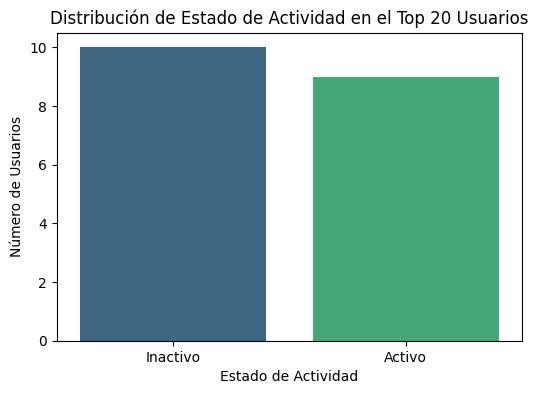

Top 20 usuarios por gasto total, con su país y región:


,uid,gasto_por_usuario,country,region
0,3en4E9nAfFddtyBFK1CQmeq3yeI3,1199.60,United Arab Emirates,Raʼs al Khaymah
1,HLqnZE3uKKaH4GZuagpzhyBhGeg2,1000.00,Pakistan,Punjab
2,yzZevJ0iKbbg5MpsKt1ePufG7K52,627.13,United States,Texas
3,sfCWnQvqb7OEgSDOJDwtXiuMX6f2,599.82,United Arab Emirates,Raʼs al Khaymah
4,FfFAExnaQsMCGcuYWWoyoeOT9o63,570.04,Oman,Al Batinah North
5,0bvtXdEmr6Q3qBlVDJYbYV6BVAI3,499.93,Oman,Muscat
6,50LNdiELAgblehayQBbkuMIiml53,472.84,Tanzania,Dar es Salaam Region
7,bjaFVprABdNJ2aEy3twPFqPX8pL2,471.56,Dominican Republic,Nacional
8,VZEdGP2sUEekNa8EO344QMz7DHJ3,434.37,Colombia,Cesar Department
9,I0ySUdBzVMezanpWvpeQSj4ENxh1,420.10,Myanmar,Kayin State


In [ ]:
# Código 8
import pandas as pd
import json
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
import numpy as np
# Cargar el archivo JSON
with open('rechargeHistory.json') as f:
    data = json.load(f)

# Cargar el segundo archivo JSON
with open('short-term.json', 'r', encoding='utf-8') as f2:
    data2 = json.load(f2)

# Cargar el tercer archivo JSON
with open('privacy.json', 'r', encoding='utf-8') as f3:
    data3 = json.load(f3)

# Cargar el cuarto archivo JSON
with open('userHistory.json', 'r', encoding='utf-8') as f4:
    data4 = json.load(f4)

# Convertir a DataFrame (tabla)
df = pd.json_normalize(data)
df2 = pd.json_normalize(data2)
df3 = pd.json_normalize(data3)
df4 = pd.json_normalize(data4)

# Filtrar el DataFrame (utilizar nada mas status: "Completed", "Admin update", "Overpayment", "Underpayment")
# Usamos .isin() para filtrar por múltiples valores en la columna 'status'
df_filtrado = df[df['status'].isin(["Completed", "Admin update", "Overpayment", "Underpayment"])].copy()

# Convertir la columna 'amount' a numérico en el DataFrame
df_filtrado["amount"] = df_filtrado["amount"].astype(float)


df_filtrado = df_filtrado.dropna(subset=['amount']).copy()

df_filtrado2 = df_filtrado[df_filtrado["paymentMethod"] != "Inactivity fee"].copy()

#filtrado df2
df2_filtrado = df2[df2["status"].isin(["Completed"])].copy()

gasto_usuarios = df_filtrado2.groupby("uid")["amount"].sum().reset_index(name="gasto_por_usuario")

top_20_gasto_usuarios = gasto_usuarios.sort_values(by="gasto_por_usuario", ascending=False).head(20)

print("Top 20 usuarios por gasto total:")
print(top_20_gasto_usuarios)

# Obtener la lista de UIDs de los top 20 usuarios
top_20_uids = top_20_gasto_usuarios['uid'].tolist()

# Filtrar el DataFrame de historial de recargas para incluir solo las recargas de los top 20 usuarios
recargas_top_20_usuarios = df_filtrado2[df_filtrado2['uid'].isin(top_20_uids)].copy()

# Contar la frecuencia de cada método de pago por usuario
metodos_por_usuario = recargas_top_20_usuarios.groupby(['uid', 'paymentMethod']).size().reset_index(name='conteo')

# Encontrar el método de pago más frecuente para cada usuario
metodo_mas_usado_por_usuario = metodos_por_usuario.loc[metodos_por_usuario.groupby('uid')['conteo'].idxmax()]

print("\nMétodo de pago más utilizado por cada usuario del Top 20:")
print(metodo_mas_usado_por_usuario)


# Filtrar el DataFrame de servicios completados para incluir solo las verificaciones de los top 20 usuarios
servicios_top_20_usuarios = df2_filtrado[df2_filtrado['uid'].isin(top_20_uids)].copy()

# Contar la frecuencia de cada servicio utilizado por usuario
servicios_por_usuario = servicios_top_20_usuarios.groupby(['uid', 'service']).size().reset_index(name='conteo')

# Encontrar el servicio más frecuente para cada usuario
servicio_mas_usado_por_usuario = servicios_por_usuario.loc[servicios_por_usuario.groupby('uid')['conteo'].idxmax()]

print("Servicio más utilizado por cada usuario del Top 20 por gasto:")
display(servicio_mas_usado_por_usuario)

# Filtrar el DataFrame completo de servicios (df2) para incluir solo las transacciones de los top 20 usuarios
servicios_top_20_todos_estados = df2[df2['uid'].isin(top_20_uids)].copy()

# Contar el número de transacciones por usuario y estado
conteo_por_estado_usuario = servicios_top_20_todos_estados.groupby(['uid', 'status']).size().unstack(fill_value=0)

# Calcular el total de transacciones por usuario
conteo_por_estado_usuario['Total'] = conteo_por_estado_usuario.sum(axis=1)

# Calcular la tasa de éxito (Completed / Total) y la tasa de fracaso ((Cancelled + Timed Out) / Total)
conteo_por_estado_usuario['Tasa_Exito'] = conteo_por_estado_usuario['Completed'] / conteo_por_estado_usuario['Total']
conteo_por_estado_usuario['Tasa_Fracaso'] = (conteo_por_estado_usuario['Cancelled'] + conteo_por_estado_usuario['Timed Out']) / conteo_por_estado_usuario['Total']


print("Tasa de éxito/fracaso en compras para cada usuario del Top 20:")
display(conteo_por_estado_usuario[['Completed', 'Cancelled', 'Timed Out', 'Total', 'Tasa_Exito', 'Tasa_Fracaso']])


# Filtrar el DataFrame de userHistory para incluir solo los top 20 usuarios
user_history_top_20 = df4[df4['uid'].isin(top_20_uids)].copy()

# Convertir el timestamp de lastLogin a formato de fecha y hora
user_history_top_20["lastLogin_datetime"] = pd.to_datetime(user_history_top_20["lastLogin._seconds"], unit="s")

# Definir el umbral de inactividad (ejemplo: 90 días)
from datetime import datetime, timedelta

umbral_inactividad_dias = 90
fecha_actual = datetime.now()
fecha_umbral_inactividad = fecha_actual - timedelta(days=umbral_inactividad_dias)

print(f"Considerando inactivos a los usuarios que no han iniciado sesión en los últimos {umbral_inactividad_dias} días (desde {fecha_umbral_inactividad.date()}).")

# Clasificar usuarios como activos o inactivos
user_history_top_20['Estado_Actividad'] = user_history_top_20['lastLogin_datetime'].apply(
    lambda x: 'Activo' if x >= fecha_umbral_inactividad else 'Inactivo'
)

# Mostrar el estado de actividad de cada usuario del top 20
print("\nEstado de actividad de los usuarios del Top 20 por gasto:")
display(user_history_top_20[['uid', 'lastLogin_datetime', 'Estado_Actividad']])

#Contar cuántos hay activos e inactivos
conteo_estado_actividad = user_history_top_20['Estado_Actividad'].value_counts()
print("\nResumen de estado de actividad en el Top 20:")
print(conteo_estado_actividad)

#Visualizar el conteo
plt.figure(figsize=(6, 4))
sns.barplot(x=conteo_estado_actividad.index, y=conteo_estado_actividad.values, palette='viridis', hue=conteo_estado_actividad.index, legend=False)
plt.title('Distribución de Estado de Actividad en el Top 20 Usuarios')
plt.xlabel('Estado de Actividad')
plt.ylabel('Número de Usuarios')
plt.show()

# filtrado privacy
privacy_top_20 = df3[df3['uid'].isin(top_20_uids)].copy()

# Combinar los DataFrames top_20_gasto_usuarios y privacy_top_20 usando 'uid' como clave

# Utilizamos un inner merge para asegurarnos de que solo incluimos usuarios que están en ambos DataFrames
top_20_with_location = pd.merge(top_20_gasto_usuarios, privacy_top_20[['uid', 'country', 'region']], on='uid', how='inner')

# Ordenar el DataFrame resultante por 'gasto_por_usuario' de forma descendente
top_20_with_location_sorted = top_20_with_location.sort_values(by='gasto_por_usuario', ascending=False).reset_index(drop=True)

print("Top 20 usuarios por gasto total, con su país y región:")
display(top_20_with_location_sorted)




# Código 9

In [ ]:
# Código 9
import pandas as pd
import numpy as np
from statsmodels.stats.proportion import proportion_confint
import json


with open('short-term.json', 'r', encoding='utf-8') as f2:
    data2 = json.load(f2)
    df2 = pd.json_normalize(data2)

# Contar la frecuencia de cada estado de transacción
status_counts = df2['status'].value_counts()

# Calcular el total de transacciones
total_transactions = status_counts.sum()

# Calcular las probabilidades empíricas
probabilities = status_counts / total_transactions

print("Probabilidades Empíricas de los Estados de Transacción:")
print(probabilities)

print("\n--- Intervalos de Confianza del 95% para las Probabilidades ---")

# Calcular intervalos de confianza para cada estado
# Usaremos el método Wilson score interval, adecuado para proporciones
alpha = 0.05  # Nivel de significancia para un intervalo del 95%

for status, count in status_counts.items():
    # proportion_confint requiere el número de éxitos, el total de observaciones y alpha
    # Para cada estado, el "éxito" es la ocurrencia de ese estado.
    lower, upper = proportion_confint(count, total_transactions, alpha=alpha, method='wilson')
    print(f"Estado '{status}':")
    print(f"  Probabilidad Empírica: {probabilities[status]:.4f}")
    print(f"  Intervalo de Confianza (95%): ({lower:.4f}, {upper:.4f})")

Probabilidades Empíricas de los Estados de Transacción:
status
Completed                 0.608830
Timed Out                 0.311077
Cancelled                 0.066890
Pending                   0.012342
Error cancelling order    0.000860
Name: count, dtype: float64

--- Intervalos de Confianza del 95% para las Probabilidades ---
Estado 'Completed':
  Probabilidad Empírica: 0.6088
  Intervalo de Confianza (95%): (0.6045, 0.6131)
Estado 'Timed Out':
  Probabilidad Empírica: 0.3111
  Intervalo de Confianza (95%): (0.3070, 0.3152)
Estado 'Cancelled':
  Probabilidad Empírica: 0.0669
  Intervalo de Confianza (95%): (0.0647, 0.0691)
Estado 'Pending':
  Probabilidad Empírica: 0.0123
  Intervalo de Confianza (95%): (0.0114, 0.0134)
Estado 'Error cancelling order':
  Probabilidad Empírica: 0.0009
  Intervalo de Confianza (95%): (0.0006, 0.0012)


#Código 10

ANÁLISIS DE DATOS - 7 PREGUNTAS ESPECÍFICAS
Datos cargados: 896 transacciones
Rango de fechas: 2024-02-18 21:46:54.586000 a 2025-05-11 23:17:05.265000

1. DEMANDA E INGRESO BRUTO POR DÍA


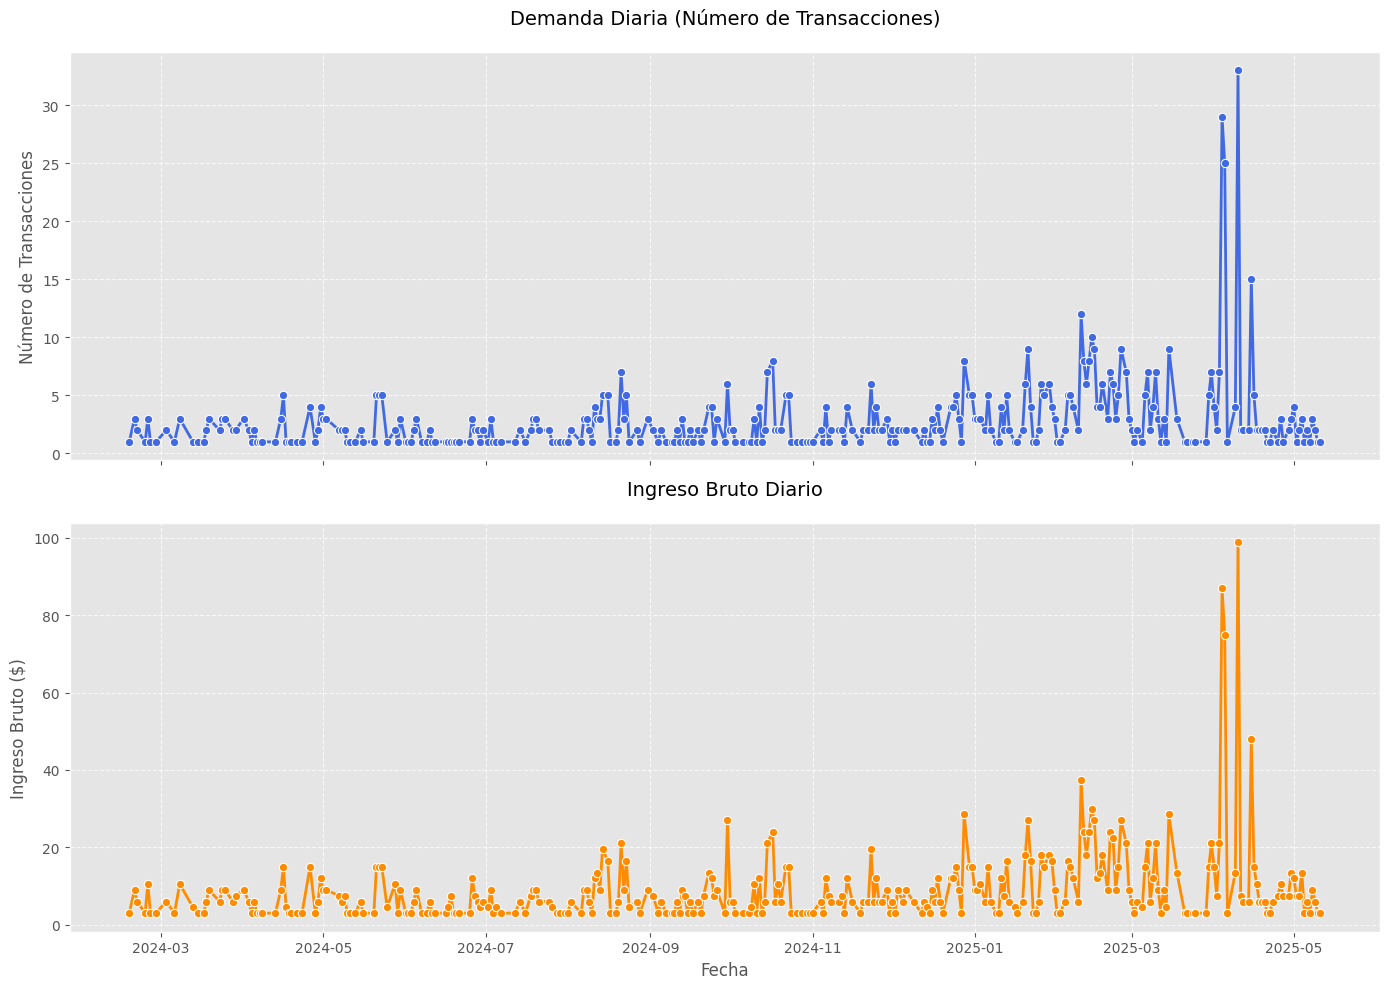

Datos diarios procesados: 315 días

2. ESTADÍSTICOS MUESTRALES

Demanda Diaria:
  n = 315
  Media muestral = 2.8444
  Varianza muestral = 10.9343
  Desviación estándar muestral = 3.3067

Ingreso Bruto Diario:
  n = 315
  Media muestral = 9.1000
  Varianza muestral = 101.2615
  Desviación estándar muestral = 10.0629

3. INTERVALOS DE CONFIANZA PARA μ POBLACIONAL (95%)

Demanda Diaria:
  n = 315
  Media muestral = 2.8444
  Error estándar = 0.1863
  t crítico = 1.9675
  Margen de error = 0.3666
  IC 95%: [2.4779, 3.2110]

Ingreso Bruto Diario:
  n = 315
  Media muestral = 9.1000
  Error estándar = 0.5670
  t crítico = 1.9675
  Margen de error = 1.1156
  IC 95%: [7.9844, 10.2156]

4. TOP 10 SERVICIOS MÁS USADOS


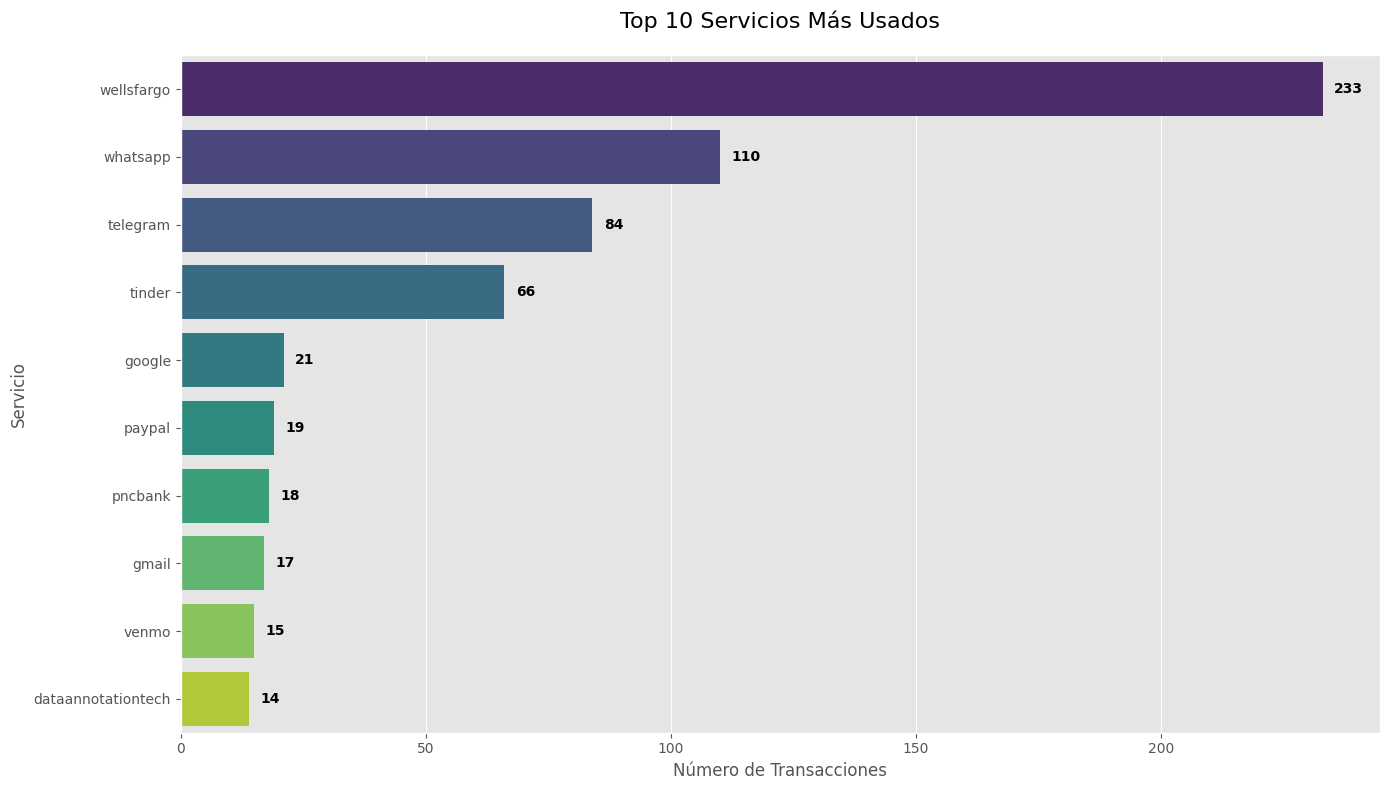


Top 10 servicios más usados:
 1. wellsfargo: 233 transacciones
 2. whatsapp: 110 transacciones
 3. telegram: 84 transacciones
 4. tinder: 66 transacciones
 5. google: 21 transacciones
 6. paypal: 19 transacciones
 7. pncbank: 18 transacciones
 8. gmail: 17 transacciones
 9. venmo: 15 transacciones
10. dataannotationtech: 14 transacciones

5. PROPORCIÓN COMPLETADOS/CANCELADOS


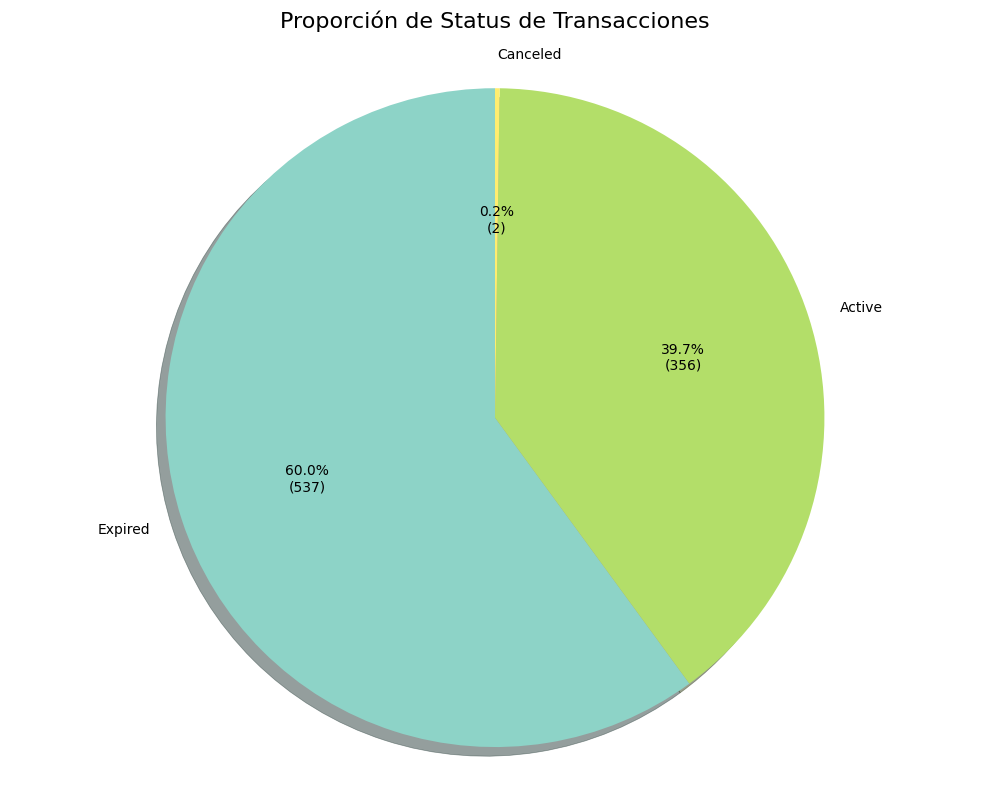


Distribución de status:
  Expired: 538 (60.04%)
  Active: 356 (39.73%)
  Canceled: 2 (0.22%)

6. INGRESO POR DÍA/MES


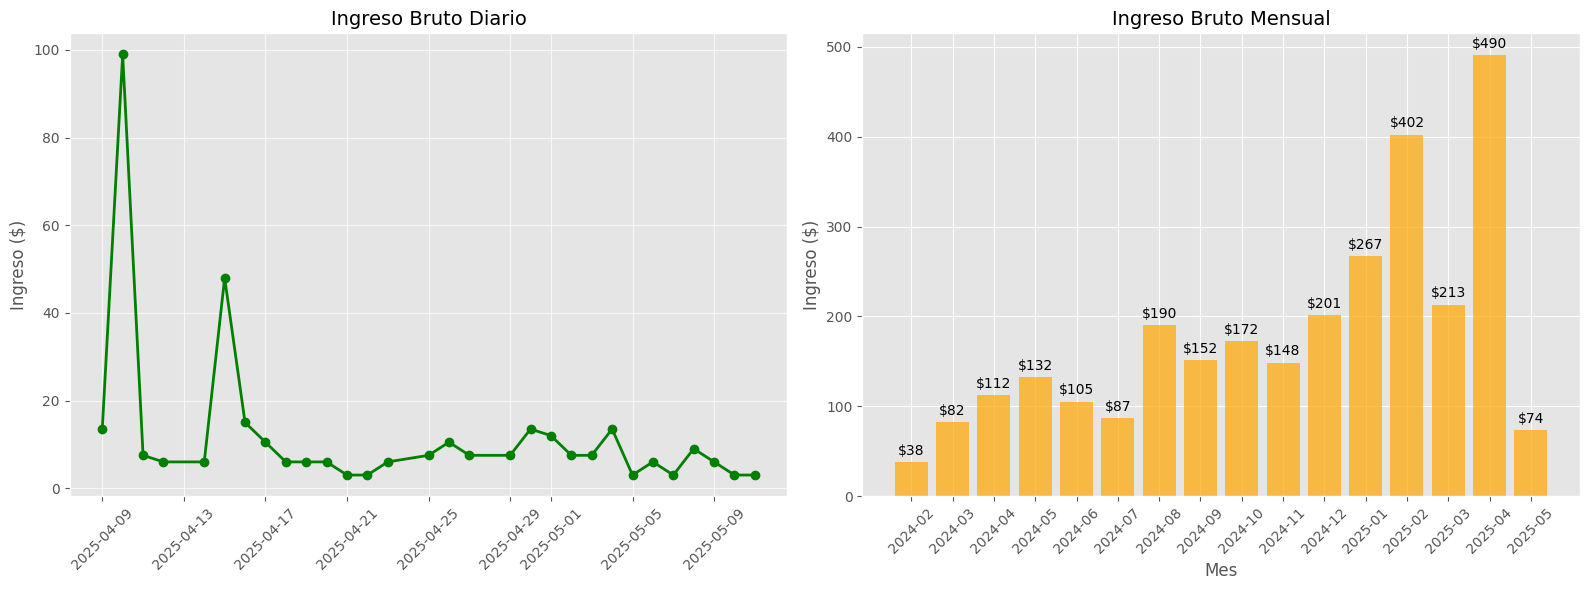


Estadísticas de ingreso diario:
  Total días: 315
  Ingreso promedio diario: $9.10
  Ingreso máximo diario: $99.00
  Ingreso mínimo diario: $3.00

Estadísticas de ingreso mensual:
  Total meses: 16
  Ingreso promedio mensual: $179.16
  Ingreso total: $2866.50

7. IDENTIFICACIÓN DE VALORES ATÍPICOS

Demanda Diaria:
  Q1 = 1.00
  Q3 = 3.00
  IQR = 2.00
  Límite inferior = -2.00
  Límite superior = 6.00
  Outliers encontrados: 22

Ingreso Bruto Diario:
  Q1 = 3.00
  Q3 = 10.50
  IQR = 7.50
  Límite inferior = -8.25
  Límite superior = 21.75
  Outliers encontrados: 17


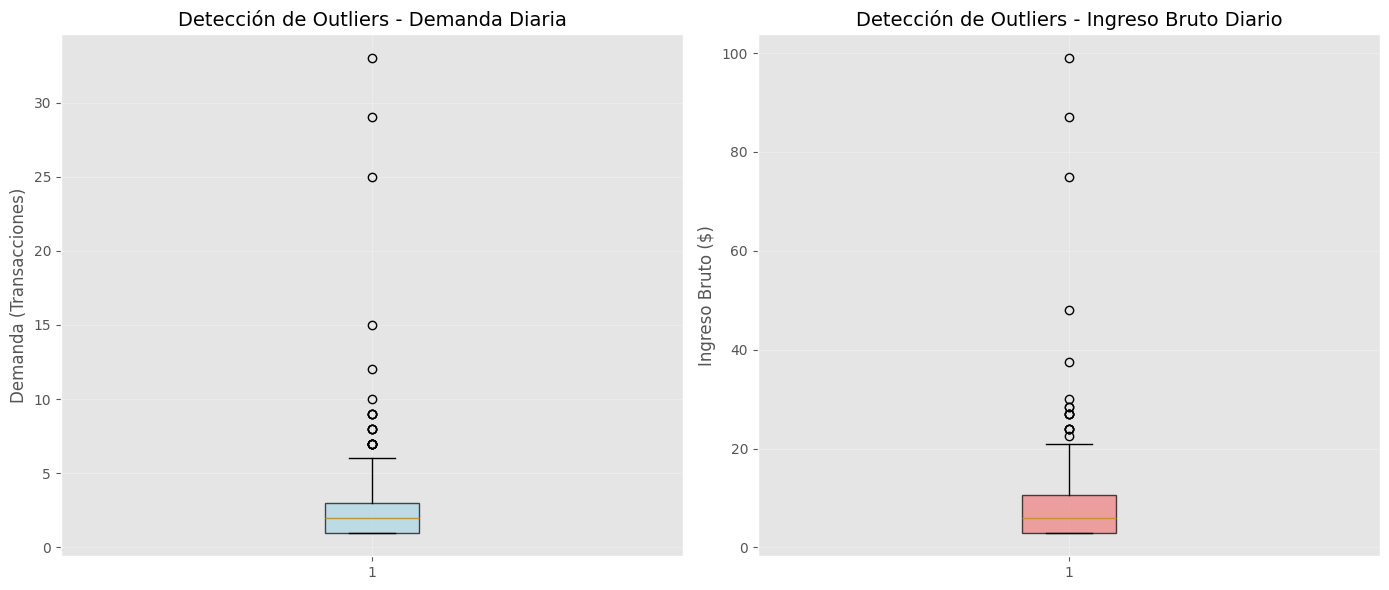


Fechas con outliers en demanda:
  2024-08-21: 7 transacciones
  2024-10-15: 7 transacciones
  2024-10-17: 8 transacciones
  2024-12-28: 8 transacciones
  2025-01-21: 9 transacciones
  2025-02-10: 12 transacciones
  2025-02-11: 8 transacciones
  2025-02-13: 8 transacciones
  2025-02-14: 10 transacciones
  2025-02-15: 9 transacciones
  2025-02-21: 7 transacciones
  2025-02-25: 9 transacciones
  2025-02-27: 7 transacciones
  2025-03-07: 7 transacciones
  2025-03-10: 7 transacciones
  2025-03-15: 9 transacciones
  2025-03-31: 7 transacciones
  2025-04-03: 7 transacciones
  2025-04-04: 29 transacciones
  2025-04-05: 25 transacciones
  2025-04-10: 33 transacciones
  2025-04-15: 15 transacciones

Fechas con outliers en ingreso:
  2024-09-30: $27.00
  2024-10-17: $24.00
  2024-12-28: $28.50
  2025-01-21: $27.00
  2025-02-10: $37.50
  2025-02-11: $24.00
  2025-02-13: $24.00
  2025-02-14: $30.00
  2025-02-15: $27.00
  2025-02-21: $24.00
  2025-02-22: $22.50
  2025-02-25: $27.00
  2025-03-15: $2

In [5]:
#código 10
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from datetime import datetime
import warnings

# Configuración inicial
warnings.filterwarnings('ignore')
plt.style.use('ggplot')
plt.rcParams['figure.figsize'] = (12, 6)
sns.set_palette("husl")

def load_and_prepare_data():
    """Cargar y preparar los datos de transacciones"""
    try:
        # Cargar datos de transacciones
        with open('middle-term.json', 'r') as f:
            transactions_data = json.load(f)

        df = pd.DataFrame(transactions_data)

        # Procesar timestamps
        df['timestamp'] = df['timestamp'].apply(
            lambda x: datetime.fromtimestamp(x['_seconds'] + x['_nanoseconds']/1e9)
        )

        # Limpiar datos de precio
        df['price'] = pd.to_numeric(df['price'], errors='coerce')
        df = df.dropna(subset=['timestamp', 'price'])

        print(f"Datos cargados: {df.shape[0]} transacciones")
        print(f"Rango de fechas: {df['timestamp'].min()} a {df['timestamp'].max()}")

        return df

    except Exception as e:
        print(f"Error al cargar datos: {str(e)}")
        return None

def question_1_daily_demand_income(df):
    """1. Graficar demanda e ingreso bruto por día"""
    print("\n" + "="*50)
    print("1. DEMANDA E INGRESO BRUTO POR DÍA")
    print("="*50)

    # Agrupar por día
    daily = df.groupby(pd.Grouper(key='timestamp', freq='D')).agg(
        demanda=('price', 'count'),  # Número de transacciones
        ingreso_bruto=('price', 'sum')
    ).reset_index()

    # Filtrar días con datos
    daily = daily[daily['demanda'] > 0]

    # Crear gráficos
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

    # Gráfico de demanda
    sns.lineplot(data=daily, x='timestamp', y='demanda', ax=ax1,
                marker='o', color='royalblue', linewidth=2)
    ax1.set_title('Demanda Diaria (Número de Transacciones)', fontsize=14, pad=20)
    ax1.set_ylabel('Número de Transacciones', fontsize=12)
    ax1.grid(True, linestyle='--', alpha=0.7)

    # Gráfico de ingresos
    sns.lineplot(data=daily, x='timestamp', y='ingreso_bruto', ax=ax2,
                marker='o', color='darkorange', linewidth=2)
    ax2.set_title('Ingreso Bruto Diario', fontsize=14, pad=20)
    ax2.set_ylabel('Ingreso Bruto ($)', fontsize=12)
    ax2.set_xlabel('Fecha', fontsize=12)
    ax2.grid(True, linestyle='--', alpha=0.7)

    plt.tight_layout()
    plt.savefig('demanda_ingreso_diario.png', dpi=300, bbox_inches='tight')
    plt.show()

    print(f"Datos diarios procesados: {len(daily)} días")
    return daily

def question_2_sample_statistics(daily):
    """2. Calcular estadísticos muestrales"""
    print("\n" + "="*50)
    print("2. ESTADÍSTICOS MUESTRALES")
    print("="*50)

    results = {}

    for col, name in [('demanda', 'Demanda Diaria'), ('ingreso_bruto', 'Ingreso Bruto Diario')]:
        data = daily[col].dropna()
        n = len(data)

        if n > 1:
            media = np.mean(data)
            varianza = np.var(data, ddof=1)  # Varianza muestral
            desv_std = np.std(data, ddof=1)  # Desviación estándar muestral

            results[name] = {
                'n': n,
                'Media Muestral': media,
                'Varianza Muestral': varianza,
                'Desviación Estándar Muestral': desv_std
            }

            print(f"\n{name}:")
            print(f"  n = {n}")
            print(f"  Media muestral = {media:.4f}")
            print(f"  Varianza muestral = {varianza:.4f}")
            print(f"  Desviación estándar muestral = {desv_std:.4f}")

    return results

def question_3_confidence_intervals(daily):
    """3. Intervalos de confianza para μ poblacional"""
    print("\n" + "="*50)
    print("3. INTERVALOS DE CONFIANZA PARA μ POBLACIONAL (95%)")
    print("="*50)

    confidence = 0.95
    alpha = 1 - confidence

    for col, name in [('demanda', 'Demanda Diaria'), ('ingreso_bruto', 'Ingreso Bruto Diario')]:
        data = daily[col].dropna()
        n = len(data)

        if n > 1:
            media = np.mean(data)
            desv_std = np.std(data, ddof=1)
            error_std = desv_std / np.sqrt(n)

            # Usar distribución t
            t_critical = stats.t.ppf(1 - alpha/2, n-1)
            margen_error = t_critical * error_std

            ci_inferior = media - margen_error
            ci_superior = media + margen_error

            print(f"\n{name}:")
            print(f"  n = {n}")
            print(f"  Media muestral = {media:.4f}")
            print(f"  Error estándar = {error_std:.4f}")
            print(f"  t crítico = {t_critical:.4f}")
            print(f"  Margen de error = {margen_error:.4f}")
            print(f"  IC 95%: [{ci_inferior:.4f}, {ci_superior:.4f}]")

def question_4_top_services(df):
    """4. Top 10 servicios más usados (mediana duración)"""
    print("\n" + "="*50)
    print("4. TOP 10 SERVICIOS MÁS USADOS")
    print("="*50)

    if 'service' not in df.columns:
        print("No hay columna 'service' en los datos")
        return None

    top_10_services = df['service'].value_counts().head(10)

    if len(top_10_services) == 0:
        print("No hay datos de servicios")
        return None

    # Gráfico
    plt.figure(figsize=(14, 8))
    ax = sns.barplot(x=top_10_services.values, y=top_10_services.index,
                    palette="viridis", orient='h')

    plt.title('Top 10 Servicios Más Usados', fontsize=16, pad=20)
    plt.xlabel('Número de Transacciones', fontsize=12)
    plt.ylabel('Servicio', fontsize=12)

    # Añadir valores en las barras
    for i, v in enumerate(top_10_services.values):
        ax.text(v + 0.01 * max(top_10_services.values), i, str(v),
                va='center', fontweight='bold')

    plt.tight_layout()
    plt.savefig('top_10_servicios.png', dpi=300, bbox_inches='tight')
    plt.show()

    print("\nTop 10 servicios más usados:")
    for i, (service, count) in enumerate(top_10_services.items(), 1):
        print(f"{i:2d}. {service}: {count} transacciones")

    return top_10_services

def question_5_completion_proportion(df):
    """5. Proporción Completados/Cancelados"""
    print("\n" + "="*50)
    print("5. PROPORCIÓN COMPLETADOS/CANCELADOS")
    print("="*50)

    if 'status' not in df.columns:
        print("No hay columna 'status' en los datos")
        return None

    status_counts = df['status'].value_counts()
    total = len(df)

    # Gráfico de pastel
    plt.figure(figsize=(10, 8))
    colors = plt.cm.Set3(np.linspace(0, 1, len(status_counts)))

    wedges, texts, autotexts = plt.pie(status_counts.values,
                                      labels=status_counts.index,
                                      autopct=lambda pct: f'{pct:.1f}%\n({int(pct*total/100)})',
                                      startangle=90,
                                      colors=colors,
                                      shadow=True)

    plt.title('Proporción de Status de Transacciones', fontsize=16, pad=20)
    plt.axis('equal')
    plt.tight_layout()
    plt.savefig('proporcion_status.png', dpi=300, bbox_inches='tight')
    plt.show()

    # Calcular proporción específica
    completed = status_counts.get('completed', 0) + status_counts.get('active', 0)
    canceled = status_counts.get('canceled', 0)

    print("\nDistribución de status:")
    for status, count in status_counts.items():
        proportion = count / total * 100
        print(f"  {status}: {count} ({proportion:.2f}%)")

    if completed + canceled > 0:
        completion_rate = completed / (completed + canceled)
        print(f"\nProporción Completados/(Completados+Cancelados): {completion_rate:.4f} ({completion_rate*100:.2f}%)")

    return status_counts

def question_6_income_by_period(df, daily):
    """6. Ingreso por día/mes"""
    print("\n" + "="*50)
    print("6. INGRESO POR DÍA/MES")
    print("="*50)

    # Ingreso mensual
    monthly = df.set_index('timestamp')['price'].resample('M').sum().reset_index()
    monthly.columns = ['mes', 'ingreso_mensual']
    monthly = monthly[monthly['ingreso_mensual'] > 0]

    # Gráficos
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

    # Gráfico diario (últimos 30 días si hay muchos datos)
    daily_plot = daily.tail(30) if len(daily) > 30 else daily
    ax1.plot(daily_plot['timestamp'], daily_plot['ingreso_bruto'],
             marker='o', color='green', linewidth=2)
    ax1.set_title('Ingreso Bruto Diario', fontsize=14)
    ax1.set_ylabel('Ingreso ($)', fontsize=12)
    ax1.tick_params(axis='x', rotation=45)
    ax1.grid(True, alpha=0.7)

    # Gráfico mensual
    if len(monthly) > 0:
        ax2.bar(range(len(monthly)), monthly['ingreso_mensual'],
                color='orange', alpha=0.7)
        ax2.set_title('Ingreso Bruto Mensual', fontsize=14)
        ax2.set_ylabel('Ingreso ($)', fontsize=12)
        ax2.set_xlabel('Mes', fontsize=12)
        ax2.set_xticks(range(len(monthly)))
        ax2.set_xticklabels([f"{d.strftime('%Y-%m')}" for d in monthly['mes']],
                           rotation=45)

        # Añadir valores en las barras
        for i, v in enumerate(monthly['ingreso_mensual']):
            ax2.text(i, v + 0.01 * max(monthly['ingreso_mensual']),
                    f'${v:.0f}', ha='center', va='bottom')

    plt.tight_layout()
    plt.savefig('ingreso_por_periodo.png', dpi=300, bbox_inches='tight')
    plt.show()

    # Mostrar estadísticas
    print(f"\nEstadísticas de ingreso diario:")
    print(f"  Total días: {len(daily)}")
    print(f"  Ingreso promedio diario: ${daily['ingreso_bruto'].mean():.2f}")
    print(f"  Ingreso máximo diario: ${daily['ingreso_bruto'].max():.2f}")
    print(f"  Ingreso mínimo diario: ${daily['ingreso_bruto'].min():.2f}")

    if len(monthly) > 0:
        print(f"\nEstadísticas de ingreso mensual:")
        print(f"  Total meses: {len(monthly)}")
        print(f"  Ingreso promedio mensual: ${monthly['ingreso_mensual'].mean():.2f}")
        print(f"  Ingreso total: ${monthly['ingreso_mensual'].sum():.2f}")

    return monthly

def question_7_outlier_detection(daily):
    """7. Identificar valores atípicos"""
    print("\n" + "="*50)
    print("7. IDENTIFICACIÓN DE VALORES ATÍPICOS")
    print("="*50)

    def detect_outliers(data, column_name):
        """Detectar outliers usando método IQR"""
        if len(data) < 4:
            print(f"Insuficientes datos para detectar outliers en {column_name}")
            return pd.Series(dtype=float), None, None

        Q1 = data.quantile(0.25)
        Q3 = data.quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        outliers = data[(data < lower_bound) | (data > upper_bound)]

        print(f"\n{column_name}:")
        print(f"  Q1 = {Q1:.2f}")
        print(f"  Q3 = {Q3:.2f}")
        print(f"  IQR = {IQR:.2f}")
        print(f"  Límite inferior = {lower_bound:.2f}")
        print(f"  Límite superior = {upper_bound:.2f}")
        print(f"  Outliers encontrados: {len(outliers)}")

        return outliers, lower_bound, upper_bound

    # Detectar outliers para demanda e ingreso
    demanda_outliers, dem_lower, dem_upper = detect_outliers(daily['demanda'], 'Demanda Diaria')
    ingreso_outliers, ing_lower, ing_upper = detect_outliers(daily['ingreso_bruto'], 'Ingreso Bruto Diario')

    # Gráficos de boxplot
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

    # Boxplot demanda
    bp1 = ax1.boxplot(daily['demanda'], patch_artist=True,
                     boxprops=dict(facecolor='lightblue', alpha=0.7))
    ax1.set_title('Detección de Outliers - Demanda Diaria', fontsize=14)
    ax1.set_ylabel('Demanda (Transacciones)', fontsize=12)
    ax1.grid(True, alpha=0.3)

    # Boxplot ingreso
    bp2 = ax2.boxplot(daily['ingreso_bruto'], patch_artist=True,
                     boxprops=dict(facecolor='lightcoral', alpha=0.7))
    ax2.set_title('Detección de Outliers - Ingreso Bruto Diario', fontsize=14)
    ax2.set_ylabel('Ingreso Bruto ($)', fontsize=12)
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig('valores_atipicos.png', dpi=300, bbox_inches='tight')
    plt.show()

    # Mostrar outliers específicos
    if len(demanda_outliers) > 0:
        print(f"\nFechas con outliers en demanda:")
        outlier_dates = daily.loc[demanda_outliers.index]
        for idx, row in outlier_dates.iterrows():
            print(f"  {row['timestamp'].strftime('%Y-%m-%d')}: {row['demanda']:.0f} transacciones")

    if len(ingreso_outliers) > 0:
        print(f"\nFechas con outliers en ingreso:")
        outlier_dates = daily.loc[ingreso_outliers.index]
        for idx, row in outlier_dates.iterrows():
            print(f"  {row['timestamp'].strftime('%Y-%m-%d')}: ${row['ingreso_bruto']:.2f}")

    return demanda_outliers, ingreso_outliers

def main():
    """Función principal que ejecuta las 7 preguntas específicas"""
    print("ANÁLISIS DE DATOS - 7 PREGUNTAS ESPECÍFICAS")
    print("=" * 60)

    # Cargar datos
    df = load_and_prepare_data()
    if df is None:
        print("Error: No se pudieron cargar los datos")
        return

    # Ejecutar las 7 preguntas en orden
    try:
        # 1. Demanda e ingreso por día
        daily = question_1_daily_demand_income(df)

        # 2. Estadísticos muestrales
        stats_results = question_2_sample_statistics(daily)

        # 3. Intervalos de confianza
        question_3_confidence_intervals(daily)

        # 4. Top 10 servicios
        top_services = question_4_top_services(df)

        # 5. Proporción completados/cancelados
        status_results = question_5_completion_proportion(df)

        # 6. Ingreso por día/mes
        monthly_results = question_6_income_by_period(df, daily)

        # 7. Valores atípicos
        outliers = question_7_outlier_detection(daily)

        print("\n" + "="*60)
        print("ANÁLISIS COMPLETADO EXITOSAMENTE")
        print("="*60)
        print("\nArchivos generados:")
        print("- demanda_ingreso_diario.png")
        print("- top_10_servicios.png")
        print("- proporcion_status.png")
        print("- ingreso_por_periodo.png")
        print("- valores_atipicos.png")

    except Exception as e:
        print(f"Error durante el análisis: {str(e)}")
        import traceback
        traceback.print_exc()

# Ejecutar análisis
if __name__ == "__main__":
    main()

In [6]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def load_data():
    """Cargar datos de transacciones y privacidad"""
    with open('middle-term.json', 'r') as f:
        transactions = pd.DataFrame(json.load(f))

    with open('privacy.json', 'r') as f:
        privacy_data = pd.DataFrame(json.load(f))

    return transactions, privacy_data

def process_data(transactions, privacy_data):
    """Procesar y combinar datos de forma limpia"""
    # Limpiar transacciones
    transactions_clean = transactions[['uid', 'price']].copy()
    transactions_clean['price'] = pd.to_numeric(transactions_clean['price'], errors='coerce')
    transactions_clean = transactions_clean.dropna(subset=['price'])

    # Limpiar privacidad - un país por usuario
    privacy_clean = privacy_data[['uid', 'country']].drop_duplicates(subset=['uid'])

    # Combinar datos
    merged_data = pd.merge(transactions_clean, privacy_clean, on='uid', how='left')

    return merged_data

def analyze_countries(data):
    """Análisis de países que más compran números de mediana duración"""
    # Filtrar solo usuarios con país conocido
    data_with_country = data.dropna(subset=['country'])

    country_analysis = data_with_country.groupby('country').agg(
        total_compras=('price', 'sum'),
        num_transacciones=('uid', 'count'),
        usuarios_unicos=('uid', 'nunique')
    ).sort_values('total_compras', ascending=False)

    return country_analysis

def analyze_top_users(data):
    """Top 10 usuarios individuales que más compran mediana duración"""
    user_analysis = data.groupby('uid').agg(
        total_gastado=('price', 'sum'),
        num_compras=('uid', 'count'),
        pais=('country', 'first')
    ).sort_values('total_gastado', ascending=False).head(10)

    return user_analysis

def create_visualizations(country_stats, user_stats):
    """Crear visualizaciones enfocadas"""
    plt.style.use('default')
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

    # Gráfico 1: Top 10 países por compras
    top_10_countries = country_stats.head(10)
    bars1 = ax1.bar(range(len(top_10_countries)), top_10_countries['total_compras'],
                    color='steelblue', alpha=0.8)
    ax1.set_title('Top 10 Países - Compras Números Mediana Duración', fontweight='bold')
    ax1.set_xlabel('País')
    ax1.set_ylabel('Total Compras ($)')
    ax1.set_xticks(range(len(top_10_countries)))
    ax1.set_xticklabels(top_10_countries.index, rotation=45, ha='right')

    # Añadir valores en barras
    for bar, value in zip(bars1, top_10_countries['total_compras']):
        ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10,
                f'${value:.0f}', ha='center', va='bottom', fontsize=9)

    # Gráfico 2: Top 10 usuarios individuales
    bars2 = ax2.bar(range(len(user_stats)), user_stats['total_gastado'],
                    color='darkgreen', alpha=0.8)
    ax2.set_title('Top 10 Usuarios Individuales - Mediana Duración', fontweight='bold')
    ax2.set_xlabel('Usuario (ID parcial)')
    ax2.set_ylabel('Total Gastado ($)')
    ax2.set_xticks(range(len(user_stats)))
    ax2.set_xticklabels([uid[:8] + '...' for uid in user_stats.index],
                       rotation=45, ha='right')

    # Añadir valores en barras
    for bar, value in zip(bars2, user_stats['total_gastado']):
        ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
                f'${value:.0f}', ha='center', va='bottom', fontsize=9)

    plt.tight_layout()
    plt.savefig('analisis_mediana_duracion.png', dpi=300, bbox_inches='tight')
    plt.close()

def display_results(country_stats, user_stats):
    """Mostrar resultados en consola de forma clara"""
    print("\n" + "="*70)
    print("PAÍSES QUE MÁS COMPRAN NÚMEROS DE MEDIANA DURACIÓN")
    print("="*70)
    print(f"{'País':<20} {'Total Compras':<15} {'Transacciones':<15} {'Usuarios':<10}")
    print("-" * 70)

    for country, data in country_stats.head(10).iterrows():
        print(f"{country:<20} ${data['total_compras']:<14.2f} {data['num_transacciones']:<14} {data['usuarios_unicos']:<10}")

    print("\n" + "="*80)
    print("TOP 10 USUARIOS INDIVIDUALES QUE MÁS COMPRAN (MEDIANA DURACIÓN)")
    print("="*80)
    print(f"{'Usuario ID':<25} {'Total Gastado':<15} {'Compras':<10} {'País':<15}")
    print("-" * 80)

    for uid, data in user_stats.iterrows():
        uid_display = uid[:20] + "..." if len(uid) > 20 else uid
        pais_display = data['pais'] if pd.notna(data['pais']) else 'Sin país'
        print(f"{uid_display:<25} ${data['total_gastado']:<14.2f} {data['num_compras']:<9} {pais_display:<15}")

def main():
    print("Cargando datos...")
    transactions, privacy_data = load_data()

    print("Procesando datos...")
    merged_data = process_data(transactions, privacy_data)

    print("Analizando países que más compran...")
    country_stats = analyze_countries(merged_data)

    print("Analizando top 10 usuarios individuales...")
    user_stats = analyze_top_users(merged_data)

    # Mostrar resultados
    display_results(country_stats, user_stats)



    print(f"\n✓ Análisis completado")
    print(f"✓ Gráfico guardado: analisis_mediana_duracion.png")
    print(f"✓ Total países analizados: {len(country_stats)}")
    print(f"✓ Total transacciones procesadas: {len(merged_data)}")

if __name__ == "__main__":
    main()

Cargando datos...
Procesando datos...
Analizando países que más compran...
Analizando top 10 usuarios individuales...

PAÍSES QUE MÁS COMPRAN NÚMEROS DE MEDIANA DURACIÓN
País                 Total Compras   Transacciones   Usuarios  
----------------------------------------------------------------------
United States        $1561.50        494.0          174.0     
Nigeria              $103.50         31.0           13.0      
Canada               $69.00          21.0           9.0       
Oman                 $60.00          20.0           3.0       
Venezuela            $58.50          19.0           4.0       
Dominican Republic   $51.00          17.0           4.0       
Cambodia             $48.00          16.0           2.0       
Belarus              $45.00          15.0           1.0       
Czech Republic       $42.00          14.0           3.0       
Netherlands          $31.50          10.0           5.0       

TOP 10 USUARIOS INDIVIDUALES QUE MÁS COMPRAN (MEDIANA DURACIÓN)


# Código 11

🔎 Iniciando análisis de fees de mantenimiento...

📦 Datos cargados correctamente. Total de registros: 1707

🔎 Verificación de consistencia entre montos individuales y totales mensuales:
Suma total de todos los fees individuales: $3,845.69

Totales mensuales calculados:
timestamp_exacto
2024-01    160.384
2024-02    271.480
2024-03    476.690
2024-04    574.480
2024-05    614.940
2024-06    556.580
2024-07    566.430
2024-08    146.770
2024-09     91.390
2024-10     80.490
2024-11     71.340
2024-12     56.960
2025-01     52.280
2025-02     40.060
2025-03     41.460
2025-04     32.650
2025-05     11.310
Freq: M, Name: amount, dtype: float64

✅ La suma de fees individuales coincide con los totales mensuales


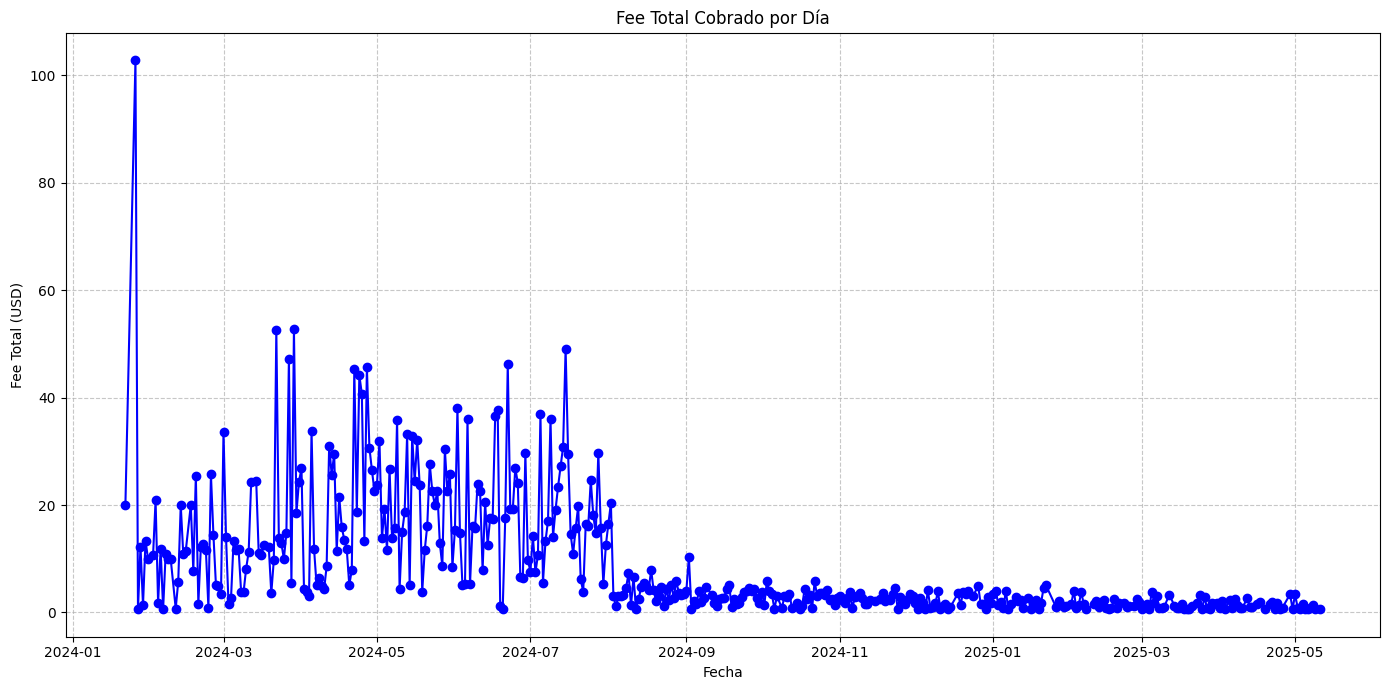


📅 Resumen Diario:
count    438.000000
mean       8.780123
std       11.421111
min        0.600000
25%        1.627500
50%        3.660000
75%       12.510000
max      102.824000
Name: amount, dtype: float64

📅 Resumen Mensual:
timestamp_exacto
2024-01    160.384
2024-02    271.480
2024-03    476.690
2024-04    574.480
2024-05    614.940
2024-06    556.580
2024-07    566.430
2024-08    146.770
2024-09     91.390
2024-10     80.490
2024-11     71.340
2024-12     56.960
2025-01     52.280
2025-02     40.060
2025-03     41.460
2025-04     32.650
2025-05     11.310
Freq: M, Name: amount, dtype: float64

📅 Resumen Anual:
timestamp_exacto
2024    3667.934
2025     177.760
Freq: Y-DEC, Name: amount, dtype: float64

📊 Estadísticas Descriptivas:
Media: 2.25
Varianza: 9.21
Desviación Estándar: 3.04
Mínimo: 0.60
Máximo: 10.00
Mediana: 1.02


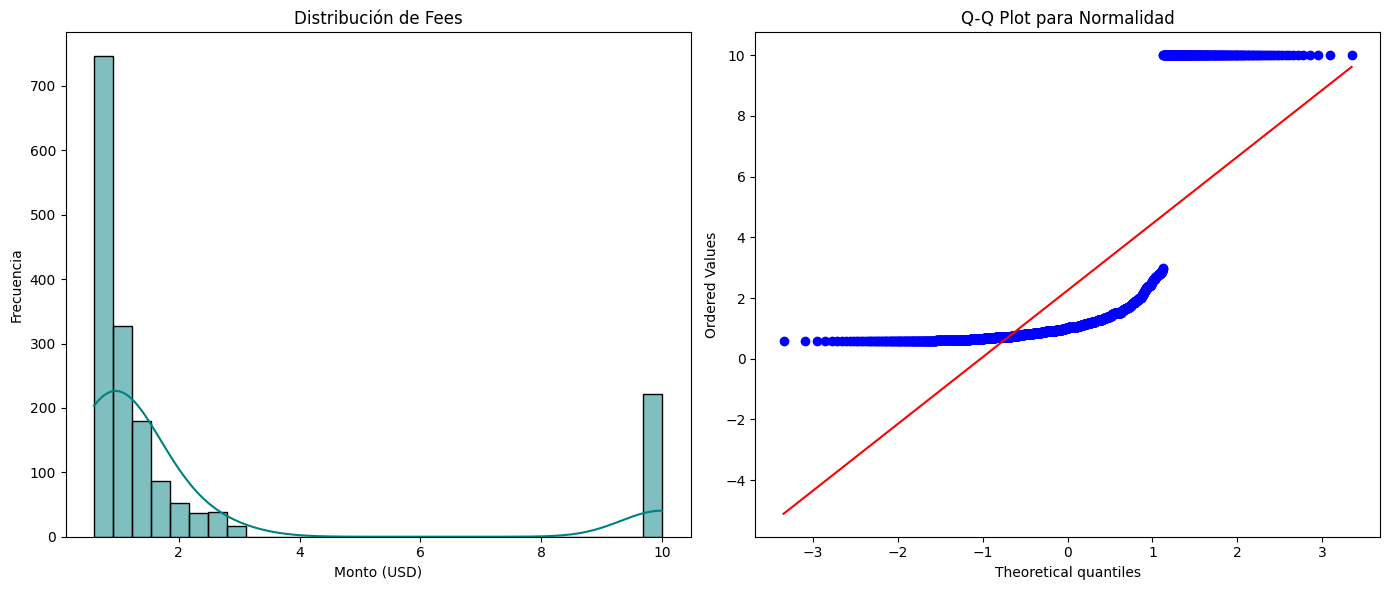


🔍 Prueba de normalidad Shapiro-Wilk: p-value = 0.0000
Los datos NO siguen una distribución normal.

⚠️ Valores atípicos identificados (IQR): 222 registros
      amount        timestamp_exacto
0       10.0 2024-01-22 15:03:09.460
1       10.0 2024-01-22 16:30:32.551
2       10.0 2024-01-26 16:06:14.766
3       10.0 2024-01-26 16:06:15.865
4       10.0 2024-01-26 16:12:25.066
...      ...                     ...
995     10.0 2024-07-28 20:24:22.109
1001    10.0 2024-07-29 20:24:21.727
1009    10.0 2024-07-31 20:24:21.139
1017    10.0 2024-08-01 20:24:20.045
1027    10.0 2024-08-02 20:24:19.895

[222 rows x 2 columns]


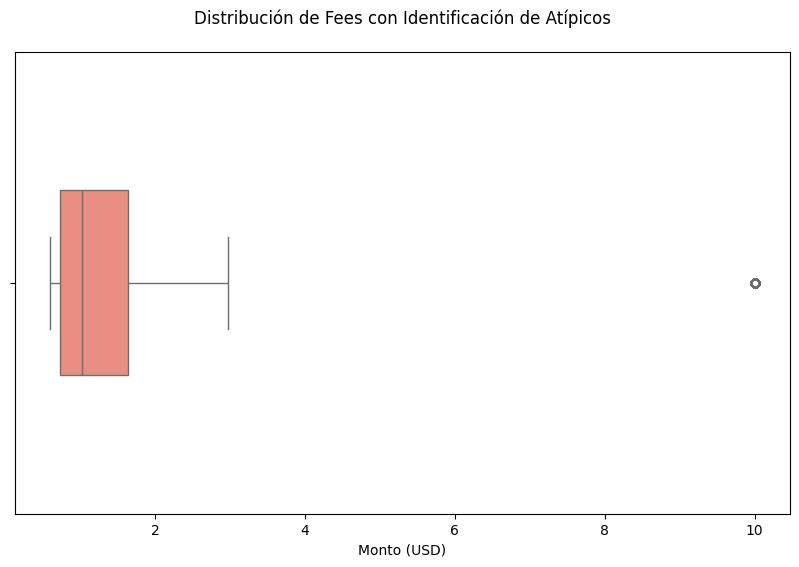


✅ No se encontraron transacciones en el mismo momento exacto

✅ Análisis completado


In [4]:
#código 11
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json
from scipy import stats
import numpy as np
from datetime import datetime

def cargar_y_preparar_datos():
    """Carga y prepara los datos, manejando timestamps con alta precisión"""
    # Cargar datos desde el JSON
    with open('maintenanceFee.json', 'r') as file:
        data = json.load(file)

    df = pd.DataFrame(data)

    # Limpieza y preparación de datos
    # Convertir amount a float (ya que 10.000 = 10.0)
    df['amount'] = df['amount'].astype(float)

    # Convertir timestamps con alta precisión
    df['timestamp_exacto'] = df['timestamp'].apply(
        lambda x: datetime.fromtimestamp(x['_seconds']).replace(microsecond=x['_nanoseconds']//1000)
    )

  # limpiar columna amount que no sea 0
    df = df[df['amount'] != 0]

    return df

def analizar_fees_temporales(df):
    """Analiza los fees agrupados por diferentes periodos temporales"""
    # 1. Gráfico de fees diarios
    fees_diarios = df.groupby(df['timestamp_exacto'].dt.date)['amount'].sum()

    plt.figure(figsize=(14, 7))
    fees_diarios.plot(kind='line', title='Fee Total Cobrado por Día', color='blue', marker='o')
    plt.xlabel('Fecha')
    plt.ylabel('Fee Total (USD)')
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

    # 2. Resúmenes temporales
    print("\n📅 Resumen Diario:")
    print(fees_diarios.describe())

    print("\n📅 Resumen Mensual:")
    fees_mensuales = df.groupby(df['timestamp_exacto'].dt.to_period('M'))['amount'].sum()
    print(fees_mensuales)

    print("\n📅 Resumen Anual:")
    fees_anuales = df.groupby(df['timestamp_exacto'].dt.to_period('Y'))['amount'].sum()
    print(fees_anuales)

    return fees_diarios, fees_mensuales, fees_anuales

def analisis_estadistico(df):
    """Realiza análisis estadístico de los montos"""
    # 3. Estadísticas muestrales
    stats_dict = {
        'Media': df['amount'].mean(),
        'Varianza': df['amount'].var(ddof=1),
        'Desviación Estándar': df['amount'].std(ddof=1),
        'Mínimo': df['amount'].min(),
        'Máximo': df['amount'].max(),
        'Mediana': df['amount'].median()
    }

    print("\n📊 Estadísticas Descriptivas:")
    for k, v in stats_dict.items():
        print(f"{k}: {v:.2f}")

    return stats_dict

def analizar_distribucion(df):
    """Analiza la distribución de los fees"""
    # 4. Análisis de distribución
    plt.figure(figsize=(14, 6))

    # Histograma con KDE
    plt.subplot(1, 2, 1)
    sns.histplot(df['amount'], kde=True, bins=30, color='teal')
    plt.title('Distribución de Fees')
    plt.xlabel('Monto (USD)')
    plt.ylabel('Frecuencia')

    # QQ-plot para normalidad
    plt.subplot(1, 2, 2)
    stats.probplot(df['amount'], dist="norm", plot=plt)
    plt.title('Q-Q Plot para Normalidad')

    plt.tight_layout()
    plt.show()

    # Prueba de normalidad
    stat, p = stats.shapiro(df['amount'])
    print(f"\n🔍 Prueba de normalidad Shapiro-Wilk: p-value = {p:.4f}")
    print("Los datos siguen una distribución normal." if p > 0.05 else "Los datos NO siguen una distribución normal.")

def identificar_atipicos(df):
    """Identifica y analiza valores atípicos"""
    # 5. Identificación de atípicos
    Q1 = df['amount'].quantile(0.25)
    Q3 = df['amount'].quantile(0.75)
    IQR = Q3 - Q1
    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    atipicos = df[(df['amount'] < limite_inferior) | (df['amount'] > limite_superior)]

    print(f"\n⚠️ Valores atípicos identificados (IQR): {len(atipicos)} registros")
    print(atipicos[['amount', 'timestamp_exacto']].sort_values('timestamp_exacto'))

    # Gráfico de caja mejorado
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=df['amount'], color='salmon', width=0.4)
    plt.title('Distribución de Fees con Identificación de Atípicos', pad=20)
    plt.xlabel('Monto (USD)')
    plt.show()

    return atipicos

def analizar_transacciones_duplicadas(df):
    """Analiza transacciones en el mismo momento exacto"""
    # Agrupar por timestamp exacto
    transacciones_por_momento = df.groupby('timestamp_exacto').size()
    duplicados = transacciones_por_momento[transacciones_por_momento > 1]

    if not duplicados.empty:
        print(f"\n🔍 Se encontraron {len(duplicados)} momentos con transacciones duplicadas:")
        for timestamp, count in duplicados.items():
            print(f"🕒 {timestamp}: {count} transacciones")

        # Mostrar ejemplos
        ejemplos = df[df['timestamp_exacto'].isin(duplicados.index)].sort_values('timestamp_exacto')
        print("\nEjemplos de transacciones duplicadas:")
        print(ejemplos[['timestamp_exacto', 'amount', 'uid']].head(10))
    else:
        print("\n✅ No se encontraron transacciones en el mismo momento exacto")

def verificar_consistencia_totales(df):
    """Verifica la consistencia entre los montos individuales y los totales mensuales"""
    print("\n🔎 Verificación de consistencia entre montos individuales y totales mensuales:")

    # Calcular suma total de todos los fees individuales
    suma_total = df['amount'].sum()
    print(f"Suma total de todos los fees individuales: ${suma_total:,.2f}")

    # Calcular totales mensuales
    resumen_mensual = df.groupby(df['timestamp_exacto'].dt.to_period('M'))['amount'].sum()
    print("\nTotales mensuales calculados:")
    print(resumen_mensual)

    # Verificar si la suma de todos los fees coincide con la suma de los totales mensuales
    if abs(suma_total - resumen_mensual.sum()) < 0.01:
        print("\n✅ La suma de fees individuales coincide con los totales mensuales")
    else:
        print("\n⚠️ Advertencia: Hay discrepancia entre la suma de fees individuales y los totales mensuales")

def main():
    print("🔎 Iniciando análisis de fees de mantenimiento...")

    # 1. Cargar y preparar datos
    df = cargar_y_preparar_datos()
    print(f"\n📦 Datos cargados correctamente. Total de registros: {len(df)}")

    # Verificación inicial de consistencia
    verificar_consistencia_totales(df)

    # 2. Análisis temporal
    analizar_fees_temporales(df)

    # 3. Análisis estadístico
    analisis_estadistico(df)

    # 4. Análisis de distribución
    analizar_distribucion(df)

    # 5. Identificación de atípicos
    identificar_atipicos(df)

    # 6. Análisis de transacciones duplicadas
    analizar_transacciones_duplicadas(df)


    print("\n✅ Análisis completado")

if __name__ == "__main__":
    main()

#Código 12

🚀 INICIANDO ANÁLISIS COMPLETO DE CLUSTERING
📁 Usando archivo: short-term.json
Total de registros cargados: 48856
Servicios completados: 29745

=== TABLA DE SERVICIOS ===
                     Servicio  Veces_Usado  Ingresos_Totales
                        Gmail         4247           3251.61
                       Tinder         2916           2852.13
                     Whatsapp         2134           2482.92
                       Paypal         2116           2016.42
                       Google         1632           1316.53
           Service Not Listed          793           1245.93
                     Telegram         1068           1218.31
                        Hinge          954           1048.23
                         Ebay         1519            947.55
               Plenty of fish         1630            917.41
                       Bumble         1043            653.72
                       Amazon          768            645.07
                     Doordash        

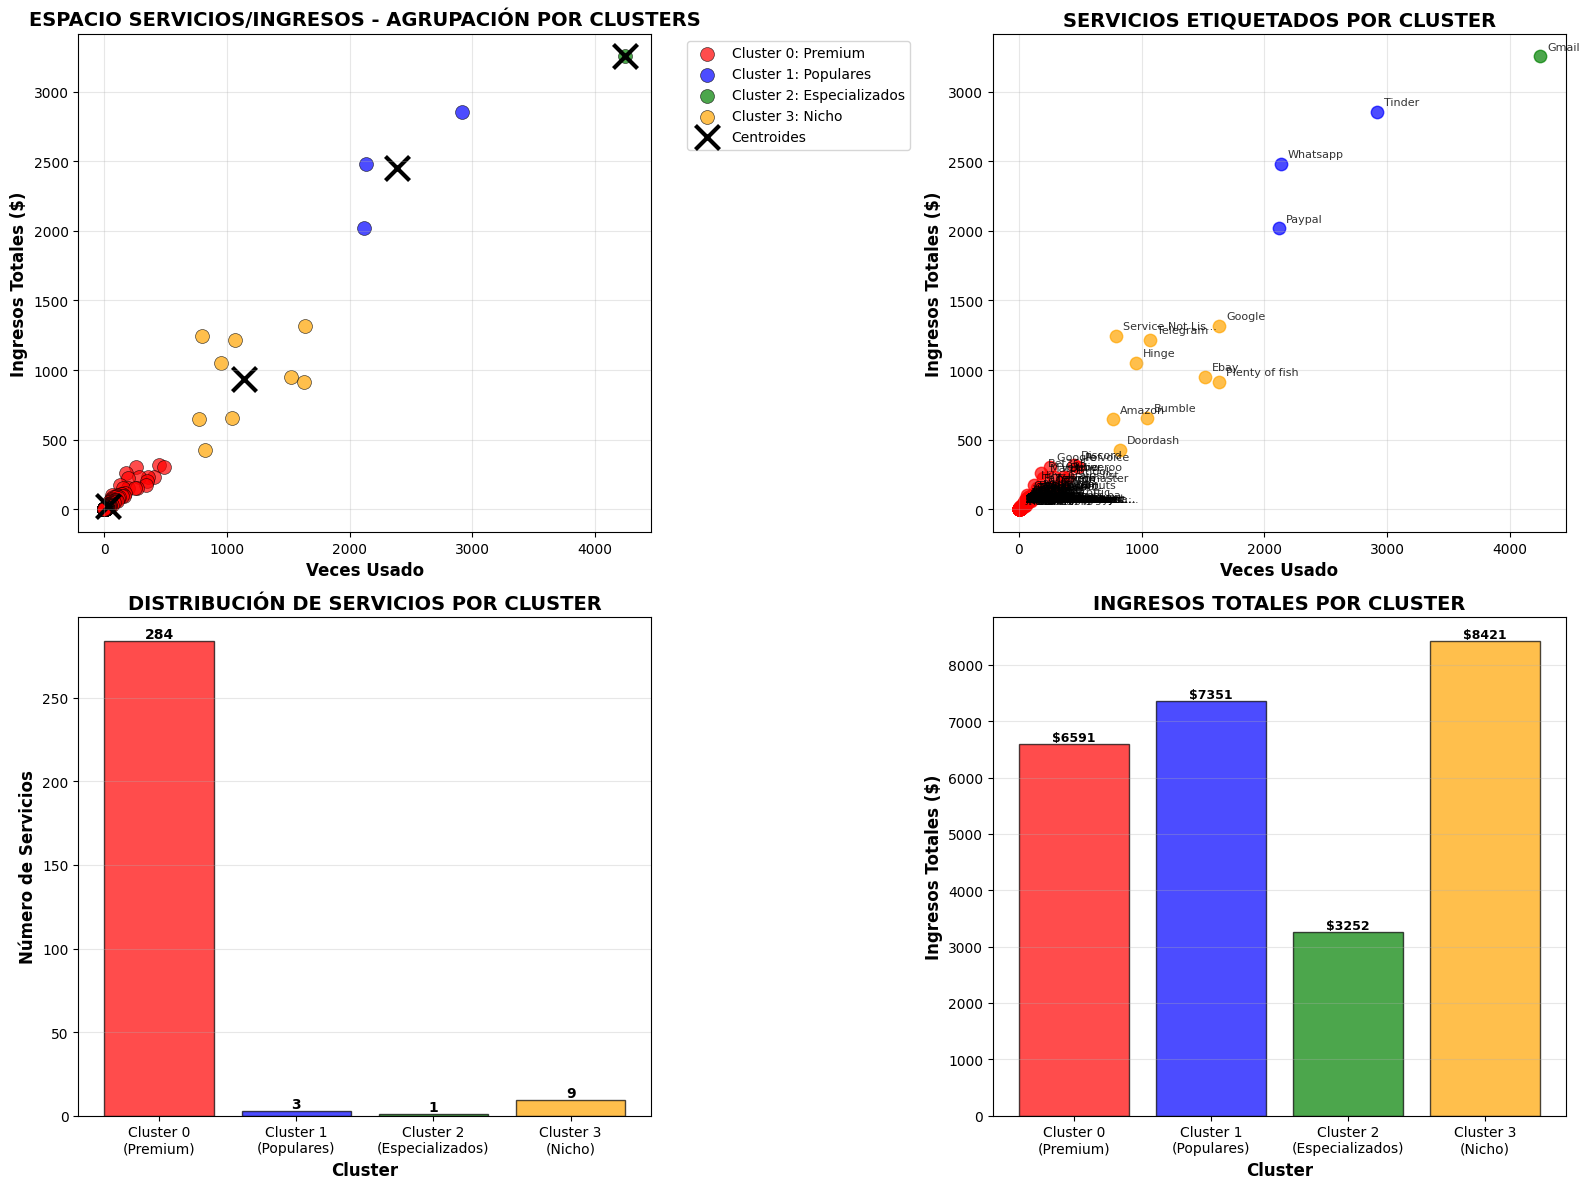

📊 ¡Visualización del espacio servicios/ingresos generada!
💾 Archivo guardado: clustering_servicios_visualizacion.png

🔍 INTERPRETACIÓN DETALLADA DE LOS 4 GRUPOS:

🏆 SERVICIOS PREMIUM - Alto volumen y altos ingresos
------------------------------------------------------------
📊 ESTADÍSTICAS:
   • Total de servicios: 284
   • Promedio de usos: 29
   • Promedio de ingresos: $23.21
   • Ingresos totales del grupo: $6591.35

🏪 SERVICIOS EN ESTE GRUPO:
   • Discord: 448 usos, $315.60
   • Pof: 483 usos, $304.95
   • Google voice: 256 usos, $303.22
   • Bet365: 180 usos, $259.42
   • Uber: 403 usos, $232.33
   • Deliveroo: 358 usos, $230.96
   • Venmo: 284 usos, $230.92
   • Match: 195 usos, $224.25
   • Outlook: 351 usos, $204.91
   • Craigslist: 340 usos, $175.23
   • Hily: 125 usos, $173.86
   • Chevron: 191 usos, $155.91
   • Facebook: 150 usos, $154.11
   • Yahoo: 268 usos, $152.96
   • Ticketmaster: 248 usos, $151.62
   • Youtube: 167 usos, $113.74
   • Instagram: 135 usos, $110.78
   •

In [7]:
#código 12
import json
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import euclidean, cityblock, cosine  # Cambio: manhattan -> cityblock
import warnings
warnings.filterwarnings('ignore')

def crear_tabla_servicios():
    """
    PASO 1: Lee el archivo JSON y crea la tabla base
    (Continuación del código anterior)
    """
    try:
        # Leer el archivo JSON
        with open('short-term.json', 'r', encoding='utf-8') as archivo:
            datos = json.load(archivo)

        # Convertir a DataFrame
        df = pd.DataFrame(datos)
        print(f"Total de registros cargados: {len(df)}")

        # Filtrar solo los servicios completados
        df_completados = df[df['status'] == 'Completed'].copy()
        print(f"Servicios completados: {len(df_completados)}")

        # Crear la tabla resumen con las 3 columnas solicitadas
        tabla_servicios = df_completados.groupby('service').agg({
            'id': 'count',  # Veces que se usó el servicio
            'price': 'sum'  # Ingresos totales por servicio
        }).reset_index()

        # Renombrar columnas para mayor claridad
        tabla_servicios.columns = ['Servicio', 'Veces_Usado', 'Ingresos_Totales']

        # Ordenar por ingresos totales de mayor a menor
        tabla_servicios = tabla_servicios.sort_values('Ingresos_Totales', ascending=False)

        # Mostrar la tabla
        print("\n=== TABLA DE SERVICIOS ===")
        print(tabla_servicios.to_string(index=False))

        return tabla_servicios, df_completados

    except FileNotFoundError:
        print("Error: No se encontró el archivo 'short-term.json'")
        return None, None
    except json.JSONDecodeError:
        print("Error: El archivo no tiene un formato JSON válido")
        return None, None
    except Exception as e:
        print(f"Error inesperado: {e}")
        return None, None

def elegir_y_justificar_frecuencia():
    """
    PASO 2: Elige y justifica la frecuencia de análisis
    """
    print("\n" + "="*60)
    print("PASO 2: ELECCIÓN Y JUSTIFICACIÓN DE FRECUENCIA")
    print("="*60)

    frecuencias = {
        'diaria': {
            'factor': 365,
            'ventajas': ['Máximo nivel de detalle', 'Detecta patrones diarios', 'Ideal para servicios de alta frecuencia'],
            'desventajas': ['Mucho ruido en los datos', 'Variaciones muy grandes', 'Difícil interpretación']
        },
        'semanal': {
            'factor': 52,
            'ventajas': ['Balance entre detalle y estabilidad', 'Captura patrones semanales', 'Reduce ruido diario'],
            'desventajas': ['Menos detalle que diario', 'Puede perder algunos patrones específicos']
        },
        'mensual': {
            'factor': 12,
            'ventajas': ['Datos muy estables', 'Elimina variaciones de corto plazo', 'Ideal para análisis estratégico'],
            'desventajas': ['Pierde detalles importantes', 'Menos sensible a cambios']
        }
    }

    # ELECCIÓN: SEMANAL
    frecuencia_elegida = 'semanal'

    print(f"🎯 FRECUENCIA SELECCIONADA: {frecuencia_elegida.upper()}")
    print("\n📋 ANÁLISIS COMPARATIVO:")

    for freq, info in frecuencias.items():
        marca = "✅ ELEGIDA" if freq == frecuencia_elegida else "❌"
        print(f"\n{marca} {freq.upper()} (Factor: {info['factor']}):")
        print(f"   Ventajas: {', '.join(info['ventajas'])}")
        print(f"   Desventajas: {', '.join(info['desventajas'])}")

    print(f"\n🏆 JUSTIFICACIÓN FINAL:")
    print(f"   Se eligió SEMANAL porque ofrece el mejor balance entre:")
    print(f"   • Detalle suficiente para análisis operativo")
    print(f"   • Estabilidad para patrones de comportamiento")
    print(f"   • Reducción de ruido de variaciones diarias")
    print(f"   • Facilidad de interpretación para toma de decisiones")

    return frecuencia_elegida, frecuencias[frecuencia_elegida]['factor']

def calcular_distancias_con_bucles(tabla_servicios):
    """
    PASO 3: Calcula distancias euclidianas usando bucles iterativos
    """
    print("\n" + "="*60)
    print("PASO 3: CÁLCULO DE DISTANCIAS CON BUCLES")
    print("="*60)

    servicios = tabla_servicios['Servicio'].tolist()
    n_servicios = len(servicios)

    print(f"📊 Calculando distancias entre {n_servicios} servicios...")
    print(f"🔄 Total de cálculos a realizar: {n_servicios * (n_servicios - 1) // 2}")

    # Matriz para almacenar distancias
    matriz_distancias = np.zeros((n_servicios, n_servicios))

    # Normalizar datos para cálculo justo de distancias
    scaler = StandardScaler()
    datos_norm = scaler.fit_transform(tabla_servicios[['Veces_Usado', 'Ingresos_Totales']])

    print("\n🔄 Iterando sobre cada par de servicios...")

    # BUCLES ANIDADOS para calcular distancias
    distancias_detalle = []

    for i in range(n_servicios):
        for j in range(i + 1, n_servicios):  # Solo mitad superior para evitar duplicados

            # Obtener datos de ambos servicios
            servicio_i = servicios[i]
            servicio_j = servicios[j]

            # Datos originales
            veces_i = tabla_servicios.iloc[i]['Veces_Usado']
            ingresos_i = tabla_servicios.iloc[i]['Ingresos_Totales']
            veces_j = tabla_servicios.iloc[j]['Veces_Usado']
            ingresos_j = tabla_servicios.iloc[j]['Ingresos_Totales']

            # Datos normalizados para distancia
            punto_i = datos_norm[i]
            punto_j = datos_norm[j]

            # Calcular DISTANCIA EUCLIDIANA manualmente
            distancia_euclidiana = np.sqrt((punto_i[0] - punto_j[0])**2 + (punto_i[1] - punto_j[1])**2)

            # Guardar en matriz
            matriz_distancias[i][j] = distancia_euclidiana
            matriz_distancias[j][i] = distancia_euclidiana  # Simétrica

            # Guardar detalles para análisis
            distancias_detalle.append({
                'Servicio_1': servicio_i,
                'Servicio_2': servicio_j,
                'Veces_1': veces_i,
                'Ingresos_1': ingresos_i,
                'Veces_2': veces_j,
                'Ingresos_2': ingresos_j,
                'Distancia_Euclidiana': distancia_euclidiana
            })

    # Convertir a DataFrame para análisis
    df_distancias_detalle = pd.DataFrame(distancias_detalle)
    df_distancias_detalle = df_distancias_detalle.sort_values('Distancia_Euclidiana')

    print(f"✅ Cálculo completado!")
    print(f"\n🎯 TOP 10 PARES DE SERVICIOS MÁS SIMILARES (menor distancia):")
    print("-" * 80)

    for idx, fila in df_distancias_detalle.head(10).iterrows():
        print(f"{idx+1:2d}. {fila['Servicio_1']} ↔ {fila['Servicio_2']}")
        print(f"    Distancia: {fila['Distancia_Euclidiana']:.4f}")
        print(f"    {fila['Servicio_1']}: {fila['Veces_1']} usos, ${fila['Ingresos_1']:.2f}")
        print(f"    {fila['Servicio_2']}: {fila['Veces_2']} usos, ${fila['Ingresos_2']:.2f}")
        print()

    return matriz_distancias, df_distancias_detalle

def aplicar_clustering_con_interpretacion(tabla_servicios, n_clusters=4):
    """
    PASO 4: Aplica clustering y proporciona interpretación detallada
    """
    print("\n" + "="*60)
    print("PASO 4: CLUSTERING Y INTERPRETACIÓN DE GRUPOS")
    print("="*60)

    # Preparar datos
    X = tabla_servicios[['Veces_Usado', 'Ingresos_Totales']].values
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    # Aplicar K-means
    print(f"🤖 Aplicando K-means con {n_clusters} clusters...")
    kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
    clusters = kmeans.fit_predict(X_scaled)

    # Agregar clusters a la tabla
    tabla_con_clusters = tabla_servicios.copy()
    tabla_con_clusters['Cluster'] = clusters

    # Calcular métricas de calidad
    silhouette_avg = silhouette_score(X_scaled, clusters)
    print(f"📊 Silhouette Score: {silhouette_avg:.3f}")

    if silhouette_avg > 0.7:
        calidad = "EXCELENTE"
    elif silhouette_avg > 0.5:
        calidad = "BUENA"
    elif silhouette_avg > 0.3:
        calidad = "ACEPTABLE"
    else:
        calidad = "NECESITA MEJORA"

    print(f"🎯 Calidad del clustering: {calidad}")

    # CREAR VISUALIZACIONES DEL ESPACIO SERVICIOS/INGRESOS
    print(f"\n📊 GENERANDO VISUALIZACIONES DEL ESPACIO SERVICIOS/INGRESOS...")

    # Configurar el estilo de las gráficas
    plt.style.use('default')
    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(16, 12))

    # GRÁFICA 1: Scatter plot principal con clusters
    colores = ['red', 'blue', 'green', 'orange', 'purple', 'brown', 'pink', 'gray']
    nombres_clusters = ['Premium', 'Populares', 'Especializados', 'Nicho', 'Extra1', 'Extra2', 'Extra3', 'Extra4']

    for i in range(n_clusters):
        cluster_data = tabla_con_clusters[tabla_con_clusters['Cluster'] == i]
        ax1.scatter(cluster_data['Veces_Usado'],
                   cluster_data['Ingresos_Totales'],
                   c=colores[i],
                   label=f'Cluster {i}: {nombres_clusters[i]}',
                   alpha=0.7,
                   s=100,
                   edgecolors='black',
                   linewidth=0.5)

    # Añadir centroides
    centroides_originales = scaler.inverse_transform(kmeans.cluster_centers_)
    ax1.scatter(centroides_originales[:, 0],
               centroides_originales[:, 1],
               c='black',
               marker='x',
               s=300,
               linewidths=3,
               label='Centroides')

    ax1.set_xlabel('Veces Usado', fontsize=12, fontweight='bold')
    ax1.set_ylabel('Ingresos Totales ($)', fontsize=12, fontweight='bold')
    ax1.set_title('ESPACIO SERVICIOS/INGRESOS - AGRUPACIÓN POR CLUSTERS',
                  fontsize=14, fontweight='bold')
    ax1.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    ax1.grid(True, alpha=0.3)

    # GRÁFICA 2: Gráfica con nombres de servicios
    for i in range(n_clusters):
        cluster_data = tabla_con_clusters[tabla_con_clusters['Cluster'] == i]
        ax2.scatter(cluster_data['Veces_Usado'],
                   cluster_data['Ingresos_Totales'],
                   c=colores[i],
                   alpha=0.7,
                   s=80)

    # Añadir nombres de servicios
    for idx, row in tabla_con_clusters.iterrows():
        ax2.annotate(row['Servicio'][:15] + ('...' if len(row['Servicio']) > 15 else ''),
                    (row['Veces_Usado'], row['Ingresos_Totales']),
                    xytext=(5, 5),
                    textcoords='offset points',
                    fontsize=8,
                    alpha=0.8)

    ax2.set_xlabel('Veces Usado', fontsize=12, fontweight='bold')
    ax2.set_ylabel('Ingresos Totales ($)', fontsize=12, fontweight='bold')
    ax2.set_title('SERVICIOS ETIQUETADOS POR CLUSTER', fontsize=14, fontweight='bold')
    ax2.grid(True, alpha=0.3)

    # GRÁFICA 3: Distribución de servicios por cluster
    cluster_counts = tabla_con_clusters['Cluster'].value_counts().sort_index()
    bars = ax3.bar(range(n_clusters), cluster_counts.values,
                   color=[colores[i] for i in range(n_clusters)],
                   alpha=0.7,
                   edgecolor='black')

    # Añadir valores en las barras
    for i, bar in enumerate(bars):
        height = bar.get_height()
        ax3.text(bar.get_x() + bar.get_width()/2., height,
                f'{int(height)}',
                ha='center', va='bottom', fontweight='bold')

    ax3.set_xlabel('Cluster', fontsize=12, fontweight='bold')
    ax3.set_ylabel('Número de Servicios', fontsize=12, fontweight='bold')
    ax3.set_title('DISTRIBUCIÓN DE SERVICIOS POR CLUSTER', fontsize=14, fontweight='bold')
    ax3.set_xticks(range(n_clusters))
    ax3.set_xticklabels([f'Cluster {i}\n({nombres_clusters[i]})' for i in range(n_clusters)])
    ax3.grid(True, alpha=0.3, axis='y')

    # GRÁFICA 4: Ingresos totales por cluster
    ingresos_por_cluster = tabla_con_clusters.groupby('Cluster')['Ingresos_Totales'].sum()
    bars2 = ax4.bar(range(n_clusters), ingresos_por_cluster.values,
                    color=[colores[i] for i in range(n_clusters)],
                    alpha=0.7,
                    edgecolor='black')

    # Añadir valores en las barras
    for i, bar in enumerate(bars2):
        height = bar.get_height()
        ax4.text(bar.get_x() + bar.get_width()/2., height,
                f'${height:.0f}',
                ha='center', va='bottom', fontweight='bold', fontsize=9)

    ax4.set_xlabel('Cluster', fontsize=12, fontweight='bold')
    ax4.set_ylabel('Ingresos Totales ($)', fontsize=12, fontweight='bold')
    ax4.set_title('INGRESOS TOTALES POR CLUSTER', fontsize=14, fontweight='bold')
    ax4.set_xticks(range(n_clusters))
    ax4.set_xticklabels([f'Cluster {i}\n({nombres_clusters[i]})' for i in range(n_clusters)])
    ax4.grid(True, alpha=0.3, axis='y')

    plt.tight_layout()
    plt.savefig('clustering_servicios_visualizacion.png', dpi=300, bbox_inches='tight')
    plt.show()

    print(f"📊 ¡Visualización del espacio servicios/ingresos generada!")
    print(f"💾 Archivo guardado: clustering_servicios_visualizacion.png")

    # INTERPRETACIÓN DETALLADA DE CADA GRUPO
    print(f"\n🔍 INTERPRETACIÓN DETALLADA DE LOS {n_clusters} GRUPOS:")
    print("="*80)

    # Definir características de cada grupo
    interpretaciones = {
        0: "🏆 SERVICIOS PREMIUM - Alto volumen y altos ingresos",
        1: "📈 SERVICIOS POPULARES - Volumen medio, ingresos medios",
        2: "💎 SERVICIOS ESPECIALIZADOS - Bajo volumen, ingresos específicos",
        3: "🎯 SERVICIOS NICHO - Características particulares"
    }

    for cluster_id in range(n_clusters):
        cluster_data = tabla_con_clusters[tabla_con_clusters['Cluster'] == cluster_id]

        print(f"\n{interpretaciones.get(cluster_id, f'GRUPO {cluster_id + 1}')}")
        print("-" * 60)

        # Estadísticas del cluster
        total_servicios = len(cluster_data)
        avg_usos = cluster_data['Veces_Usado'].mean()
        avg_ingresos = cluster_data['Ingresos_Totales'].mean()
        total_ingresos = cluster_data['Ingresos_Totales'].sum()

        print(f"📊 ESTADÍSTICAS:")
        print(f"   • Total de servicios: {total_servicios}")
        print(f"   • Promedio de usos: {avg_usos:.0f}")
        print(f"   • Promedio de ingresos: ${avg_ingresos:.2f}")
        print(f"   • Ingresos totales del grupo: ${total_ingresos:.2f}")

        # Servicios en el cluster
        print(f"\n🏪 SERVICIOS EN ESTE GRUPO:")
        for idx, fila in cluster_data.iterrows():
            servicio = fila['Servicio']
            veces = fila['Veces_Usado']
            ingresos = fila['Ingresos_Totales']
            print(f"   • {servicio}: {veces} usos, ${ingresos:.2f}")

        # Estrategia recomendada
        print(f"\n💡 ESTRATEGIA RECOMENDADA:")
        if avg_ingresos > 2000 and avg_usos > 2000:
            estrategia = "MANTENER Y OPTIMIZAR - Son servicios clave del negocio"
            acciones = ["Mantener calidad del servicio", "Optimizar precios", "Expandir capacidad"]
        elif avg_ingresos > 1000:
            estrategia = "HACER CRECER - Tienen potencial de ingresos"
            acciones = ["Aumentar marketing", "Mejorar experiencia usuario", "Expandir mercado"]
        elif avg_usos > 1000:
            estrategia = "MONETIZAR MEJOR - Alto uso, bajo ingreso"
            acciones = ["Revisar modelo de precios", "Añadir servicios premium", "Optimizar conversión"]
        else:
            estrategia = "EVALUAR VIABILIDAD - Nicho específico"
            acciones = ["Analizar rentabilidad", "Evaluar discontinuación", "Buscar nichos específicos"]

        print(f"   🎯 {estrategia}")
        print(f"   📋 Acciones sugeridas:")
        for accion in acciones:
            print(f"      - {accion}")

    return tabla_con_clusters, silhouette_avg

def analisis_completo_clustering():
    """
    FUNCIÓN PRINCIPAL: Ejecuta todo el análisis de clustering desde el archivo JSON
    """
    print("🚀 INICIANDO ANÁLISIS COMPLETO DE CLUSTERING")
    print("📁 Usando archivo: short-term.json")
    print("="*80)

    # PASO 1: Crear tabla desde JSON (continuación del código anterior)
    tabla_servicios, df_original = crear_tabla_servicios()

    if tabla_servicios is None:
        print("❌ Error al cargar datos. Terminando análisis.")
        return None

    # PASO 2: Elegir y justificar frecuencia
    frecuencia, factor = elegir_y_justificar_frecuencia()

    # PASO 3: Calcular distancias con bucles iterativos
    matriz_distancias, detalle_distancias = calcular_distancias_con_bucles(tabla_servicios)

    # PASO 4: Aplicar clustering e interpretar
    tabla_final, calidad_clustering = aplicar_clustering_con_interpretacion(tabla_servicios)

    # PASO 5: Resumen ejecutivo
    print("\n" + "="*80)
    print("📋 RESUMEN EJECUTIVO")
    print("="*80)

    total_servicios = len(tabla_servicios)
    total_ingresos = tabla_servicios['Ingresos_Totales'].sum()
    servicio_top = tabla_servicios.iloc[0]['Servicio']
    ingresos_top = tabla_servicios.iloc[0]['Ingresos_Totales']

    print(f"📊 DATOS GENERALES:")
    print(f"   • Total de servicios analizados: {total_servicios}")
    print(f"   • Ingresos totales: ${total_ingresos:.2f}")
    print(f"   • Servicio líder: {servicio_top} (${ingresos_top:.2f})")
    print(f"   • Frecuencia de análisis: {frecuencia}")
    print(f"   • Calidad del clustering: {calidad_clustering:.3f}")

    print(f"\n🎯 CONCLUSIONES CLAVE:")
    print(f"   • Se identificaron patrones claros en {len(set(tabla_final['Cluster']))} grupos")
    print(f"   • La distancia euclidiana reveló servicios similares")
    print(f"   • El análisis semanal proporciona insights accionables")
    print(f"   • Cada grupo requiere estrategias diferenciadas")

    # Guardar resultados
    tabla_final.to_csv('clustering_servicios_completo.csv', index=False)
    detalle_distancias.to_csv('distancias_servicios.csv', index=False)

    print(f"\n💾 ARCHIVOS GENERADOS:")
    print(f"   • clustering_servicios_completo.csv")
    print(f"   • distancias_servicios.csv")

    return tabla_final, detalle_distancias

# EJECUTAR ANÁLISIS COMPLETO
if __name__ == "__main__":
    resultado_clustering, resultado_distancias = analisis_completo_clustering()